# 302_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Escenario multimodal · **barrido en $M$**

La 202 (`escenario_202_chungEscX_1_r01`, covariables cruzadas, `N_LAGS = 2`, $M = 3..6$, trazas por $M$) reevaluada sobre los mismos datos y trazas: cuatro predictores puntuales y tres intervalos (docs §03_05) y comportamientos predictivos (§03_06). §1–§10 son los del `202_04`; `202_03` no se ejecutó.

C-3: tres mecanismos lineales con asignación softmax sobre $\xi_{t-1}, \xi_{t-2}$; la multimodalidad está en la ley, no en la media. La pregunta de §12 es si las reglas la encuentran y, si no, si falta en la ley verdadera (oráculo) o en el modelo.

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto, contraste_generador,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    INTERVALOS as INTERVALOS_TODOS, tabla_intervalos, filtrar_ventana,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import (
    comportamientos_barrido, catalogo_barrido, regimen_barrido, resumen_regimen,
)
from model_psbp_fd.pipelines import cargar_escenario
from model_psbp_fd.pipelines.sim_escenario_C1 import predictiva_oraculo_C1
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo, plot_validacion_regimen,
)
from model_psbp_fd.graphics.viz_evaluacion_barrido import (
    plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M,
)
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

import json

from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.fit.resumenes_predictiva import distancia_a_muestra_mas_cercana

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 302_01 §1.1 (la 202 con otro BASENAME).
VARIANTE     = "chungEscX"
BASENAME     = f"escenario_302_{VARIANTE}"
ESCENARIO_ID = 1      # escenario multimodal (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (3, 4, 5, 6)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto copiado de 202_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr (docs §03_05_05)
K_MAX_HDR      = 3                    # tramos por (t, tau) de la HDR
N_DETALLE      = 10                   # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE     = None                 # None = criterio automático del escenario; un entero lo fija a mano
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
S_ORACULO      = 4000                 # §12.4: extracciones de la ley verdadera por origen
SEED_ORACULO   = 20261011
M_DETALLE      = (3, 4, 5, 6)        # figuras por origen sólo en estos M
N_EJEMPLOS     = 4

# §7: contraste de PIP con el generador.
UMBRAL_PIP = 0.5
SD_PIP_MAX = 0.15
COS_MIN    = 0.95

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : escenario_302_chungEscX_1_r01
barrido en M    : [3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_true, X_obs, X_suav = DIS["grilla"], DIS["X_true"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  3     3        3            6  41232
  4     4        3            8  41232
  5     5        3           10  41232
  6     6        3           12  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=3  FPCA M=3 K=10  var. explicada=85.2356%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.5213%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.5660%  ·  curvas (1000, 75)


M=6  FPCA M=6 K=10  var. explicada=97.6776%  ·  curvas (1000, 75)

OK 4 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=2   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU,
                 intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)

# La HDR fusiona tramos cuando una (t, tau) da más de K_MAX_HDR: no debe pasar del 1 %.
for M in M_OK:
    print(f"M={M}: HDR con fusión de tramos en {EST[M]['hdr_fusiones']} (t, tau) "
          f"= {EST[M]['hdr_frac_fusiones']:.3%}")
assert max(EST[M]["hdr_frac_fusiones"] for M in M_OK) <= 0.01, "subir K_MAX_HDR y reportarlo"

origenes evaluados: 998  (train 698 · test 300)
SC_draws de TODO el barrido: 431 MB en float32


M=3: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.99% / 0.01% / 0.00% · fusiones en 0.00% de los (t, g)


M=3: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 72 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.174800   <- distancia del objetivo a su propia proyeccion en M


M=4: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.99% / 0.01% / 0.00% · fusiones en 0.00% de los (t, g)


M=4: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 96 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.098823   <- distancia del objetivo a su propia proyeccion en M


M=5: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.99% / 0.01% / 0.00% · fusiones en 0.00% de los (t, g)


M=5: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 120 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.049905   <- distancia del objetivo a su propia proyeccion en M


M=6: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.99% / 0.01% / 0.00% · fusiones en 0.00% de los (t, g)


M=6: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 144 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.026036   <- distancia del objetivo a su propia proyeccion en M
M=3: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=4: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=5: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=6: HDR con fusión de tramos en 0 (t, tau) = 0.000%


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=3] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (998, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (72 MB, (6000, 998, 3))
[M=4] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (998, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (96 MB, (6000, 998, 4))
[M=5] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (998, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (120 MB, (6000, 998, 5))
[M=6] banda funcional -> banda_funcional_psbp.npz  (2.8 MB, (998, 75))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (144 MB, (6000, 998, 6))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

`N_DETALLE` orígenes consecutivos de prueba para el análisis por origen (§6, §11, §12.2–§12.5; en el `_05`, §9–§10). Criterio automático sobre los `internos` del generador: la de más orígenes con $K \ge 2$ en la ley verdadera. Se guarda en `112_ventana_detalle.json`; con 10 orígenes las cifras son cuentas.

In [7]:
esc = cargar_escenario(str(EST[M_OK[0]]["paths"]["raw"] / f"escenario_{ESCENARIO_ID}.npz"))
# 302 (multimodal): la ventana de N_DETALLE orígenes de prueba con más orígenes en que la
# predictiva oráculo tiene K >= 2 (las reglas de §12 sobre sus extracciones, en algún M de
# M_DETALLE); en empate, la primera. Las extracciones oráculo del test quedan en Z_OR_TE /
# R_OR_TE y §12.4 usa las de la ventana: el mismo K del oráculo aquí y allá.
from model_psbp_fd.fit.comportamientos import numero_comportamientos
I_TE = np.flatnonzero(~es_train)
Z_OR_TE, R_OR_TE = predictiva_oraculo_C1(esc, t_orig[I_TE] - 1, S_ORACULO, SEED_ORACULO, REPLICA_ID - 1)
M_CRIT  = [m for m in M_DETALLE if m in M_OK]
K_OR_TE = np.array([[numero_comportamientos(Z_OR_TE[:, j, :M], 1.0 - NIVEL)["K"] for M in M_CRIT]
                    for j in range(len(I_TE))])                                # (n_test, len(M_CRIT))
puntaje = np.convolve((K_OR_TE >= 2).any(axis=1).astype(int), np.ones(N_DETALLE, int), mode="valid")
j = int(np.argmax(puntaje))                                                   # empate: la primera
T0_DETALLE_AUTO = int(t_orig[I_TE[j]])
CRITERIO_DET    = f"orígenes con K >= 2 en la predictiva oráculo (algún M de {M_CRIT}), suma sobre la ventana"
VALOR_DET       = float(puntaje[j])
K_OR_MAX = np.full(n_orig, np.nan)
K_OR_MAX[I_TE] = K_OR_TE.max(axis=1)
VERDAD_DET = {"mecanismo_Z": esc["interno_mecanismo"][REPLICA_ID - 1][t_orig - 1],
              "pi_max": esc["interno_pi"][REPLICA_ID - 1][t_orig - 1].max(axis=1),
              "K_oraculo_max": K_OR_MAX}

In [8]:
if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")

Ventana de detalle: t = 776..785   ·   orígenes con K >= 2 en la predictiva oráculo (algún M de [3, 4, 5, 6]), suma sobre la ventana: 3


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (969 pasos)


  1/969 ( 0.1%) t=0.0s eta=4.4s  t=17 [train] mise=0.6178


  48/969 ( 5.0%) t=0.0s eta=0.3s  t=64 [train] mise=0.7085


  96/969 ( 9.9%) t=0.0s eta=0.2s  t=112 [train] mise=0.8657


  144/969 (14.9%) t=0.0s eta=0.2s  t=160 [train] mise=0.7645


...

  912/969 (94.1%) t=0.2s eta=0.0s  t=928 [test] mise=0.7397


  960/969 (99.1%) t=0.2s eta=0.0s  t=976 [test] mise=0.7079


  969/969 (100.0%) t=0.2s eta=0.0s  t=985 [test] mise=0.7043


[ventana_movil_funcional[w=30]] listo: 969 pasos en 0.2s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 4 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


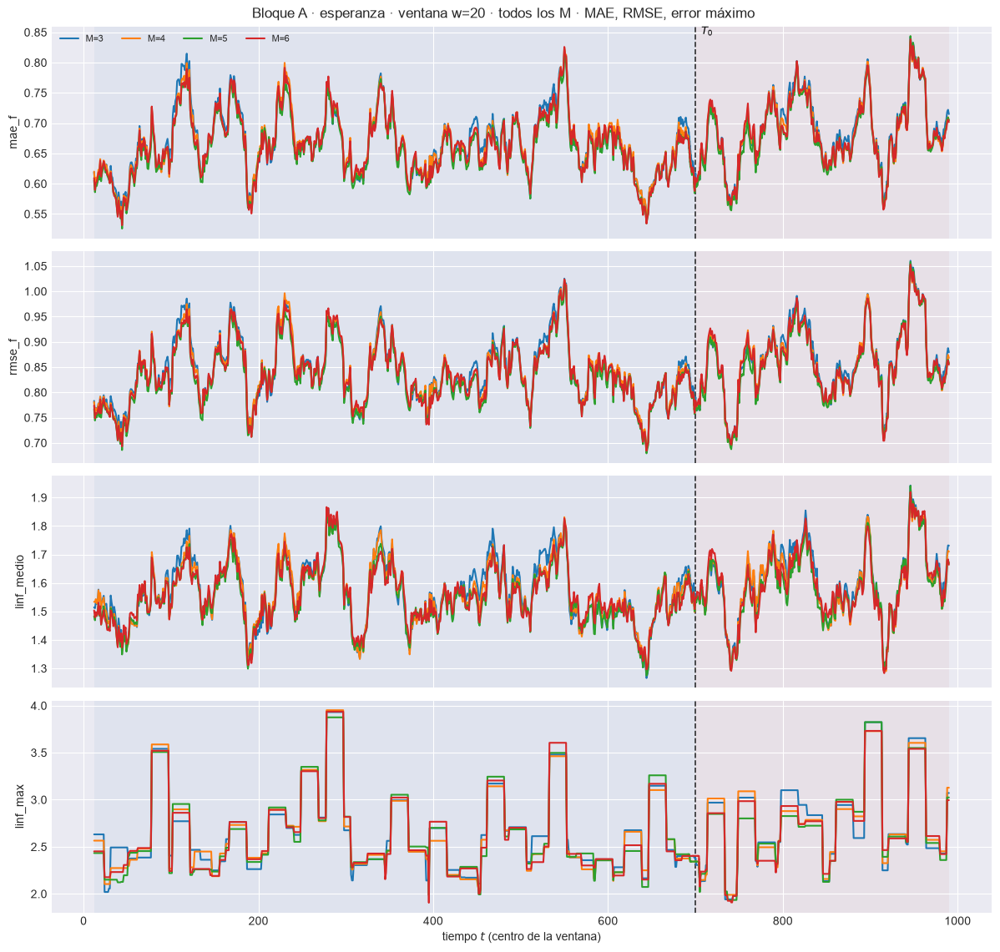

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.6644  w=30 test=0.6852


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8376  w=30 test=0.8561


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.554  w=30 test=1.599


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.693  w=30 test=2.933


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_barrido_M\85_bloqueA_w30.png


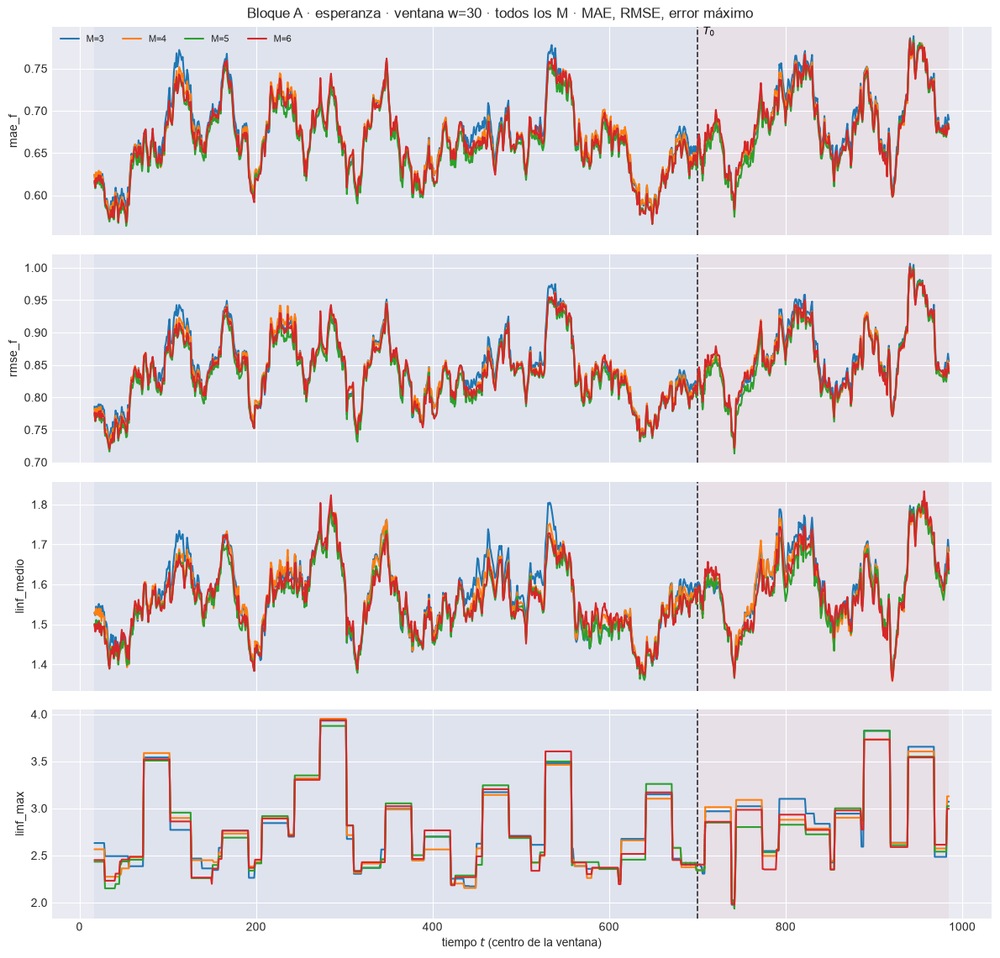

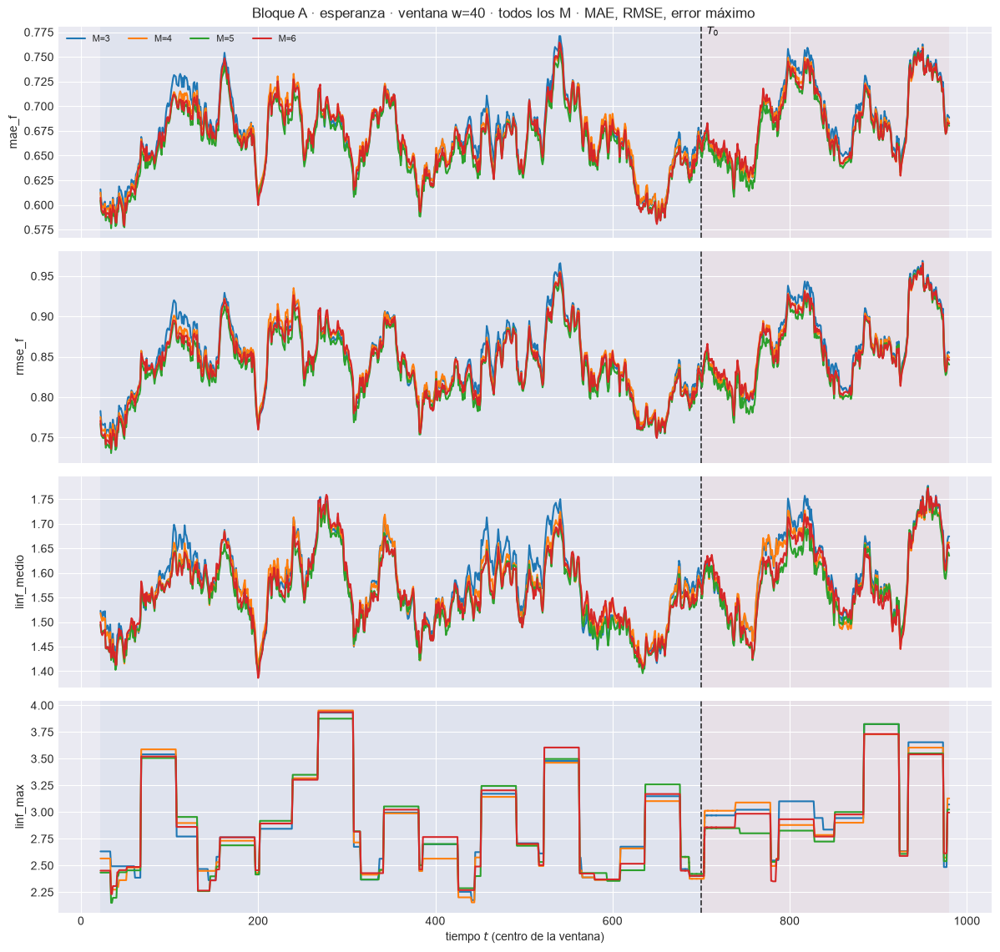

In [9]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

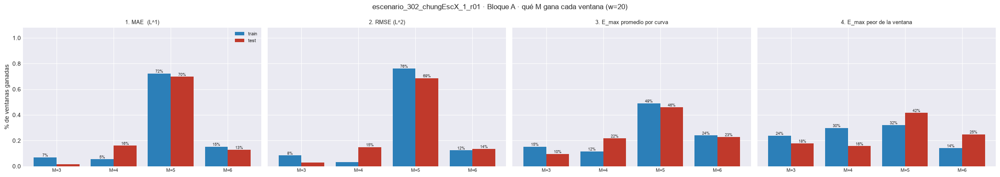

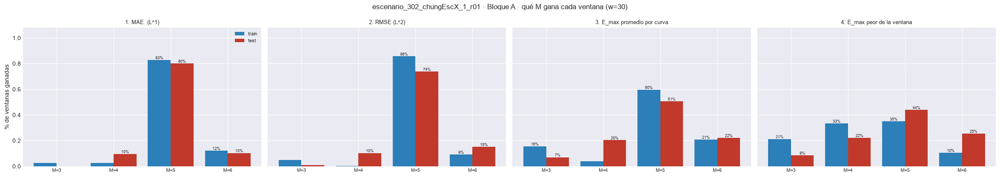

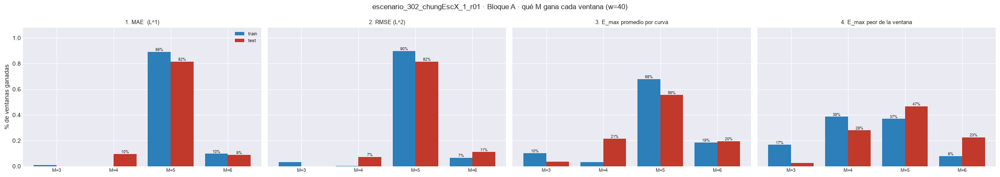

In [10]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [11]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,3,4,5,6
predictor,,,,
esperanza,55.7%,48.7%,47.6%,47.2%
mediana,8.1%,14.8%,13.3%,25.5%
medoide,18.1%,9.6%,19.6%,5.9%
modal,18.1%,26.9%,19.6%,21.4%


M,3,4,5,6
predictor,,,,
esperanza,60.9%,47.2%,57.2%,48.3%
mediana,3.0%,23.6%,14.4%,29.9%
medoide,12.5%,12.5%,14.0%,8.1%
modal,23.6%,16.6%,14.4%,13.7%


M,3,4,5,6
predictor,,,,
esperanza,32.8%,44.6%,38.7%,42.4%
mediana,6.3%,12.9%,15.5%,22.9%
medoide,24.7%,19.2%,6.6%,9.6%
modal,36.2%,23.2%,39.1%,25.1%


M,3,4,5,6
predictor,,,,
esperanza,39.5%,35.8%,45.4%,22.1%
mediana,1.5%,17.7%,15.1%,10.0%
medoide,39.5%,36.2%,23.6%,50.9%
modal,19.6%,10.3%,15.9%,17.0%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

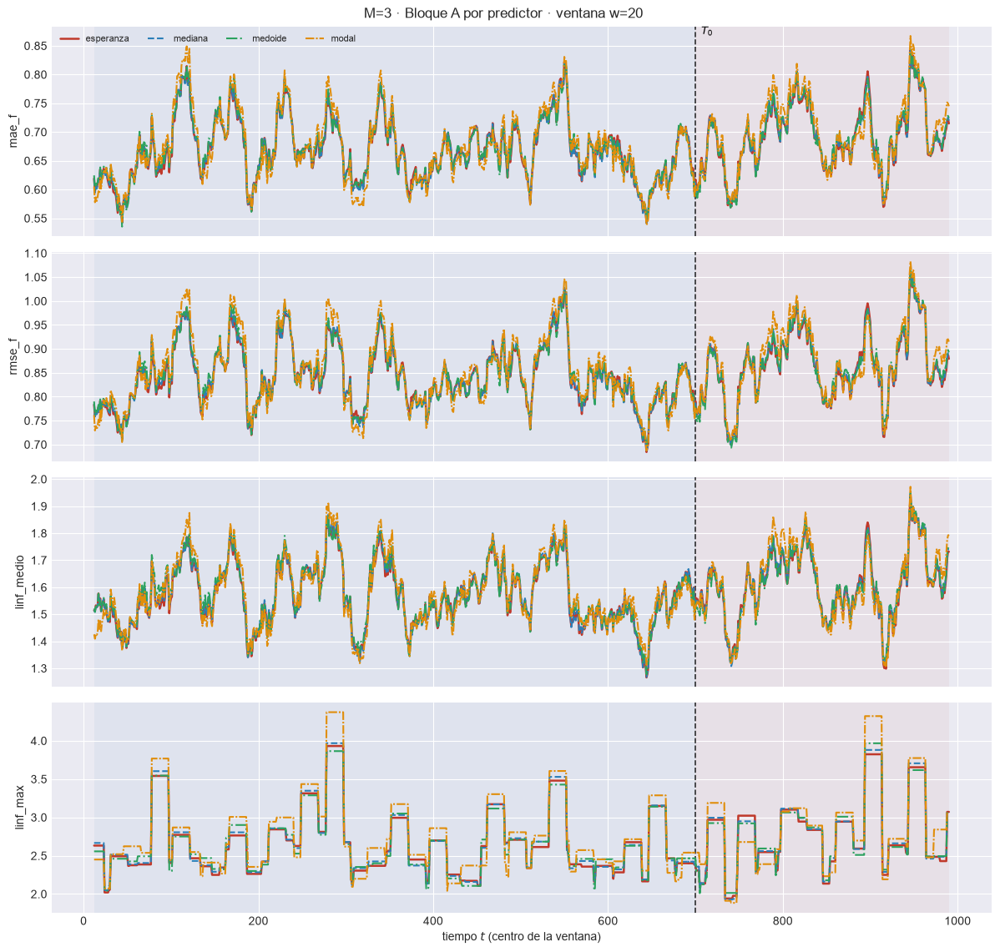

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.6701  w=30 test=0.6931


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8434  w=30 test=0.8645


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.569  w=30 test=1.61


  4/4 (100.0%) t=0.0s eta=0.0s  linf_max: w=30 train=2.71  w=30 test=2.969


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m03\58_ventana_predictores_w30.png


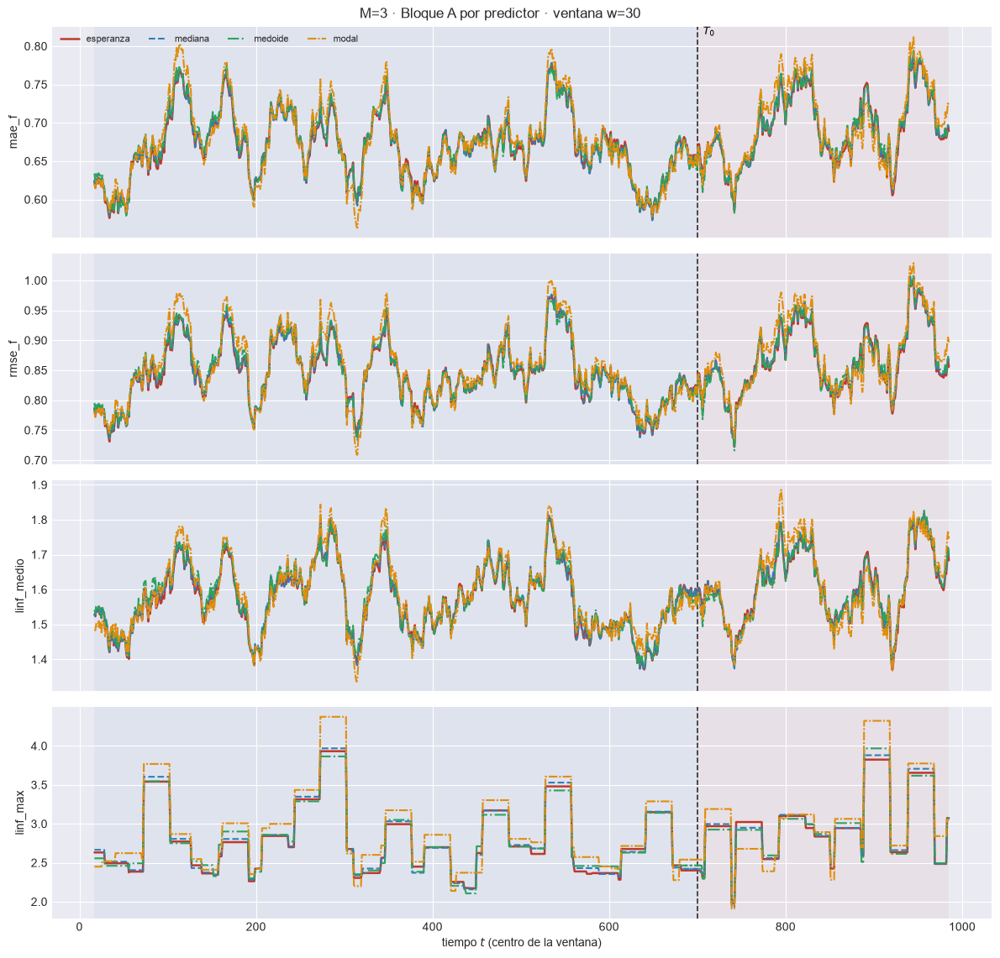

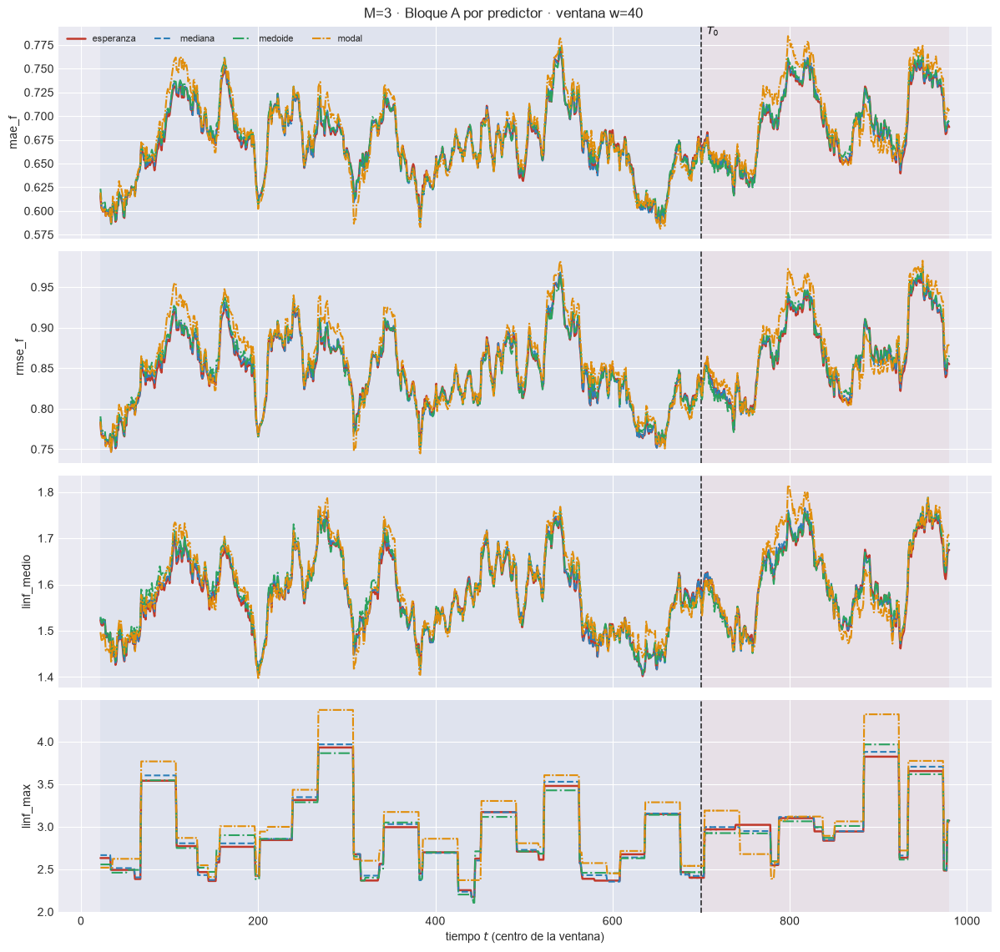

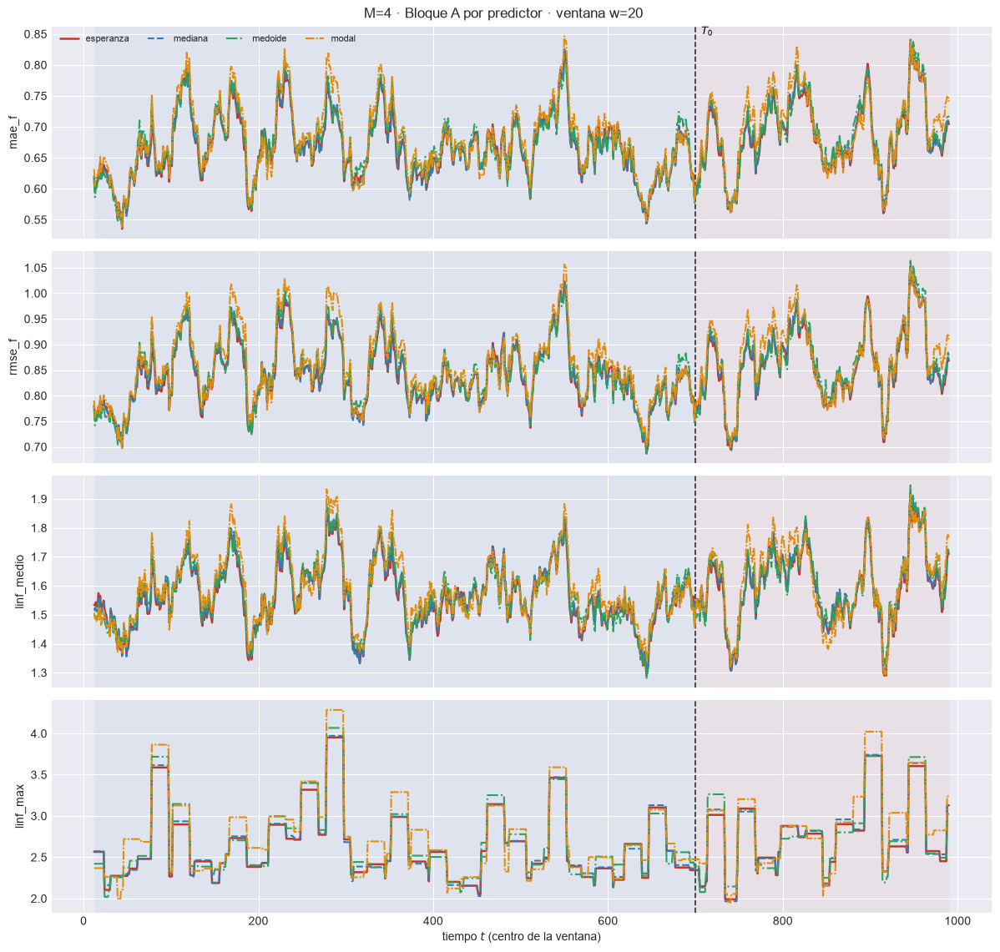

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.6695  w=30 test=0.6907


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8443  w=30 test=0.866


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.566  w=30 test=1.615


  4/4 (100.0%) t=0.0s eta=0.0s  linf_max: w=30 train=2.698  w=30 test=2.922


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m04\58_ventana_predictores_w30.png


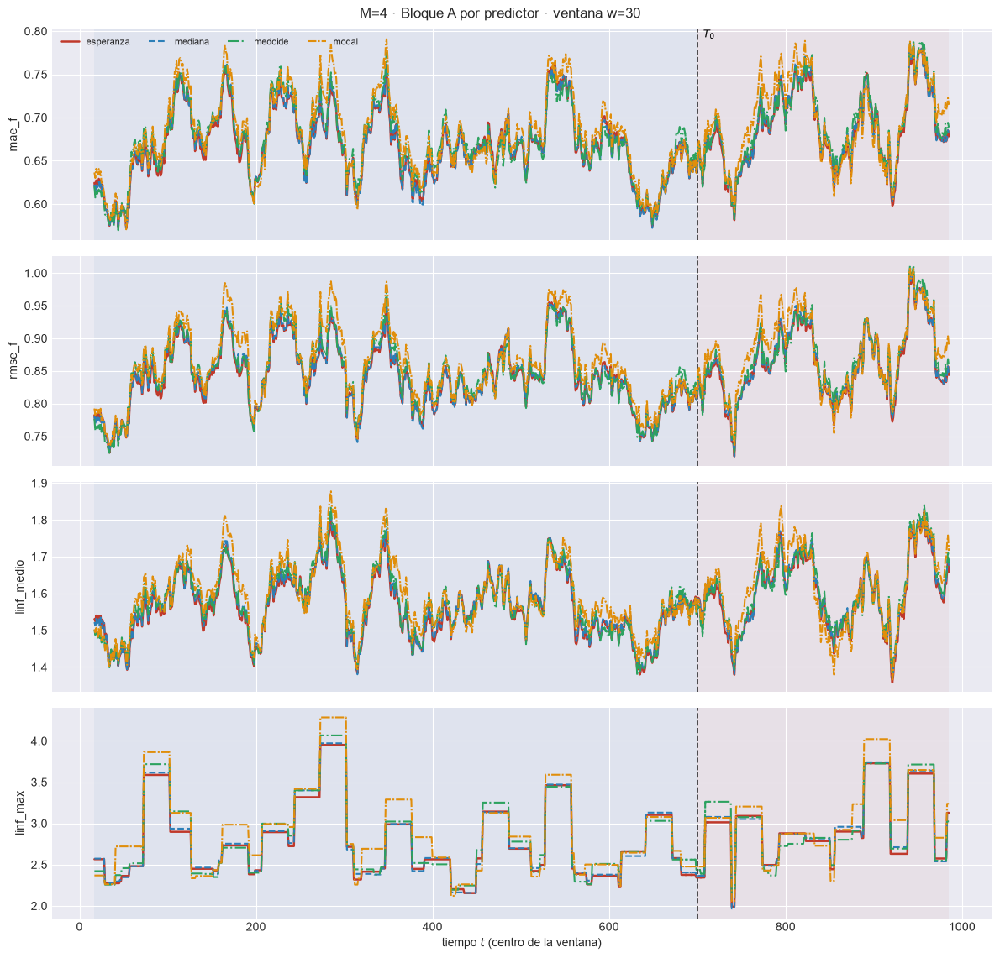

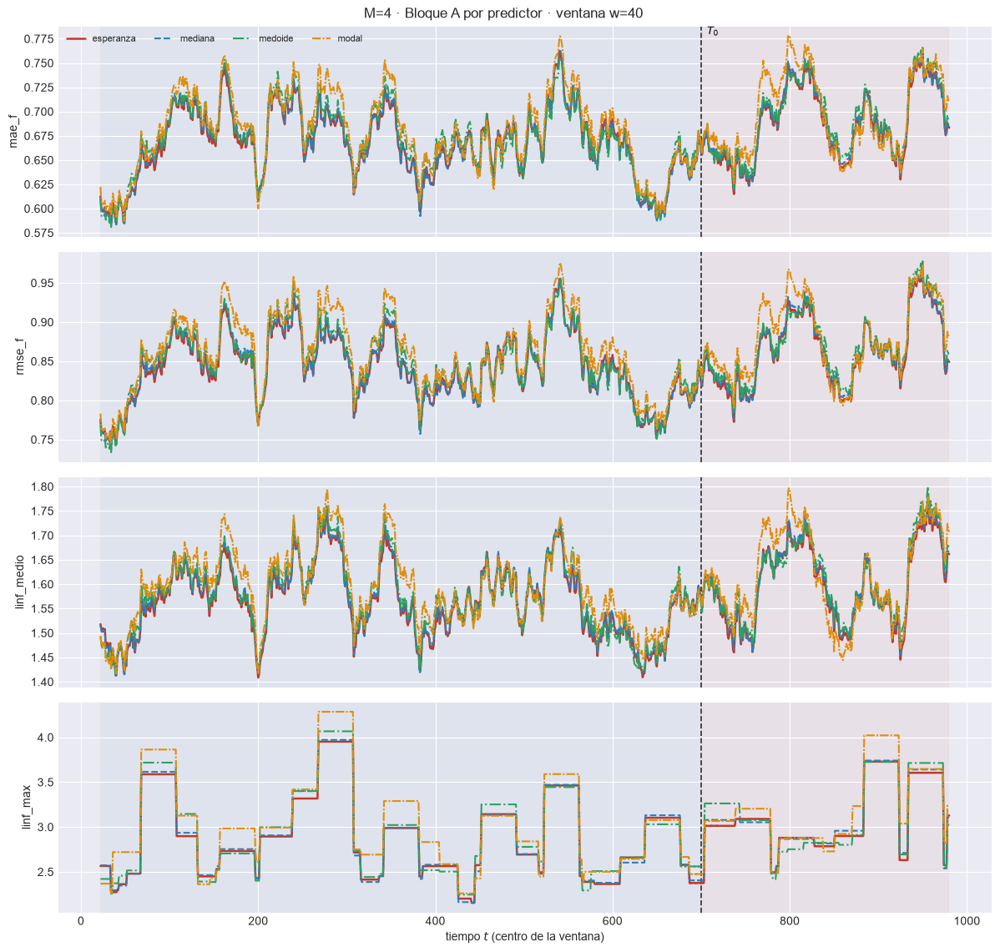

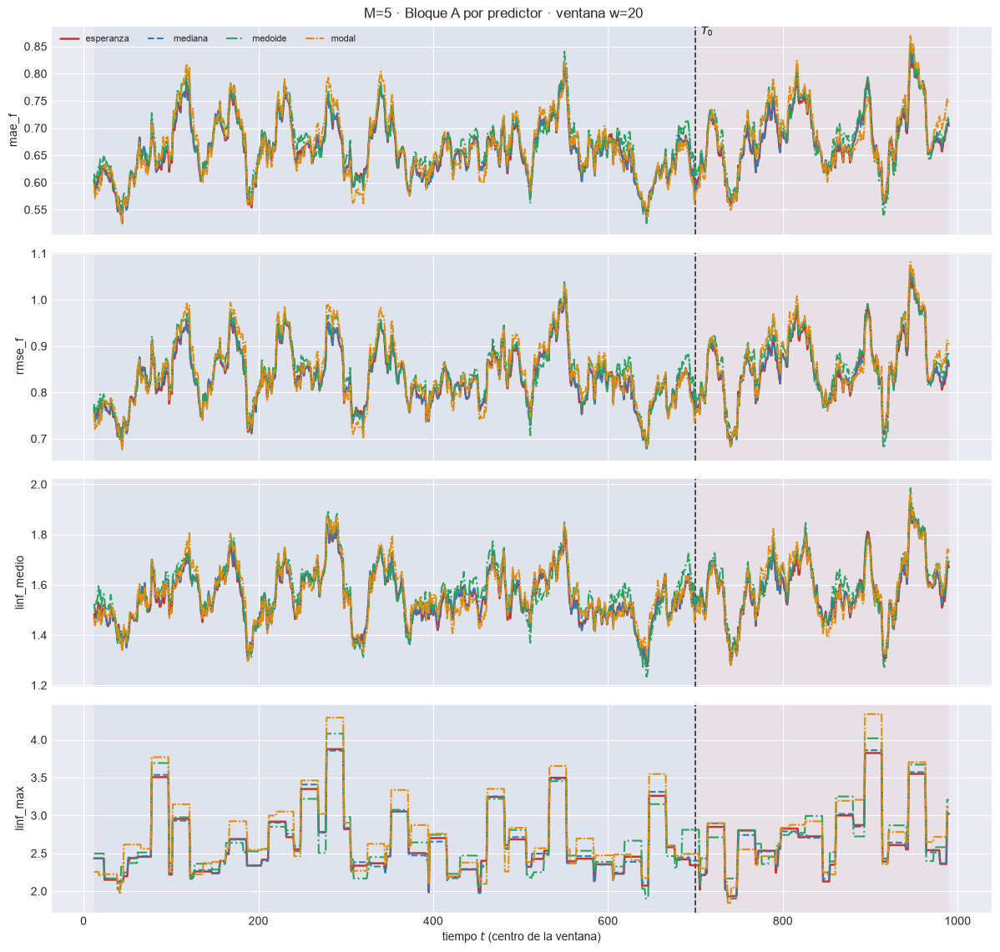

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.6616  w=30 test=0.6848


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8349  w=30 test=0.8579


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.554  w=30 test=1.594


  4/4 (100.0%) t=0.0s eta=0.0s  linf_max: w=30 train=2.696  w=30 test=2.849


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m05\58_ventana_predictores_w30.png


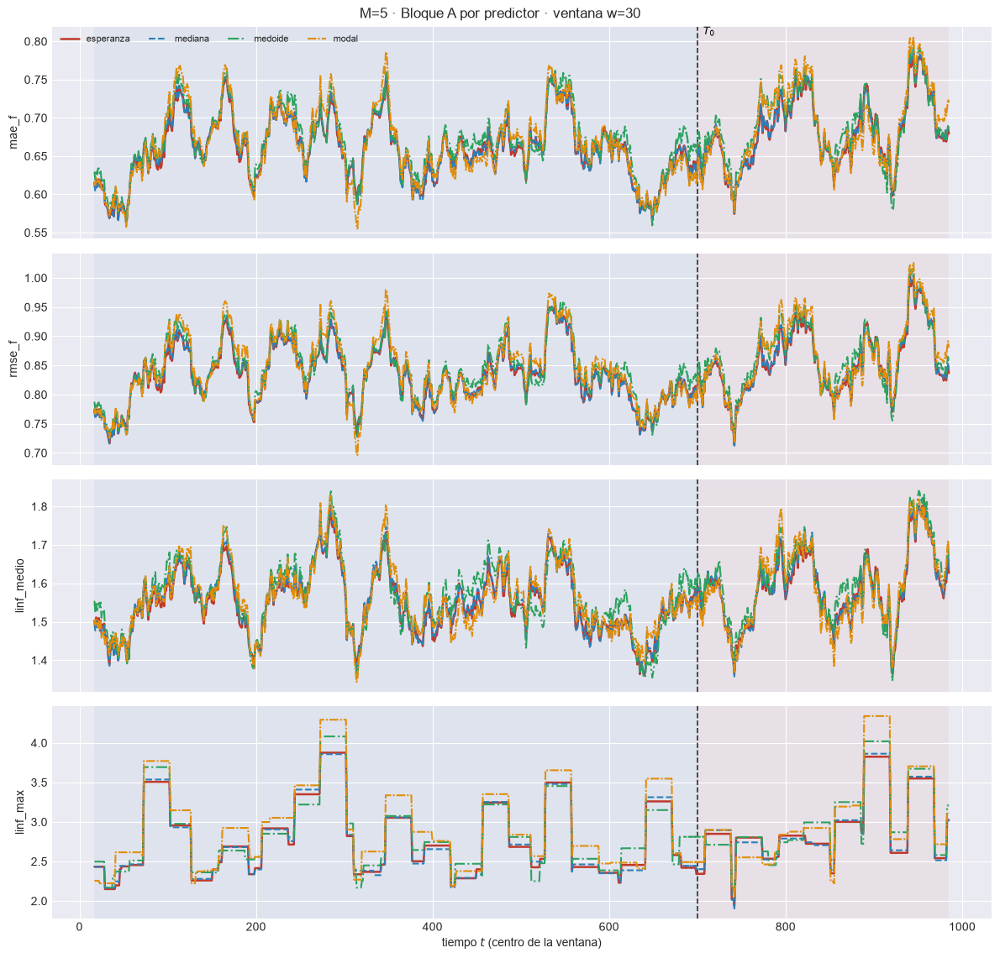

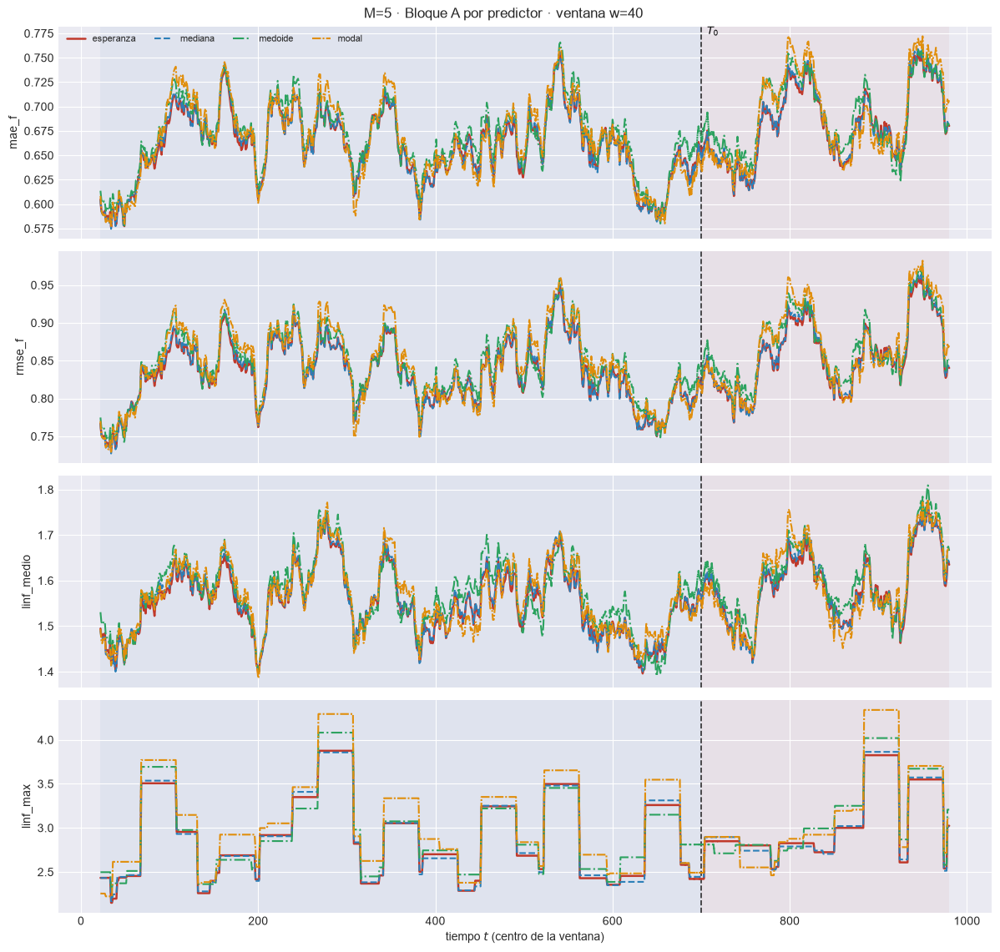

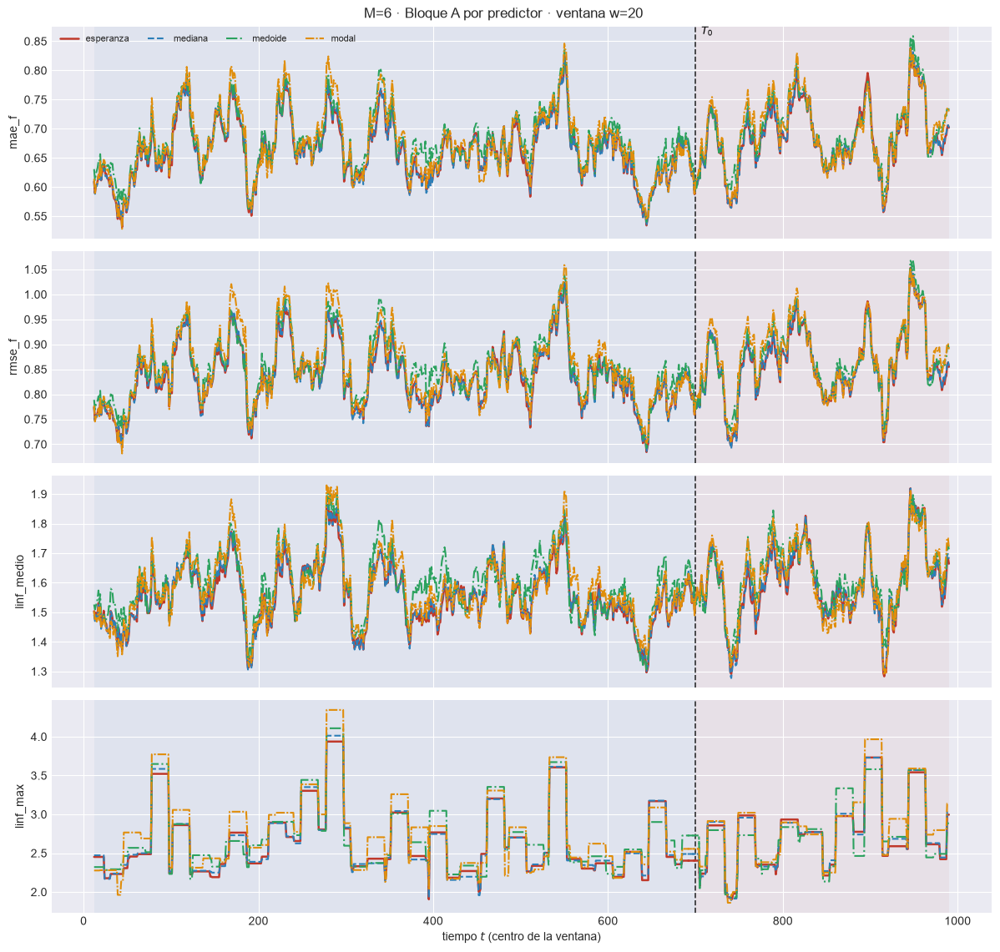

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.6689  w=30 test=0.6905


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8444  w=30 test=0.865


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.567  w=30 test=1.606


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.747  w=30 test=2.902


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m06\58_ventana_predictores_w30.png


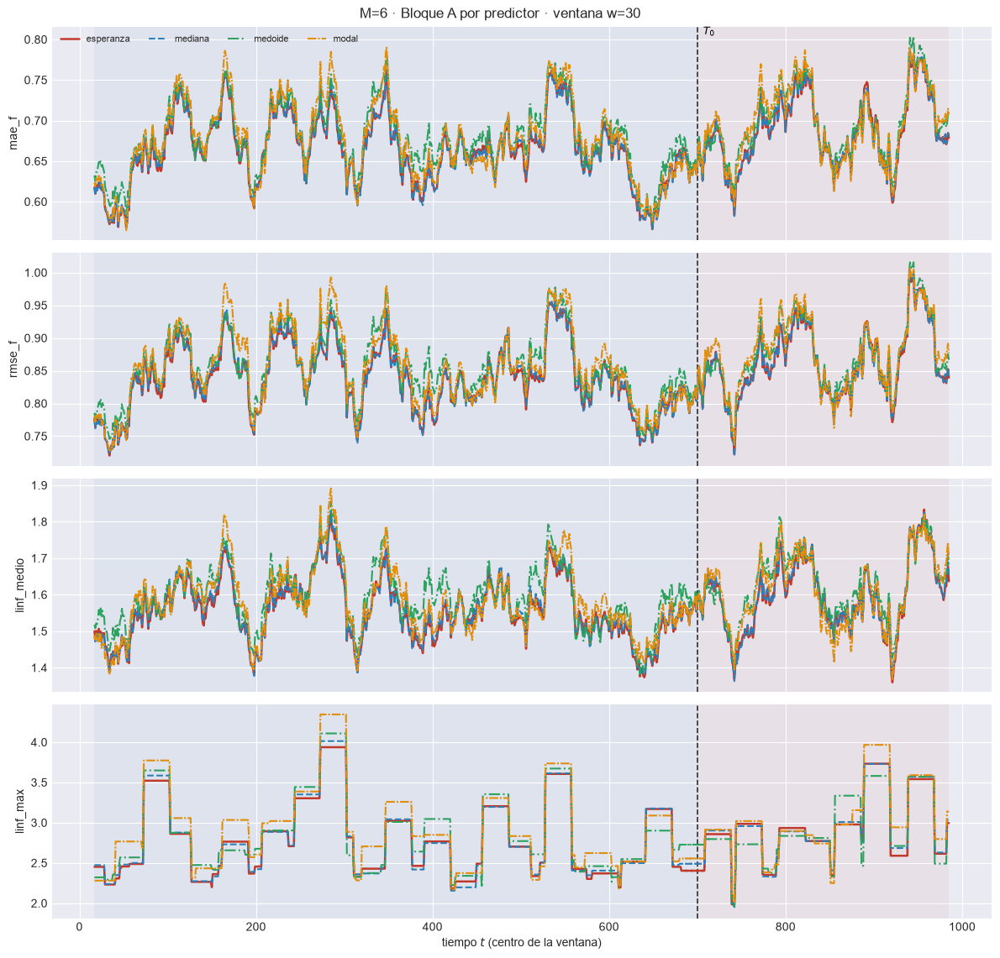

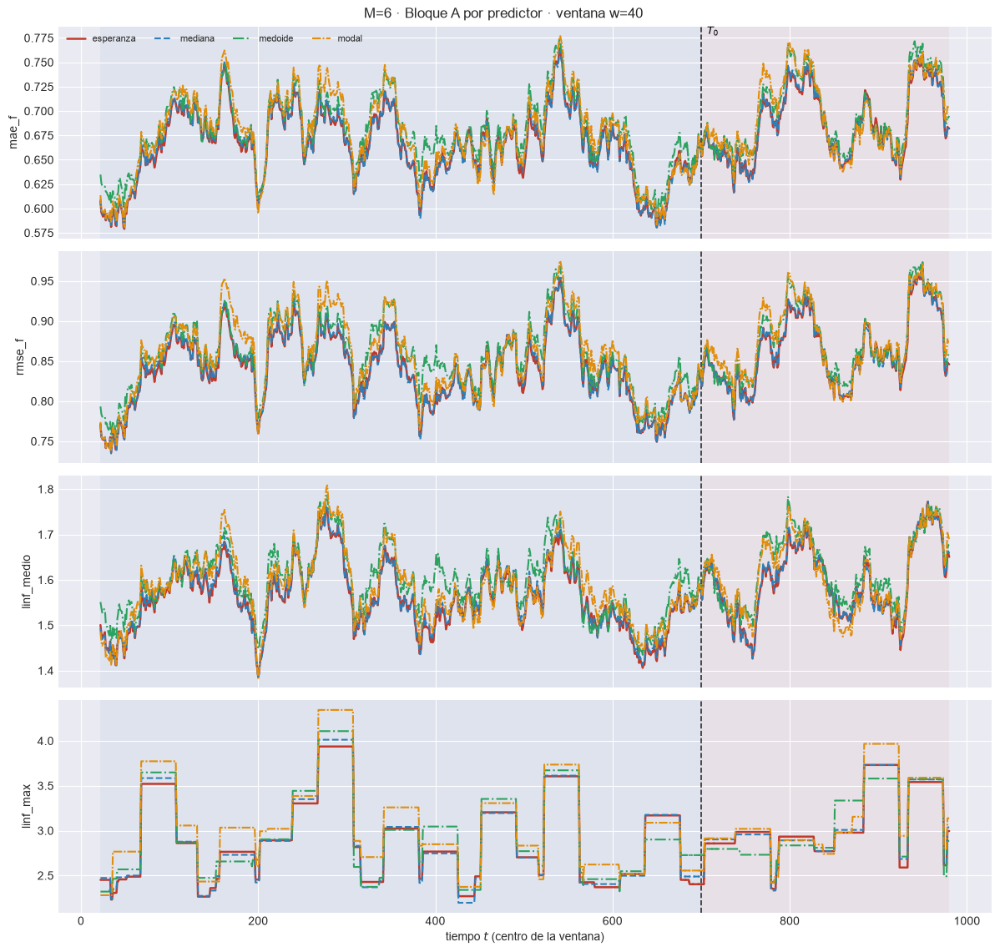

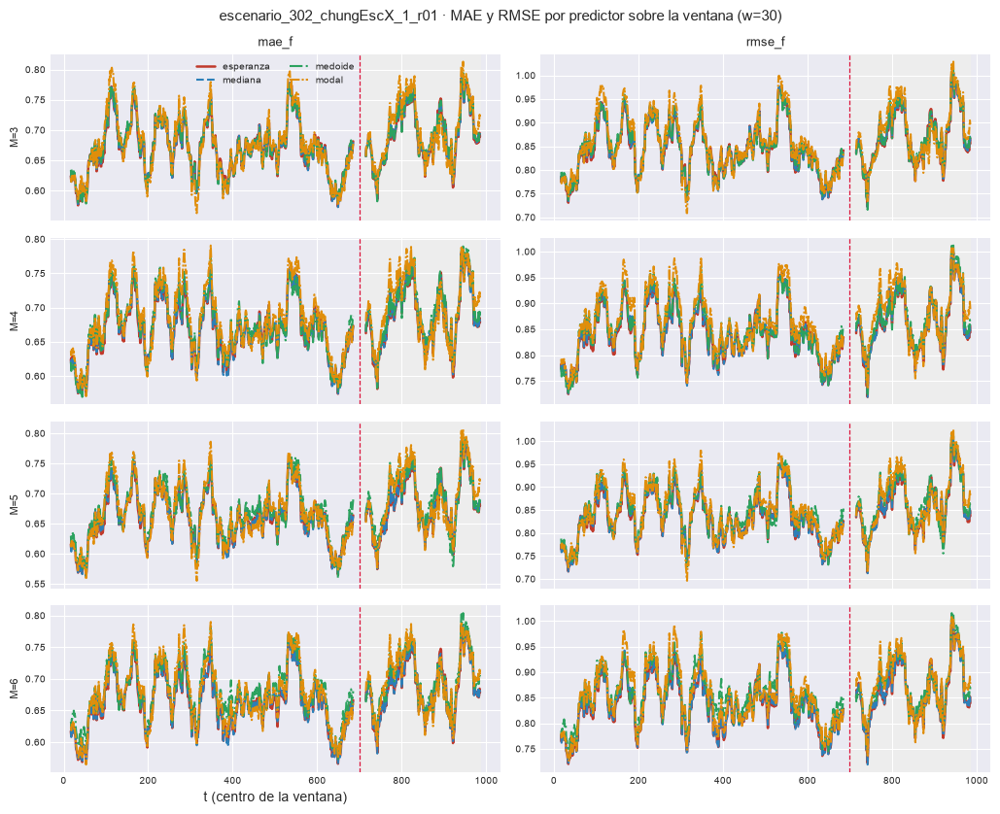

In [12]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        tp = filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas")
        tp.attrs["w"] = w
        plot_ventana_movil(
            tp, T0, METRICAS_A_COLS, columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

plot_ventana_grupos_por_M(
    {M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
    ["mae_f", "rmse_f"], "predictor", T0, ESTILOS_PREDICTORES,
    f"{EXPERIMENT_BASE} · MAE y RMSE por predictor sobre la ventana (w={W_REF})",
    PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

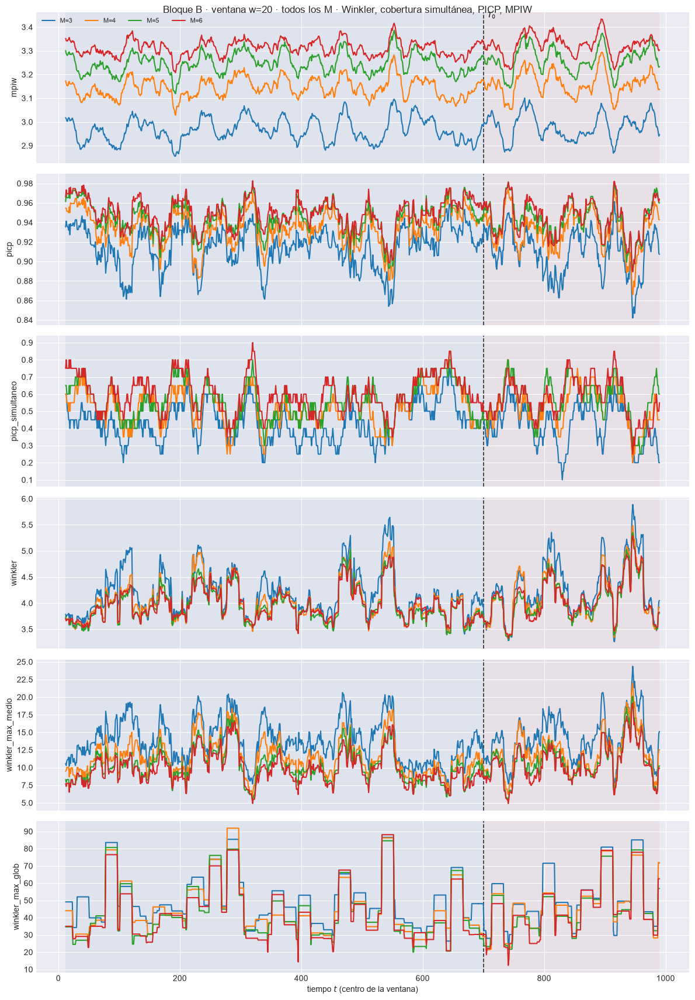

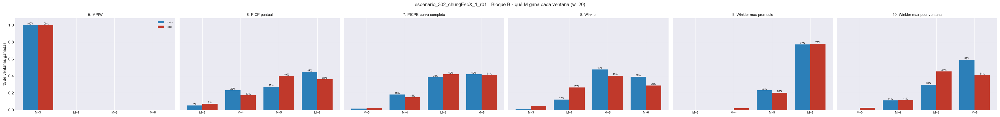

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.198  w=30 test=3.21


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9382  w=30 test=0.9342


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.5333  w=30 test=0.5333


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=3.955  w=30 test=4.055


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=10.8  w=30 test=11.66


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=46.93  w=30 test=51.32


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_barrido_M\86_bloqueB_w30.png


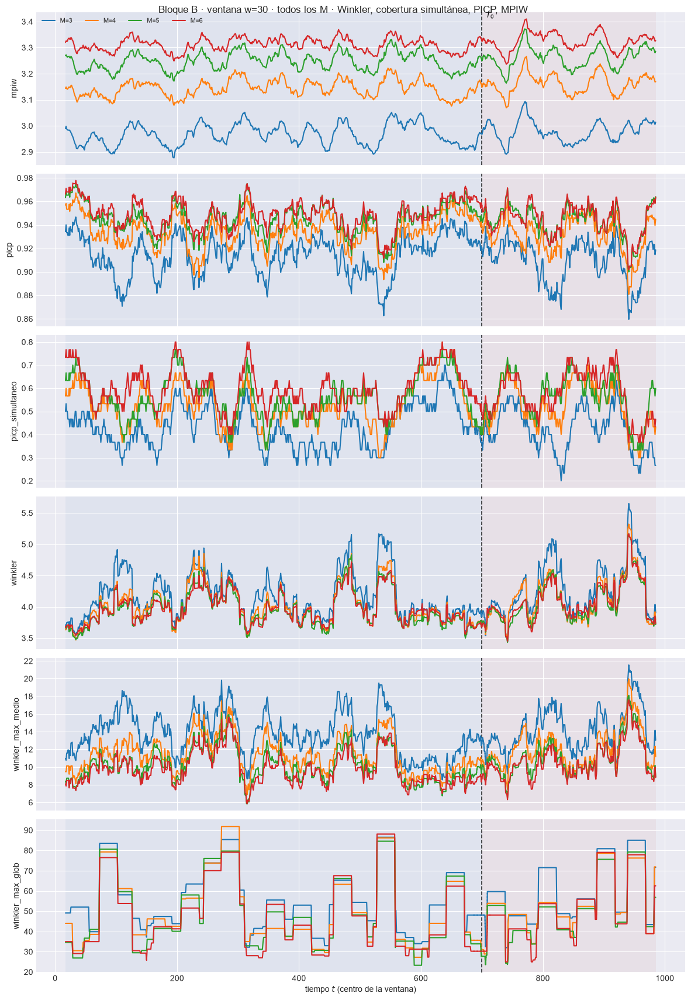

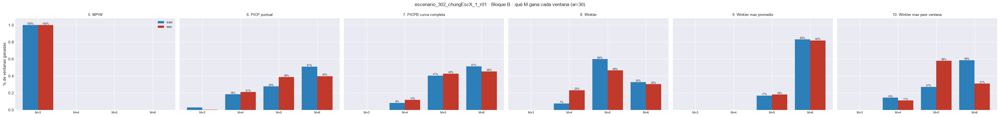

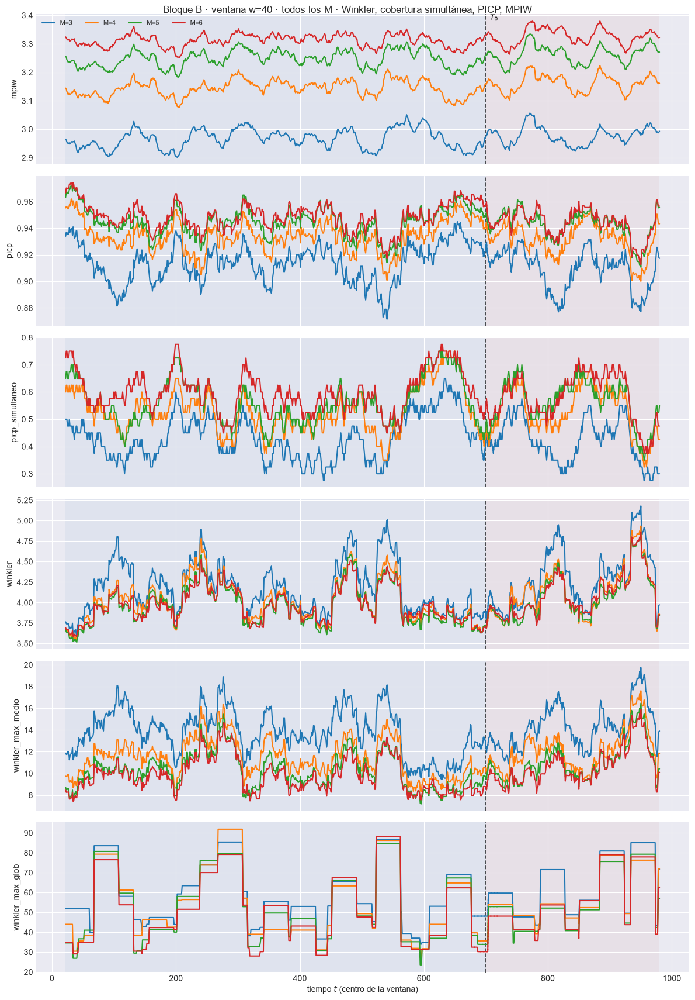

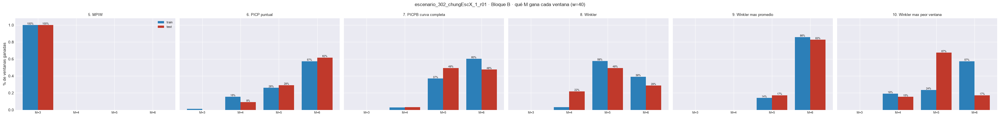

In [13]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

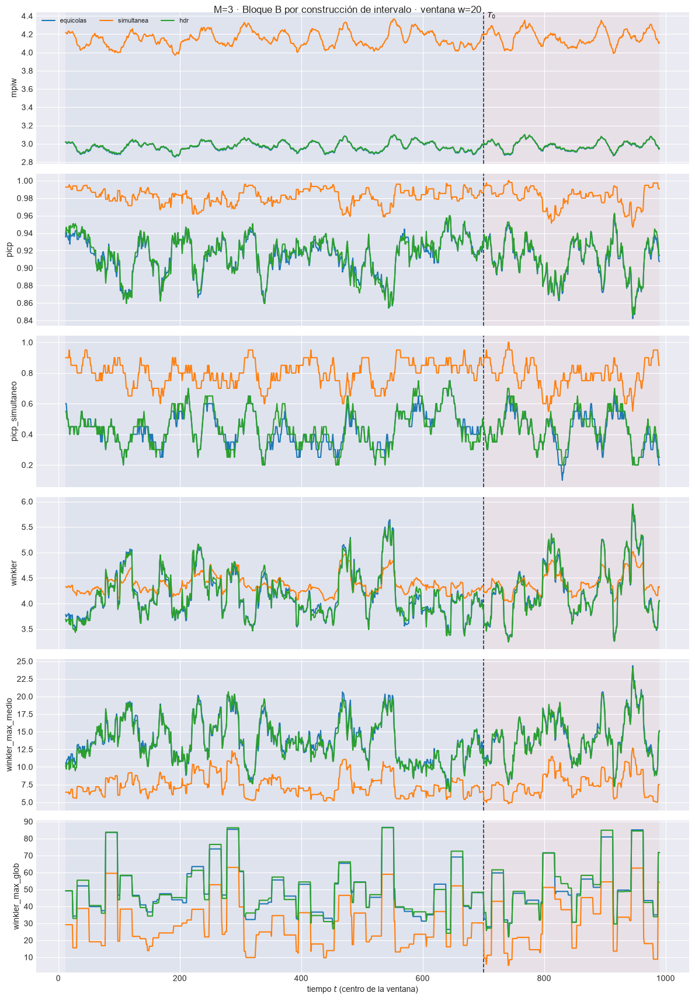

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=2.999  w=30 test=3.01


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9271  w=30 test=0.9236


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.5  w=30 test=0.5


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=4.26  w=30 test=4.313


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=11.85  w=30 test=12.49


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=47.41  w=30 test=51.14


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m03\59_ventana_intervalos_w30.png


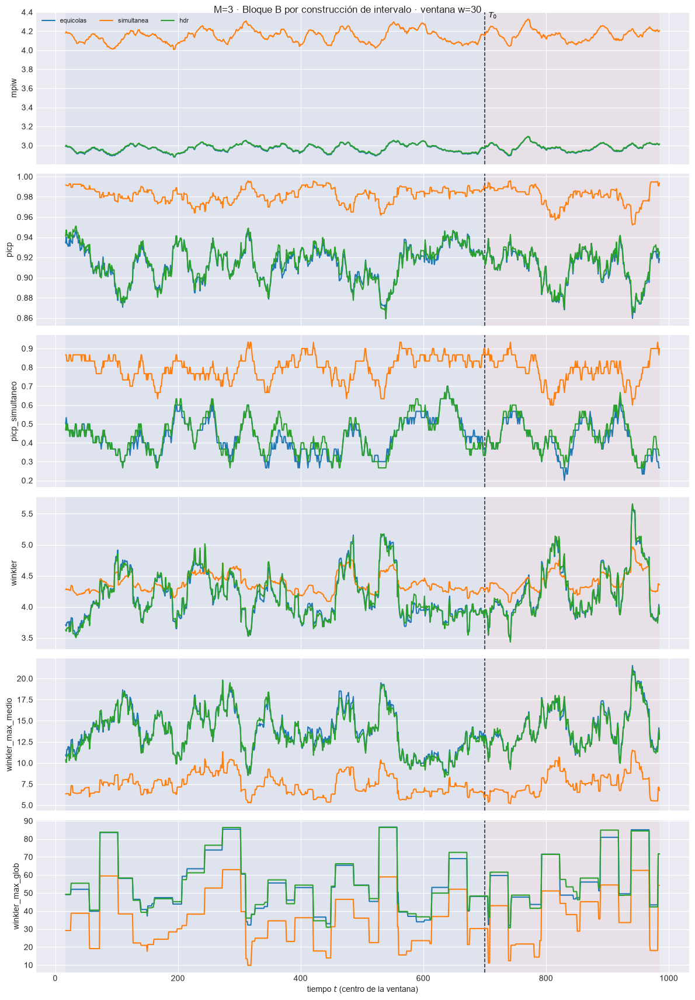

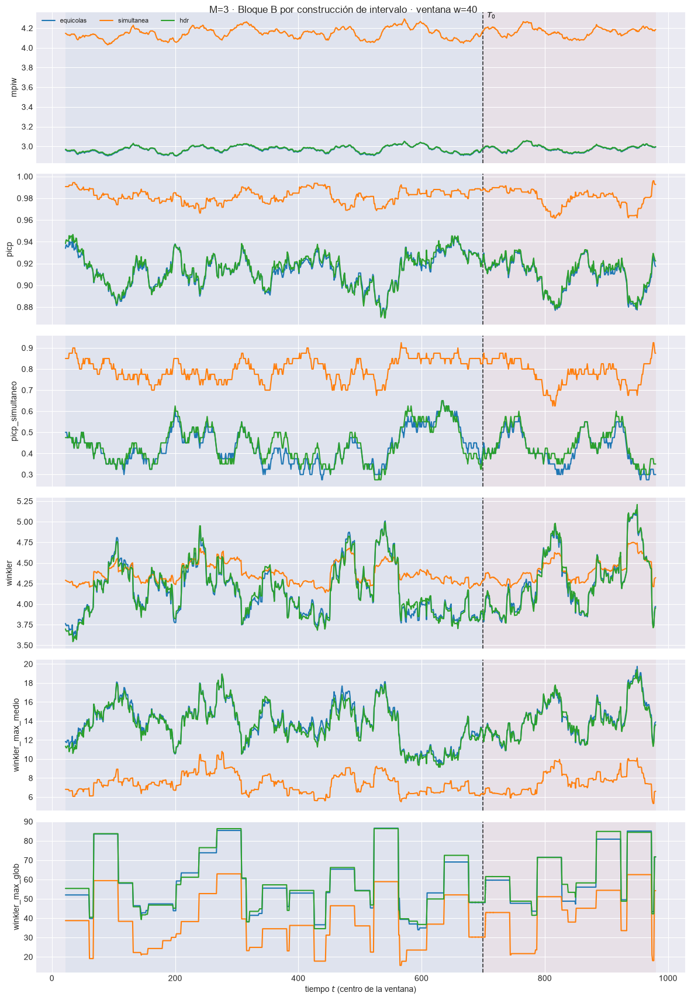

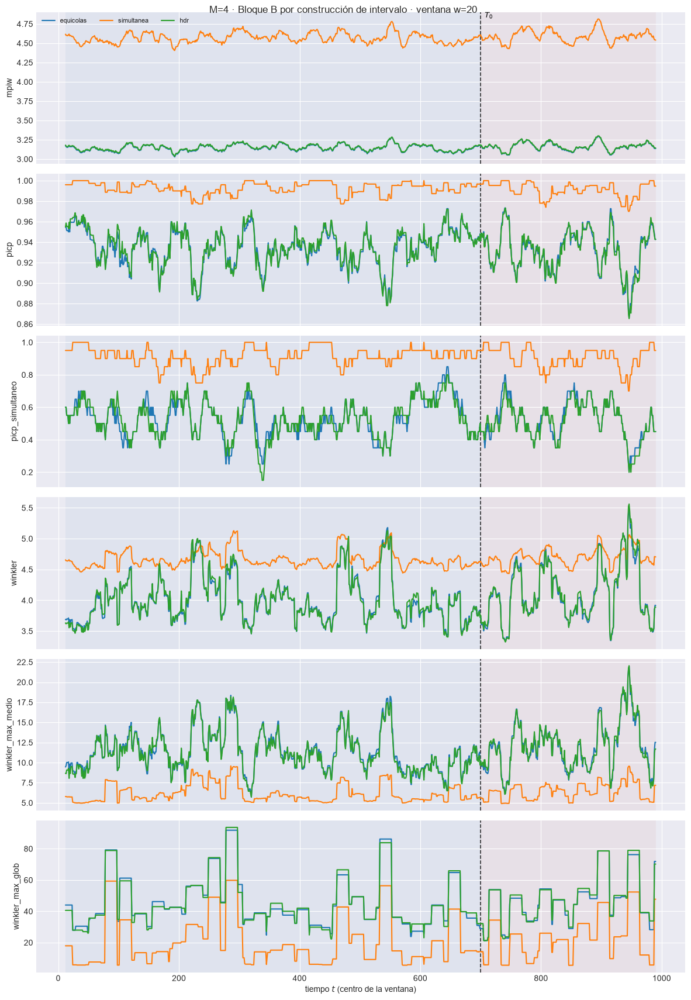

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.168  w=30 test=3.193


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9444  w=30 test=0.944


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.6  w=30 test=0.6


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=4.196  w=30 test=4.43


  5/6 (83.3%) t=0.0s eta=0.0s  winkler_max_medio: w=30 train=9.782  w=30 test=10.49


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=41.41  w=30 test=48.38


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m04\59_ventana_intervalos_w30.png


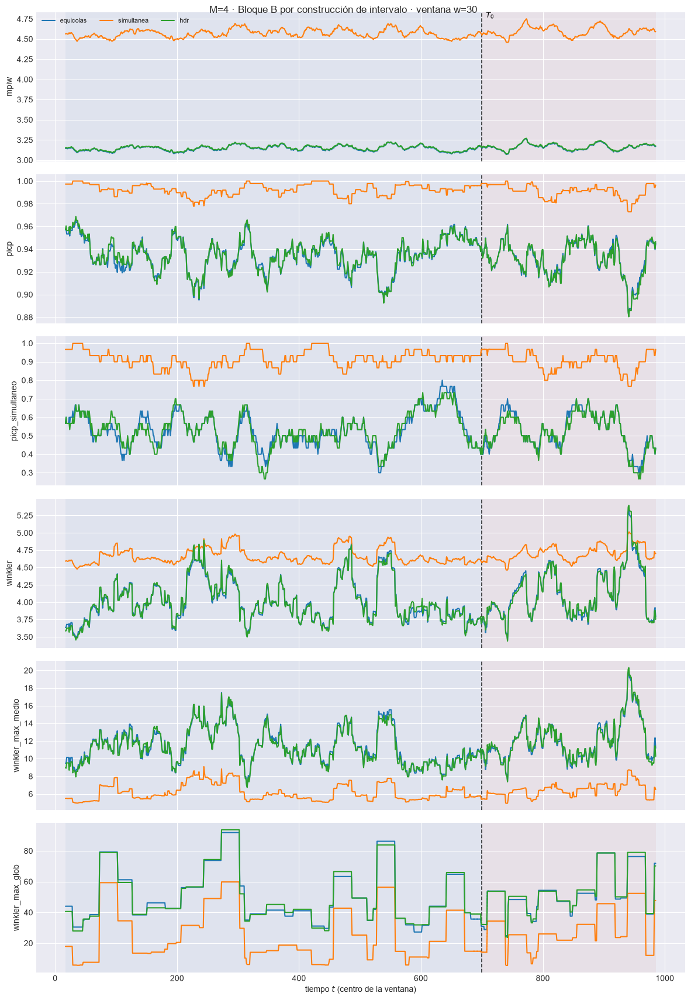

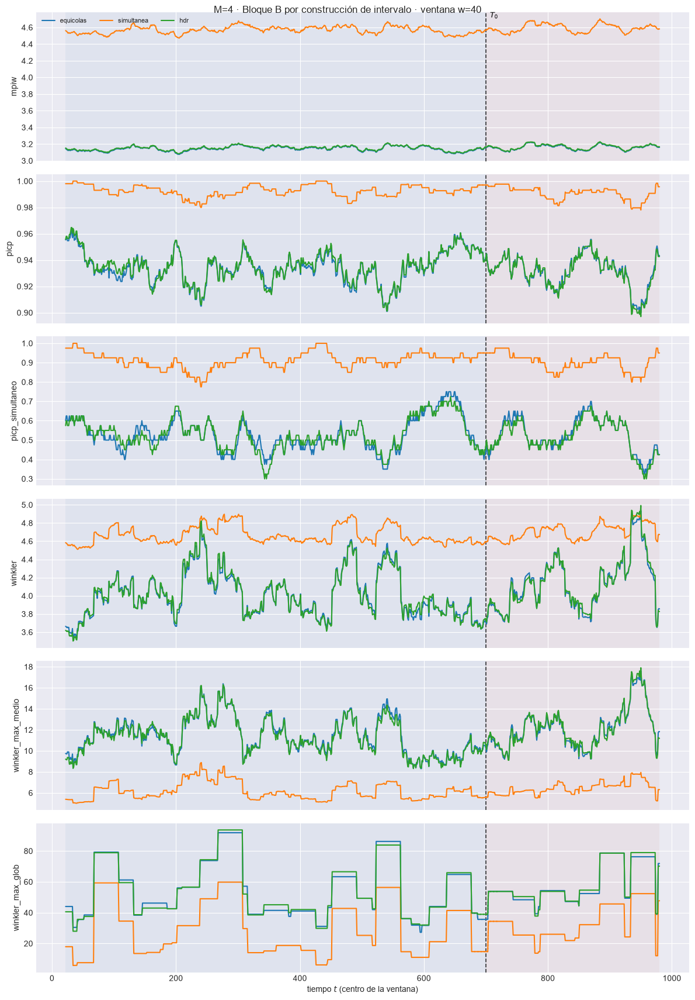

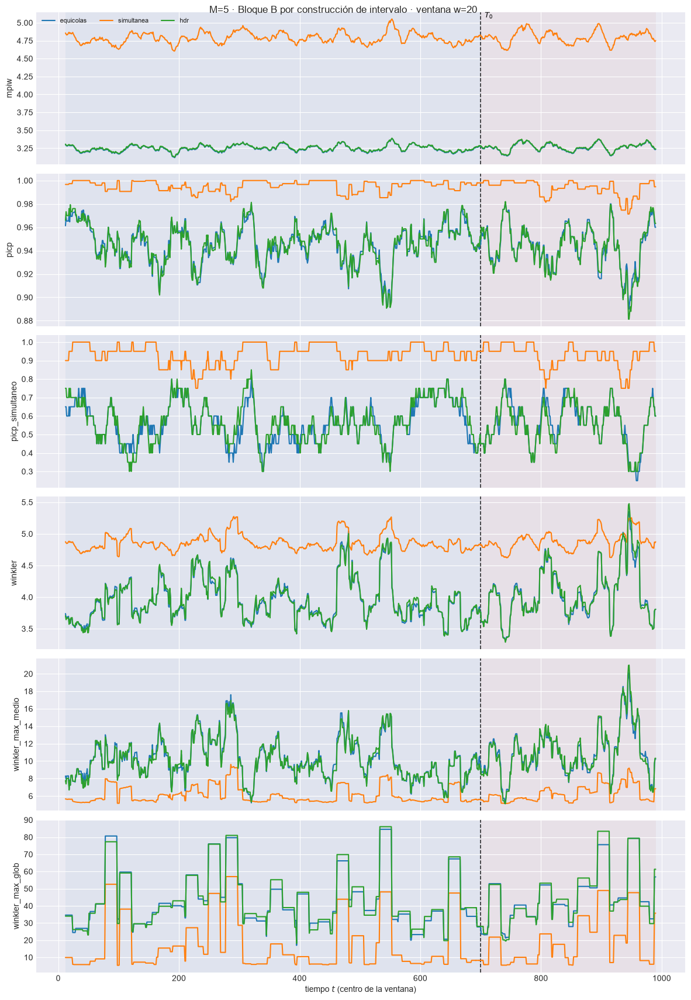

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.273  w=30 test=3.297


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9547  w=30 test=0.9524


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.6333  w=30 test=0.6333


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=4.109  w=30 test=4.326


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.743  w=30 test=9.716


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=38.92  w=30 test=43.68


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m05\59_ventana_intervalos_w30.png


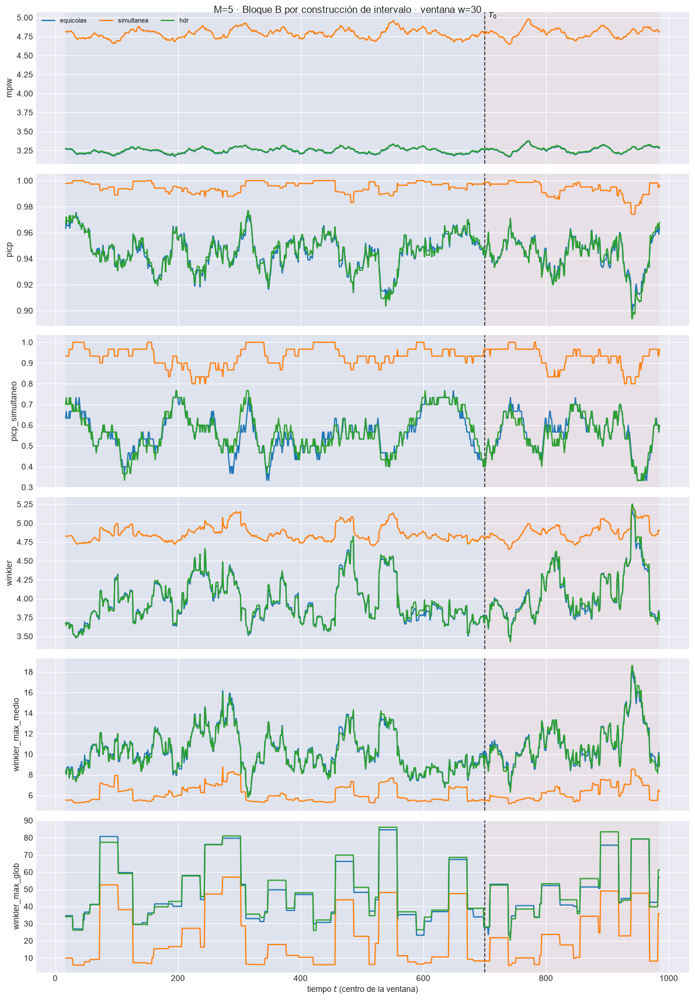

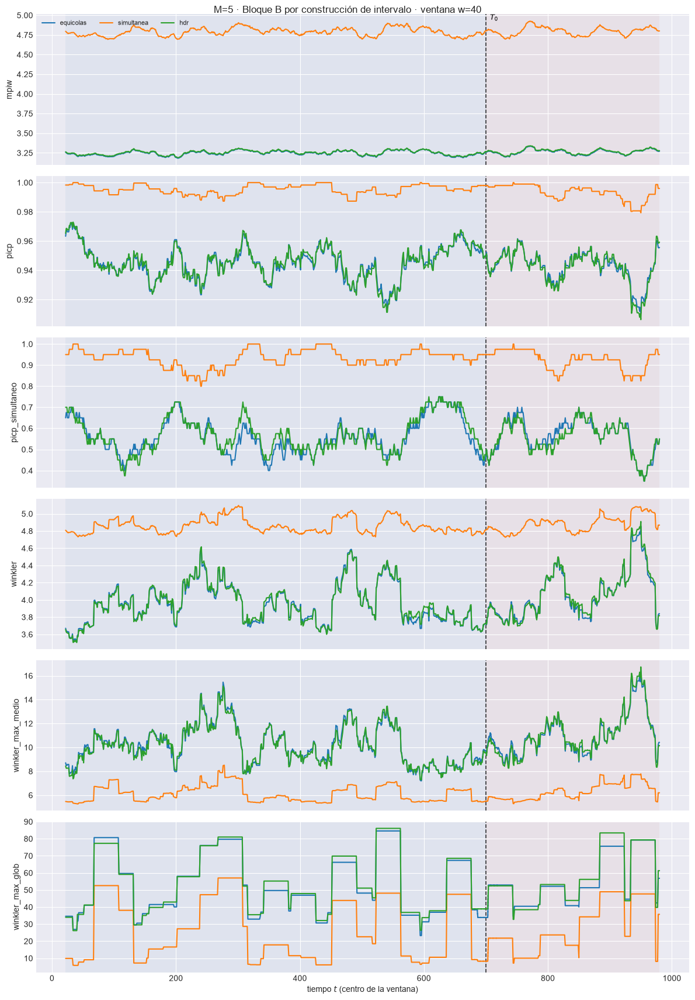

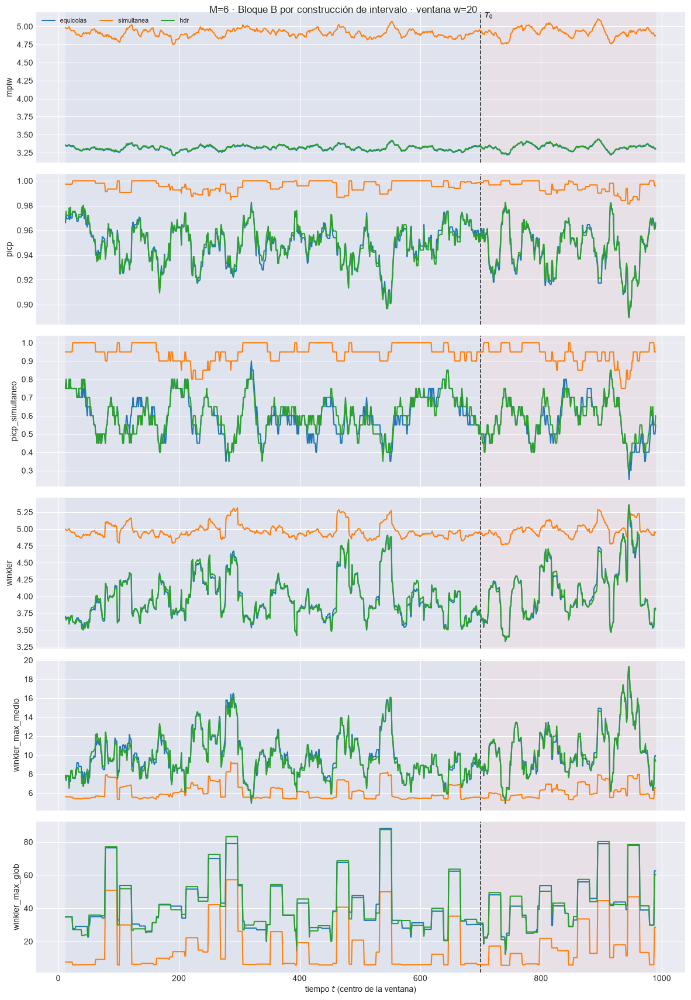

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.333  w=30 test=3.355


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9578  w=30 test=0.9538


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.6667  w=30 test=0.6667


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=4.109  w=30 test=4.339


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.464  w=30 test=9.358


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=35.92  w=30 test=43.8


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m06\59_ventana_intervalos_w30.png


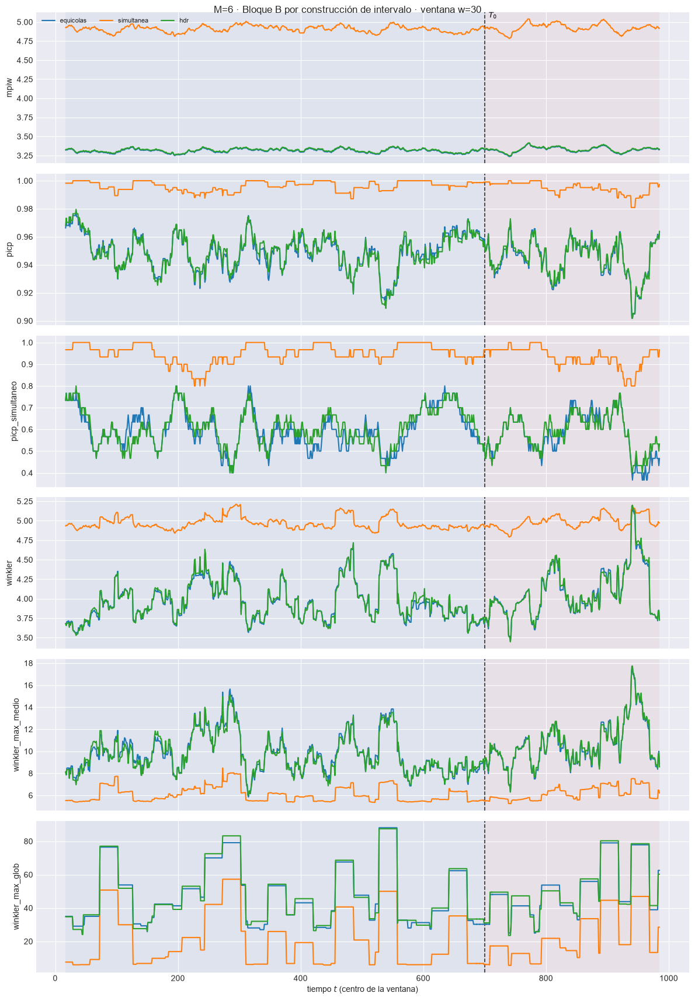

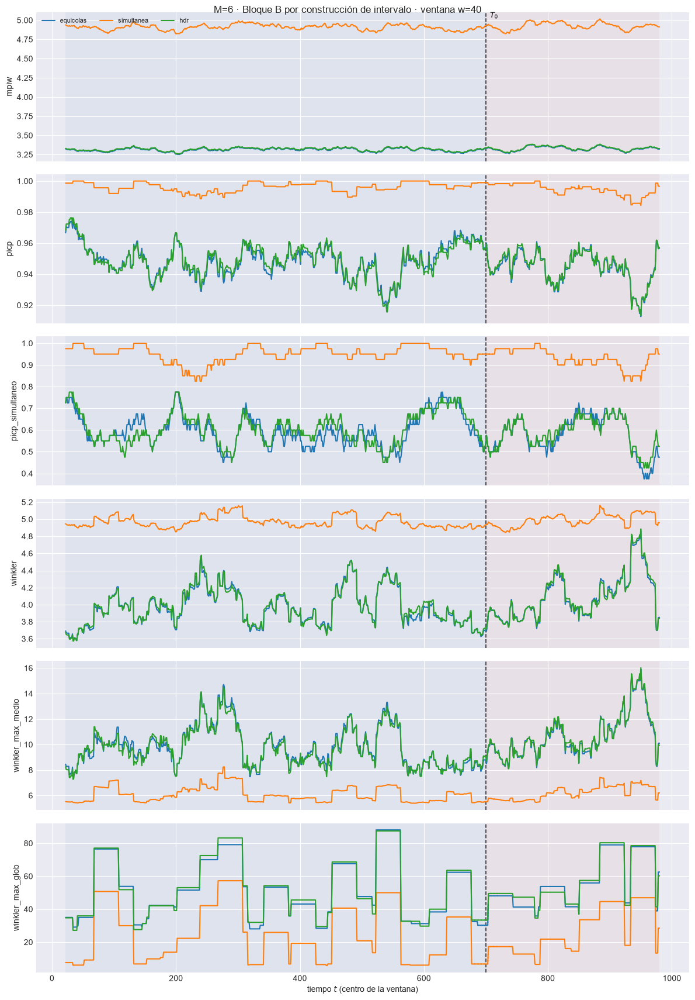

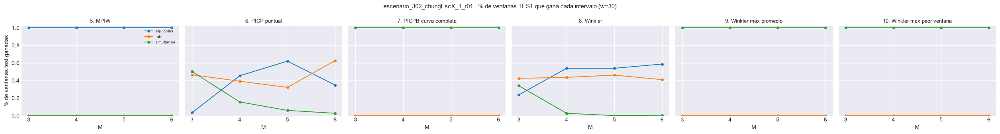

M,3,4,5,6
intervalo,,,,
equicolas,100.0%,100.0%,100.0%,100.0%
simultanea,0.0%,0.0%,0.0%,0.0%
hdr,0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
intervalo,,,,
equicolas,3.3%,45.4%,62.0%,34.7%
simultanea,50.2%,15.5%,5.9%,2.6%
hdr,46.5%,39.1%,32.1%,62.7%


M,3,4,5,6
intervalo,,,,
equicolas,0.0%,0.0%,0.0%,0.0%
simultanea,100.0%,100.0%,100.0%,100.0%
hdr,0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
intervalo,,,,
equicolas,23.6%,53.9%,53.9%,58.7%
simultanea,33.9%,2.6%,0.0%,0.4%
hdr,42.4%,43.5%,46.1%,41.0%


M,3,4,5,6
intervalo,,,,
equicolas,0.0%,0.0%,0.0%,0.0%
simultanea,100.0%,100.0%,100.0%,100.0%
hdr,0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
intervalo,,,,
equicolas,0.0%,0.0%,0.0%,0.0%
simultanea,100.0%,100.0%,100.0%,100.0%
hdr,0.0%,0.0%,0.0%,0.0%


In [14]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        ti = filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza")
        ti.attrs["w"] = w
        plot_ventana_movil(
            ti, T0, METRICAS_B_COLS, columna_grupo="intervalo",
            title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · % de ventanas TEST que gana cada intervalo (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada intervalo (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=776 [test] cob=0.880 rmse=1.045


  2/10 (20.0%) t=0.0s eta=0.0s  t=777 [test] cob=1.000 rmse=0.6204


  3/10 (30.0%) t=0.0s eta=0.0s  t=778 [test] cob=1.000 rmse=0.4278


  4/10 (40.0%) t=0.0s eta=0.0s  t=779 [test] cob=0.893 rmse=0.8648


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=782 [test] cob=0.760 rmse=1.185


  8/10 (80.0%) t=0.0s eta=0.0s  t=783 [test] cob=0.800 rmse=1.03


  9/10 (90.0%) t=0.0s eta=0.0s  t=784 [test] cob=0.853 rmse=1.05


  10/10 (100.0%) t=0.0s eta=0.0s  t=785 [test] cob=1.000 rmse=1.133


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.893 (nominal 0.95)


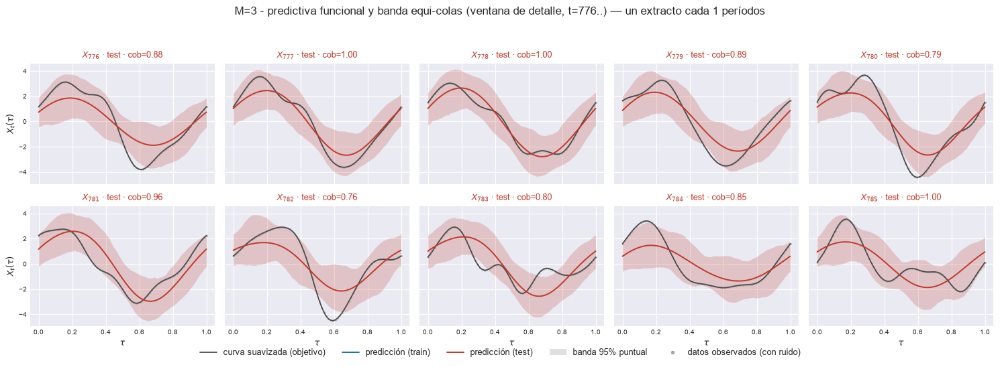

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=776 [test] cob=0.893 rmse=0.9885


  2/10 (20.0%) t=0.0s eta=0.0s  t=777 [test] cob=1.000 rmse=0.6658


  3/10 (30.0%) t=0.0s eta=0.0s  t=778 [test] cob=1.000 rmse=0.4318


  4/10 (40.0%) t=0.0s eta=0.0s  t=779 [test] cob=0.893 rmse=0.8863


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=782 [test] cob=0.853 rmse=1.185


  8/10 (80.0%) t=0.0s eta=0.0s  t=783 [test] cob=0.827 rmse=1


  9/10 (90.0%) t=0.0s eta=0.0s  t=784 [test] cob=0.920 rmse=0.9917


  10/10 (100.0%) t=0.0s eta=0.0s  t=785 [test] cob=1.000 rmse=1.101


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.915 (nominal 0.95)


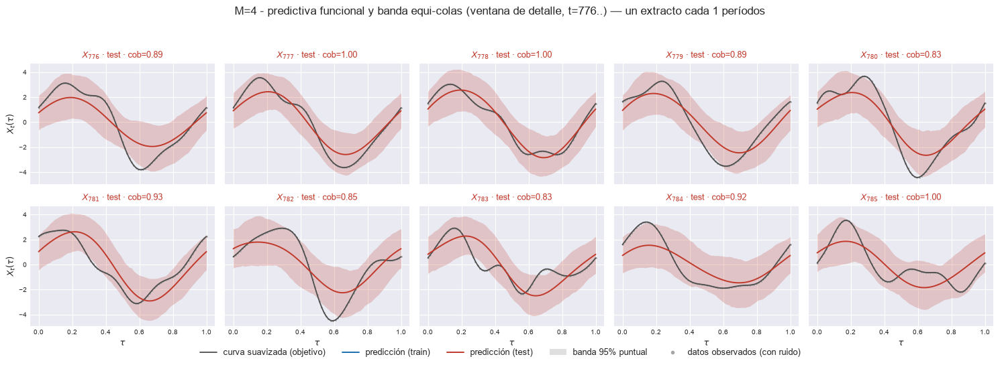

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=776 [test] cob=0.893 rmse=0.9981


  2/10 (20.0%) t=0.0s eta=0.0s  t=777 [test] cob=1.000 rmse=0.6012


  3/10 (30.0%) t=0.0s eta=0.0s  t=778 [test] cob=1.000 rmse=0.3822


  4/10 (40.0%) t=0.0s eta=0.0s  t=779 [test] cob=0.933 rmse=0.8999


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=782 [test] cob=0.880 rmse=1.207


  8/10 (80.0%) t=0.0s eta=0.0s  t=783 [test] cob=0.827 rmse=0.9741


  9/10 (90.0%) t=0.0s eta=0.0s  t=784 [test] cob=0.987 rmse=1.064


  10/10 (100.0%) t=0.0s eta=0.0s  t=785 [test] cob=1.000 rmse=1.088


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.929 (nominal 0.95)


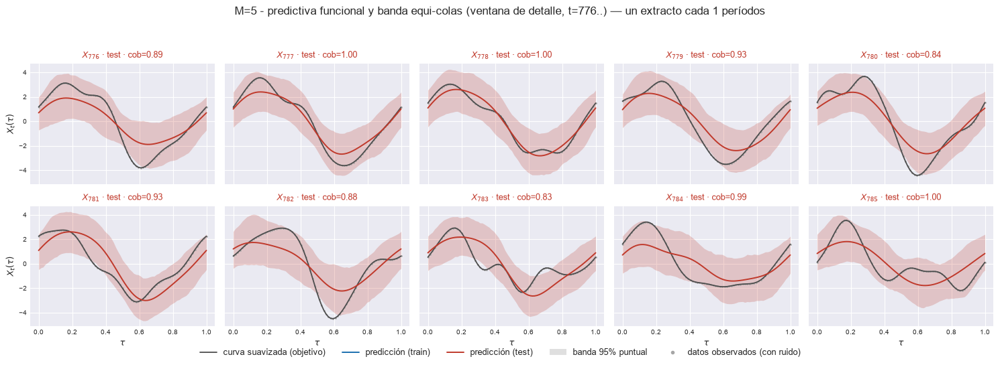

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=776 [test] cob=0.920 rmse=0.9898


  2/10 (20.0%) t=0.0s eta=0.0s  t=777 [test] cob=1.000 rmse=0.6102


  3/10 (30.0%) t=0.0s eta=0.0s  t=778 [test] cob=1.000 rmse=0.4189


  4/10 (40.0%) t=0.0s eta=0.0s  t=779 [test] cob=0.933 rmse=0.9083


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=782 [test] cob=0.893 rmse=1.157


  8/10 (80.0%) t=0.0s eta=0.0s  t=783 [test] cob=0.853 rmse=0.9736


  9/10 (90.0%) t=0.0s eta=0.0s  t=784 [test] cob=1.000 rmse=1.026


  10/10 (100.0%) t=0.0s eta=0.0s  t=785 [test] cob=1.000 rmse=1.121


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.944 (nominal 0.95)


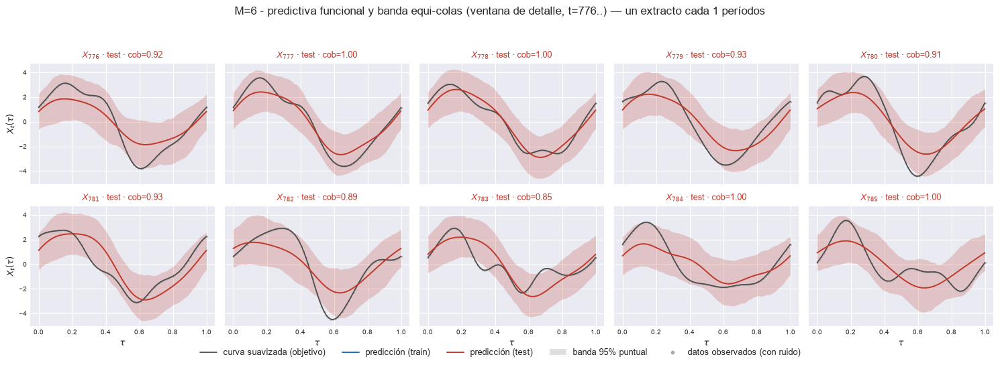

In [15]:
# Los N_DETALLE orígenes de la ventana de detalle (§3.2).
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[IDX_DET], e["X_pred"][IDX_DET], e["li_f"][IDX_DET], e["ls_f"][IDX_DET],
        grilla, T0, t=T_DET, cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[IDX_DET],
        title=f"M={M} - predictiva funcional y banda equi-colas (ventana de detalle, t={T0_DET}..)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6338


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.813 rmse=0.9423


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.907 rmse=0.8669


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6583


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7473


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.7527


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.5407


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.930 test=0.951 (nominal 0.95)


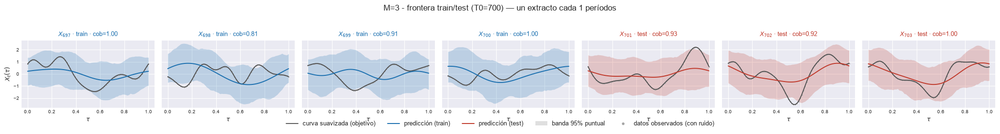

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6215


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.893 rmse=0.9529


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.947 rmse=0.8822


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6549


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.7738


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.907 rmse=0.7756


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.5195


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.960 test=0.956 (nominal 0.95)


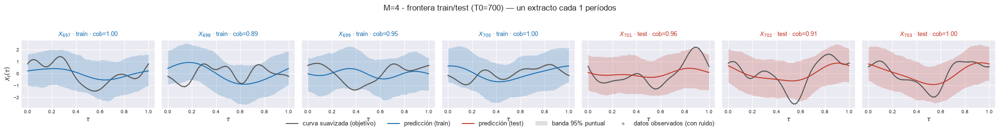

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6257


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.907 rmse=0.9206


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.920 rmse=0.8715


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.661


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.947 rmse=0.7476


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.7445


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.4393


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.957 test=0.956 (nominal 0.95)


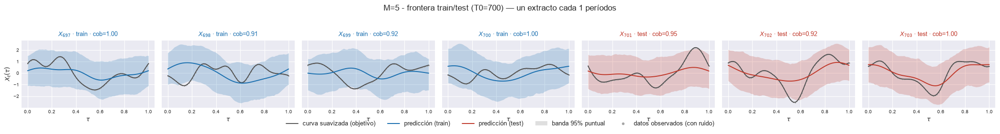

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6225


  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.920 rmse=0.9574


  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.8774


  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6574


  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7798


  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.907 rmse=0.7868


  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.4637


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.980 test=0.947 (nominal 0.95)


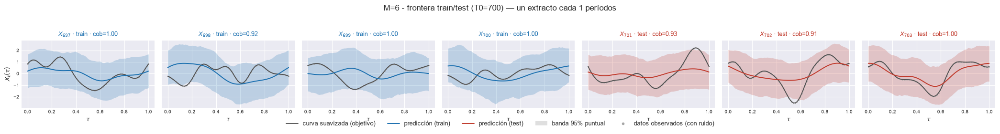

In [16]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.006326


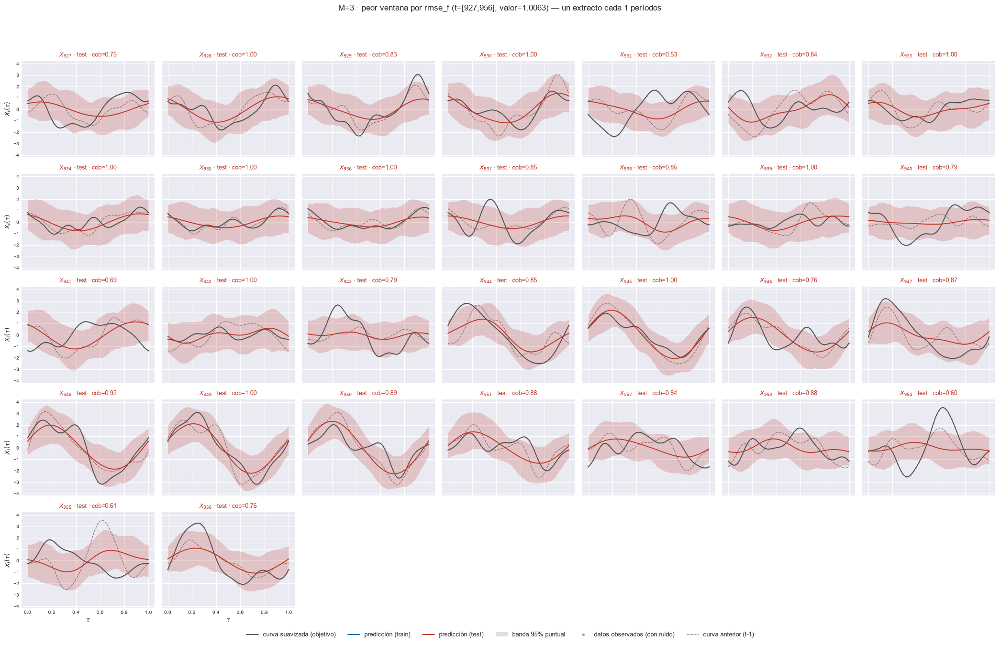

    t=[931, 960]  rmse_f=1.004521


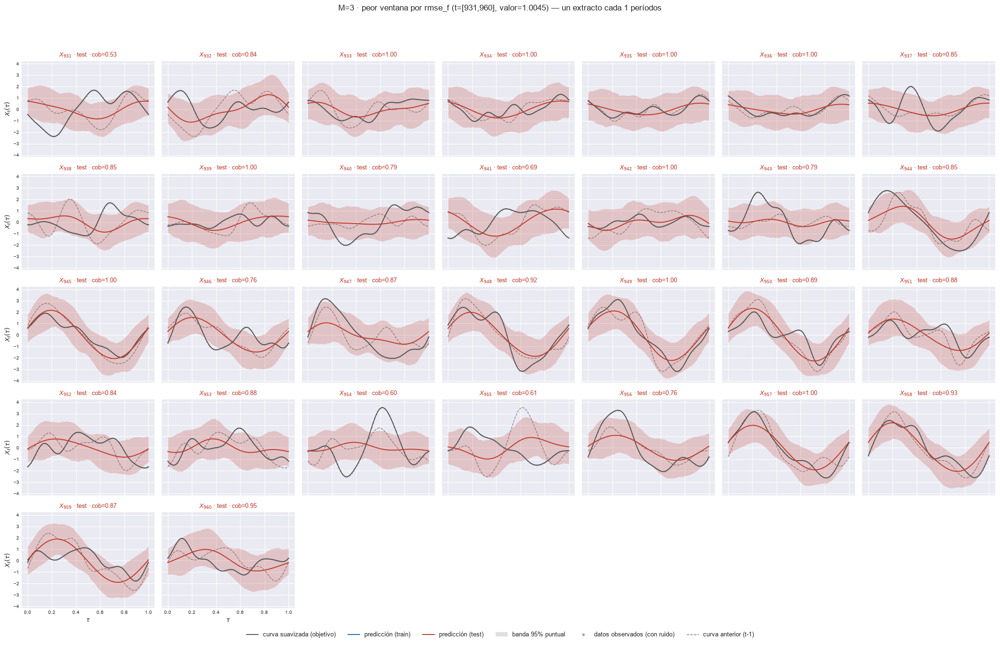

    t=[930, 959]  rmse_f=0.996156


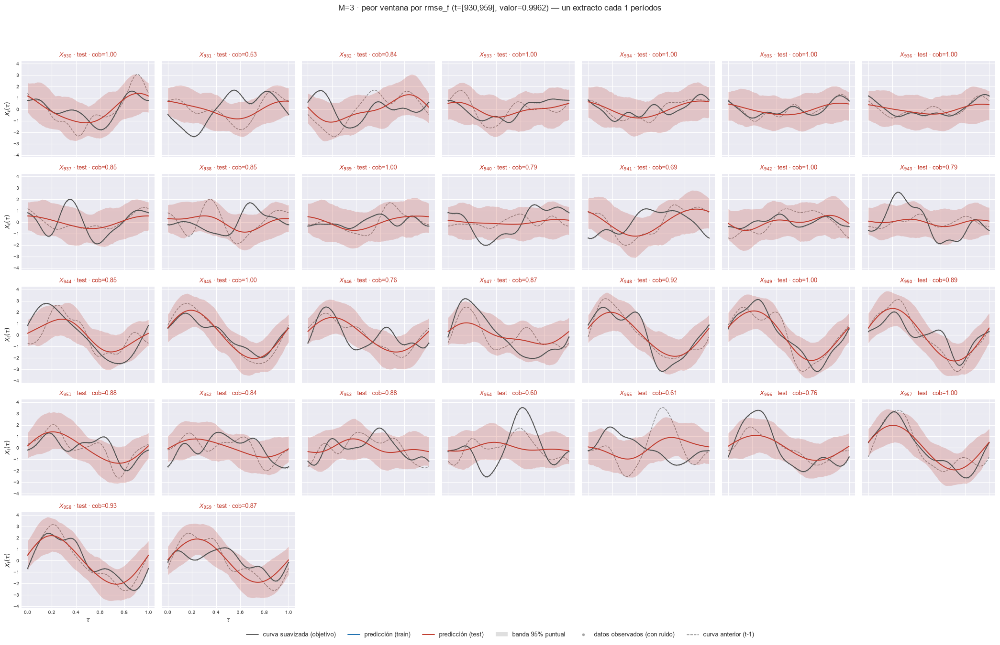

    t=[929, 958]  rmse_f=0.994381


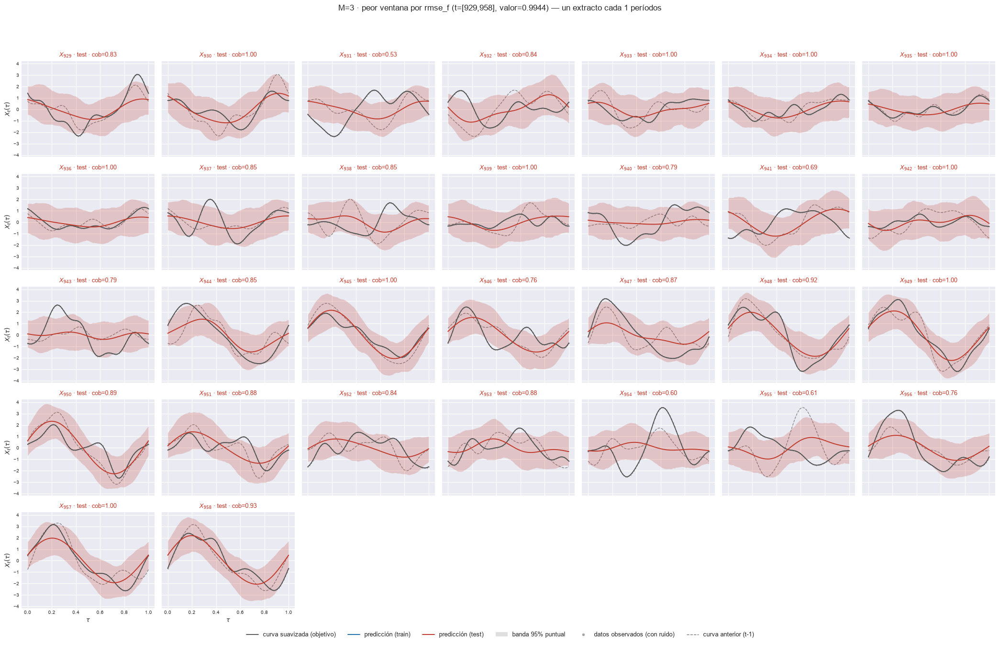

    t=[926, 955]  rmse_f=0.990282


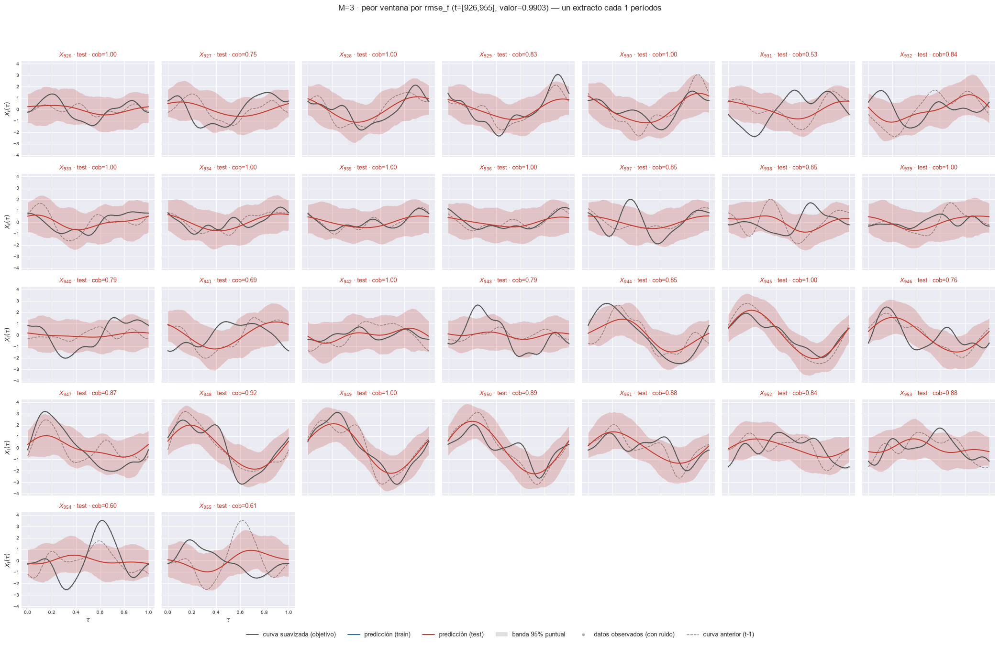

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=0.999040


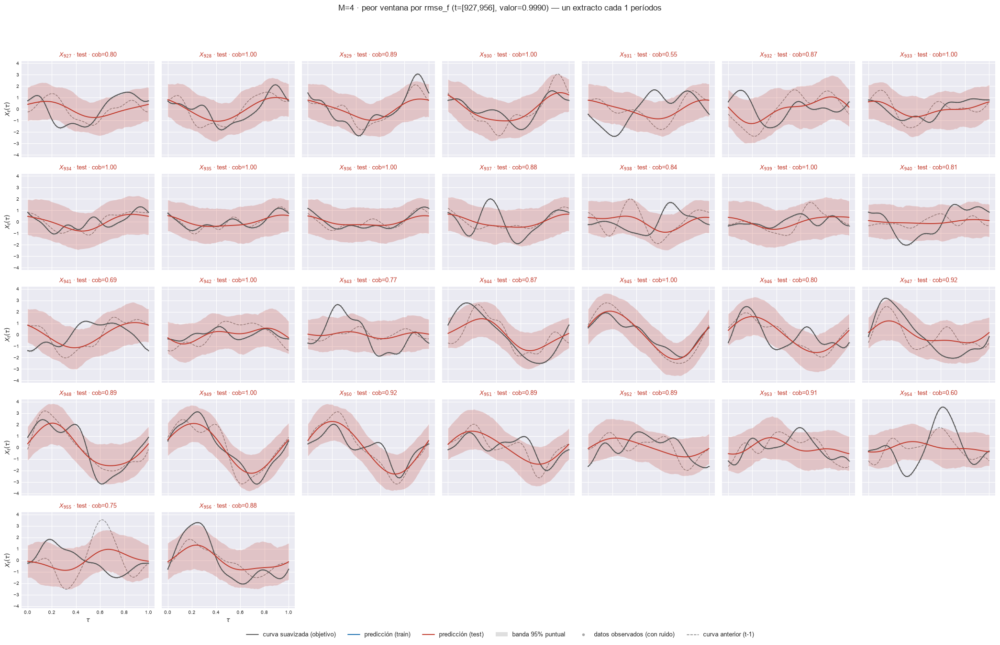

    t=[931, 960]  rmse_f=0.997712


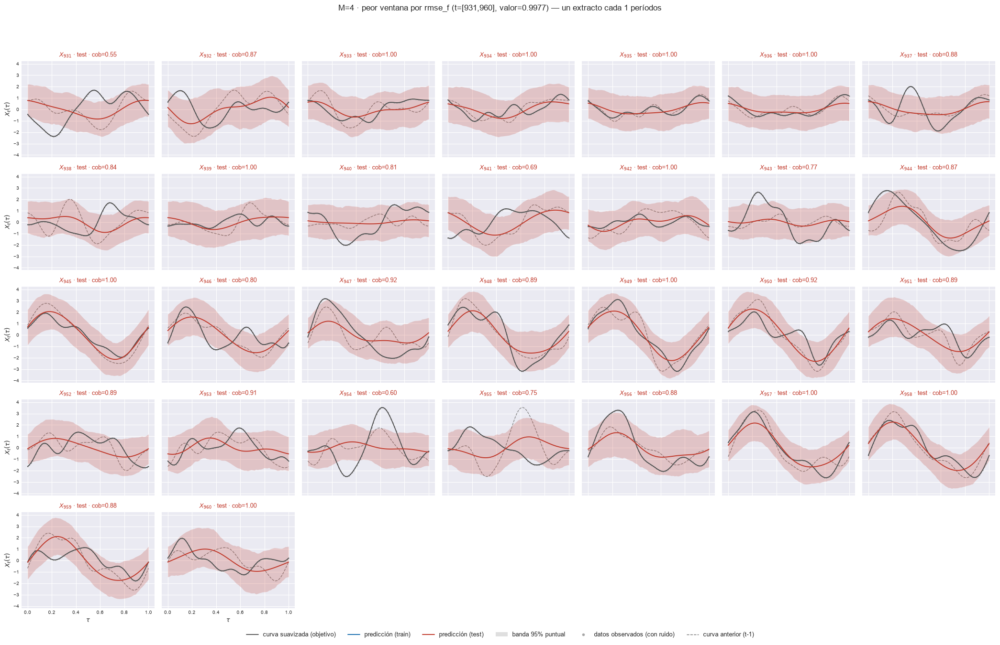

    t=[930, 959]  rmse_f=0.989208


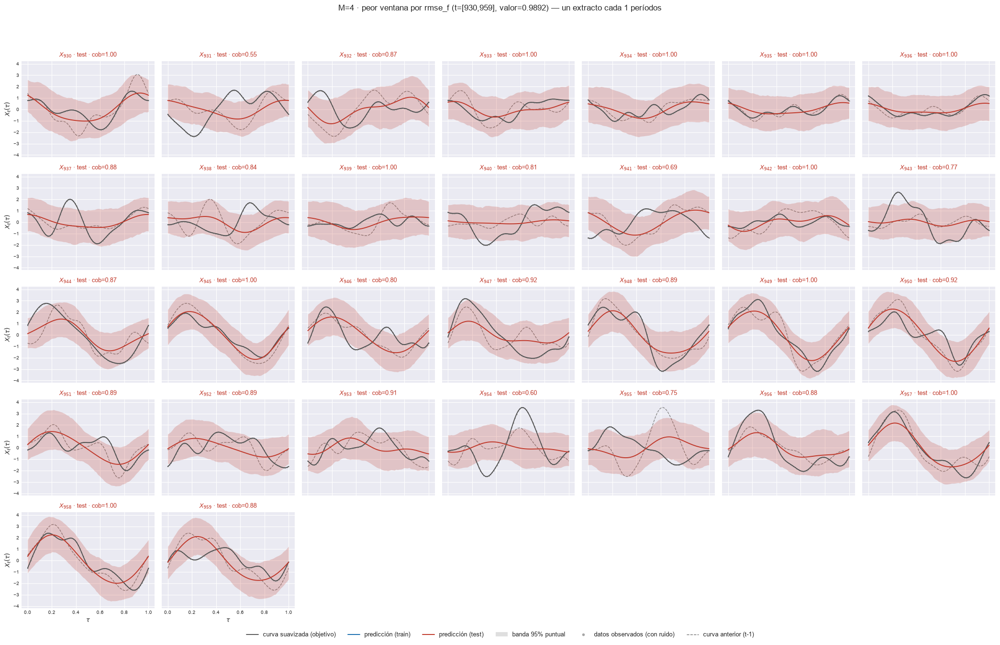

    t=[926, 955]  rmse_f=0.986193


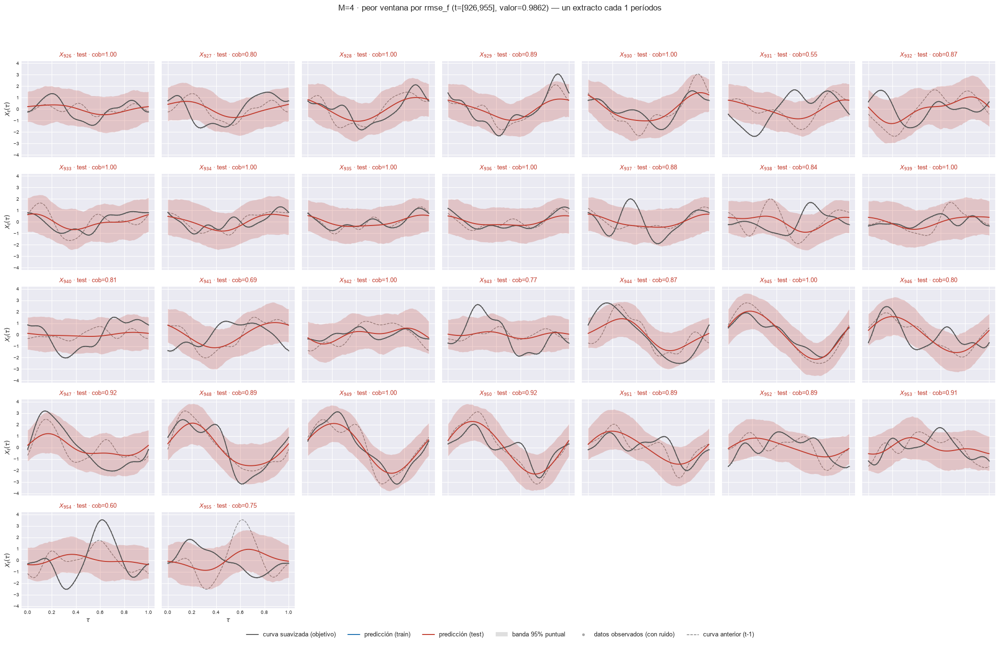

    t=[929, 958]  rmse_f=0.986067


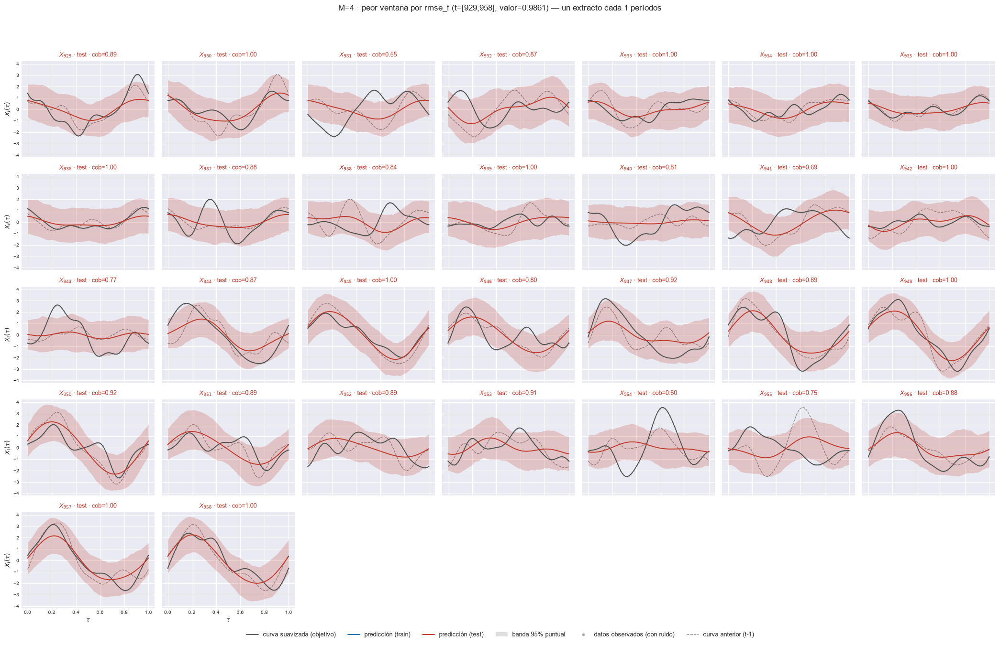

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.002323


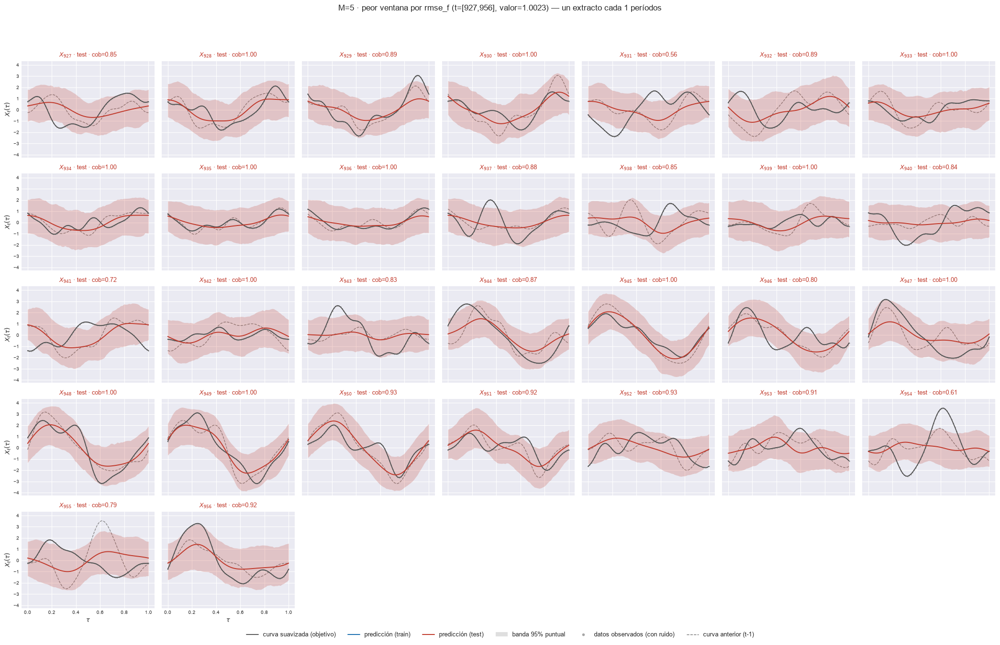

    t=[931, 960]  rmse_f=0.999790


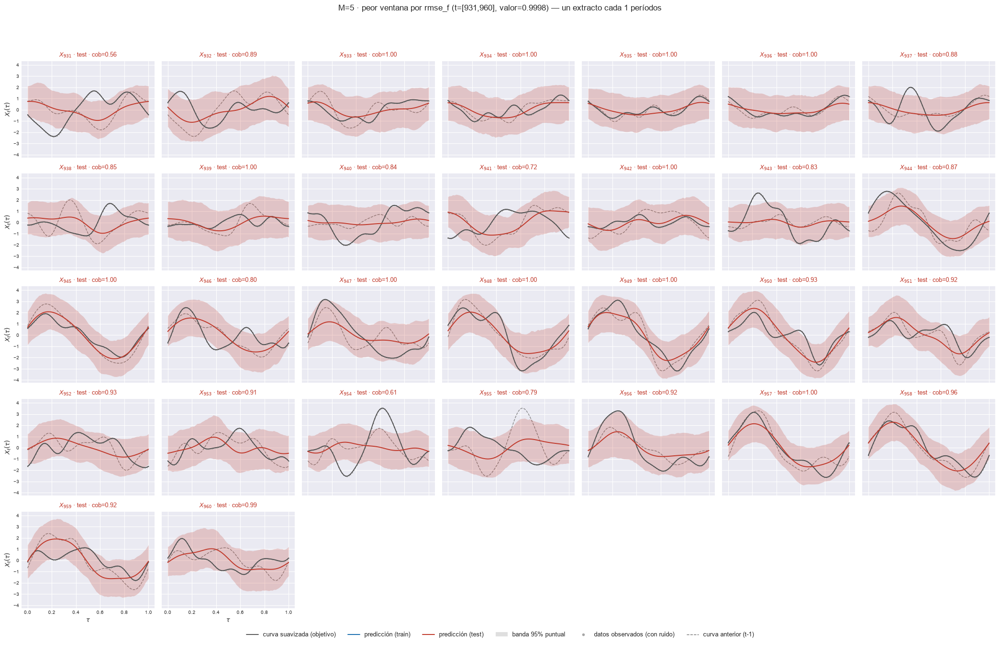

    t=[930, 959]  rmse_f=0.992291


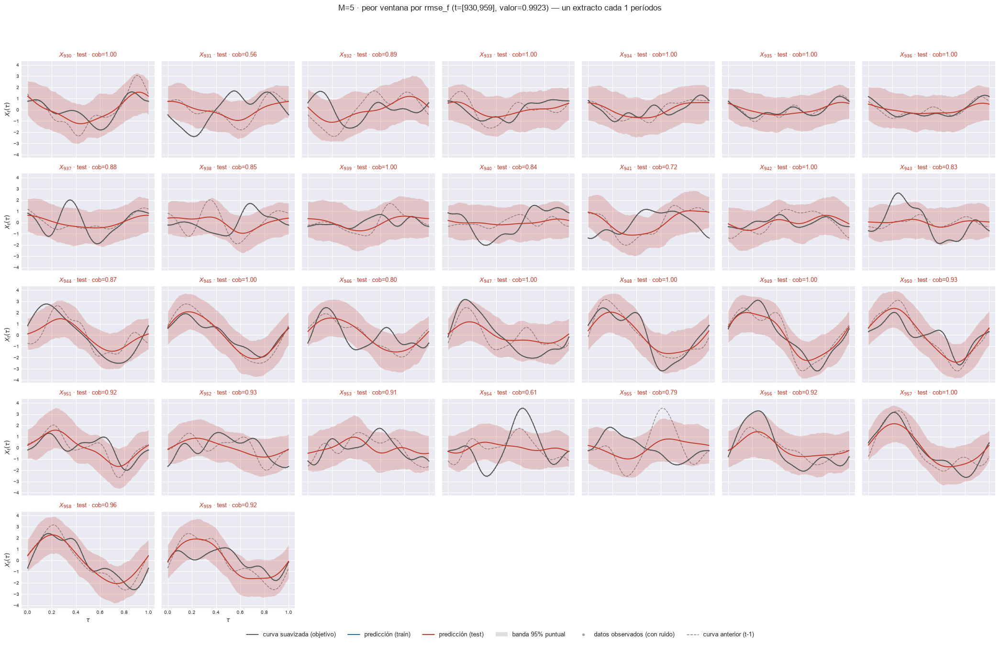

    t=[926, 955]  rmse_f=0.990400


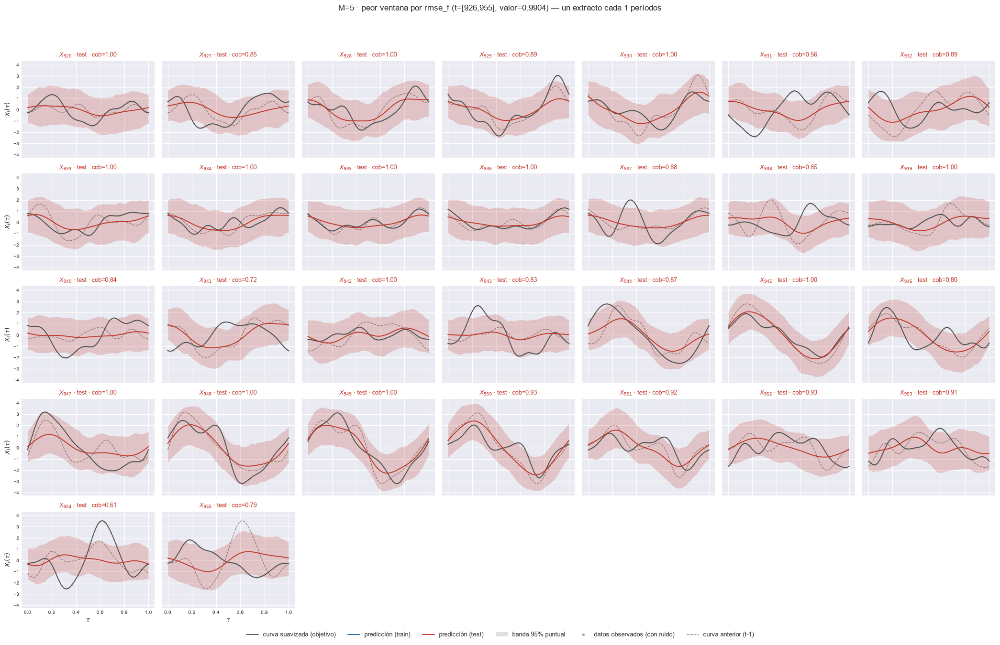

    t=[929, 958]  rmse_f=0.989164


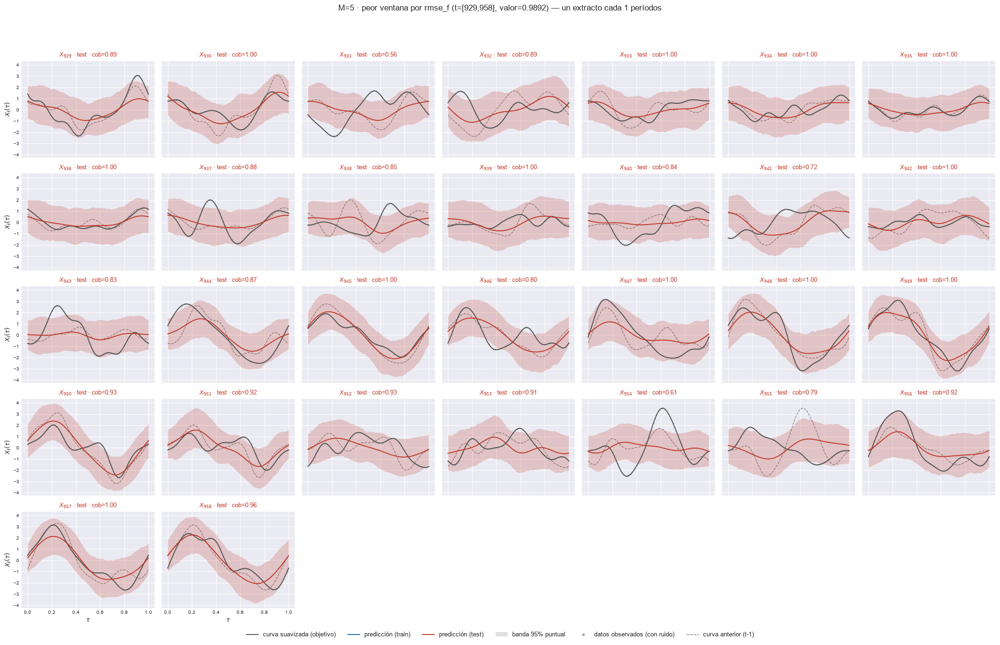

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.001786


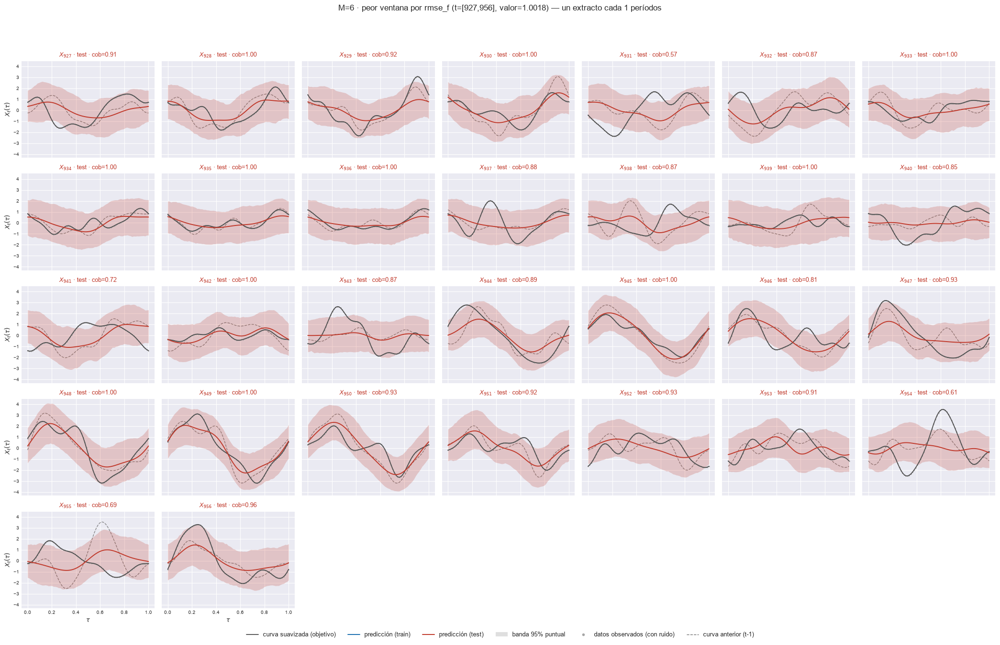

    t=[931, 960]  rmse_f=0.996825


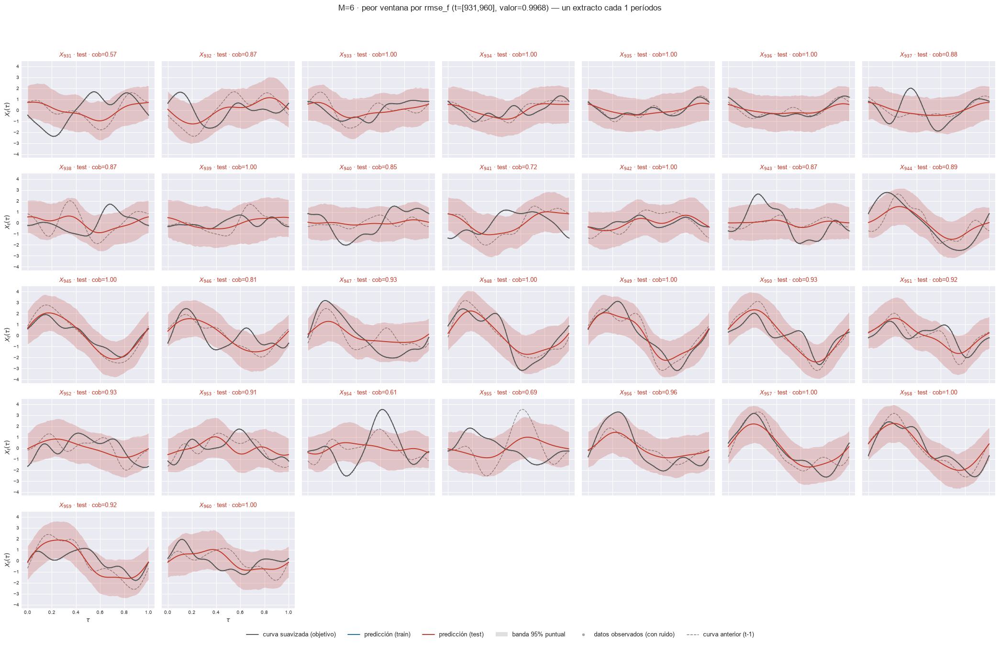

    t=[926, 955]  rmse_f=0.990130


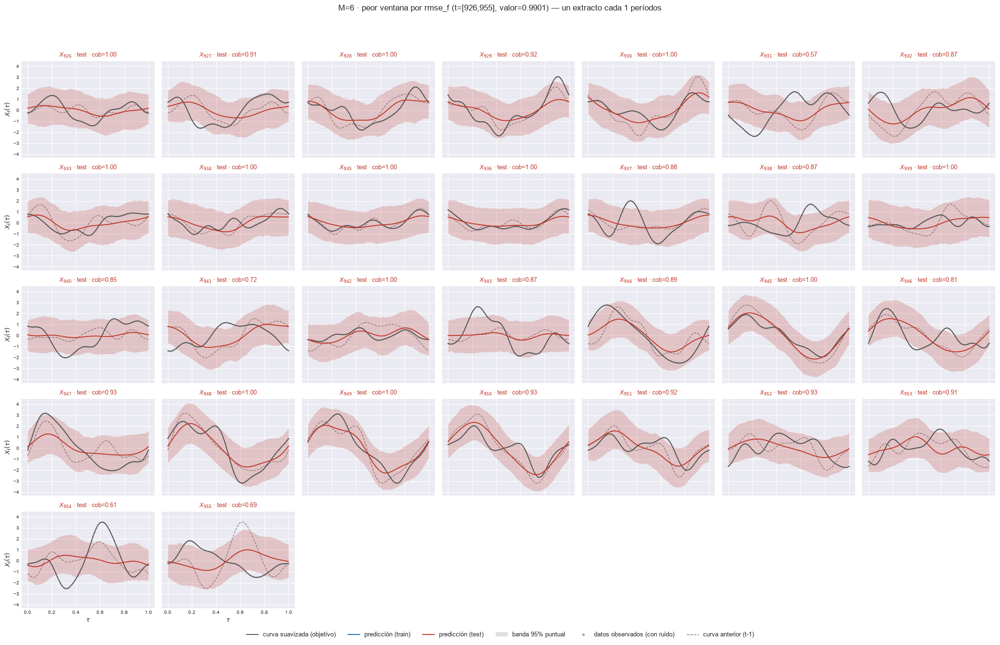

    t=[930, 959]  rmse_f=0.989669


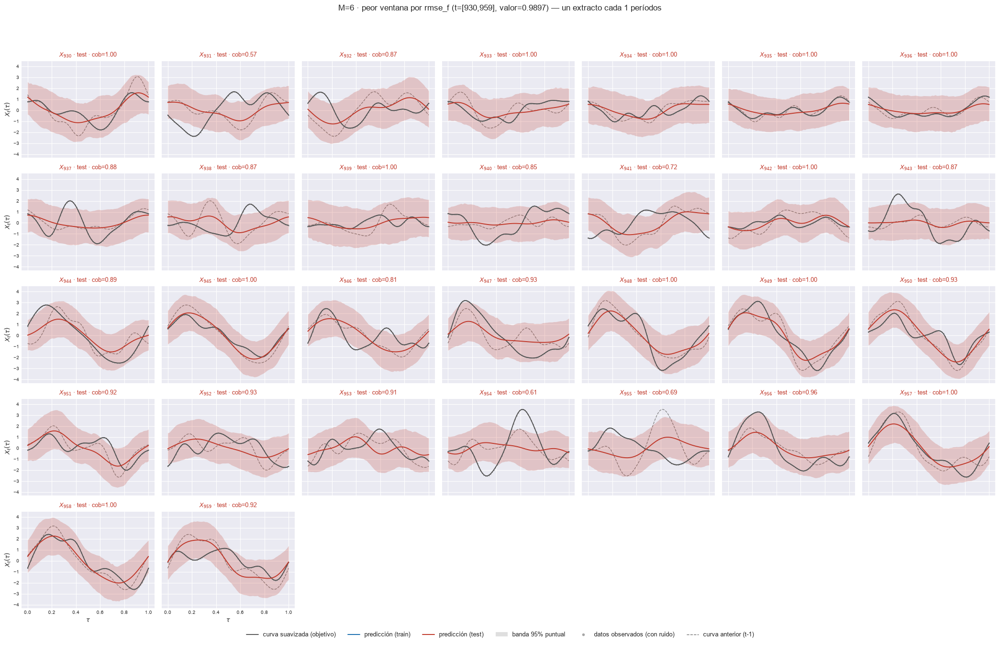

    t=[929, 958]  rmse_f=0.987287


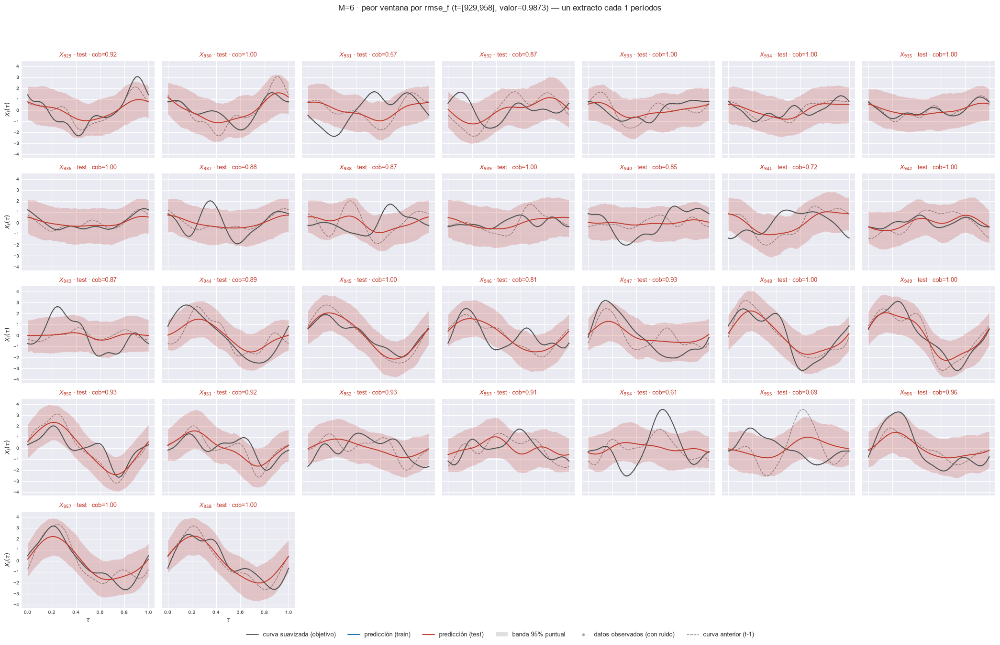

In [17]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

Soporte verdadero de `internos["soporte"]`; sensibilidad, especificidad y AUC.

In [18]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 6 variables, PIP en [0.037, 1.000]


  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 6 variables, PIP en [0.050, 1.000]


  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 6 variables, PIP en [0.063, 1.000]


[matriz_pip] listo: 3 pasos en 0.0s  tabla 6x6


...

  5/6 (83.3%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 12 variables, PIP en [0.054, 1.000]


  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 12 variables, PIP en [0.052, 1.000]


[matriz_pip] listo: 6 pasos en 0.0s  tabla 12x12


[M=6] dispersion maxima entre cadenas: 0.552   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,0.363,0.552,0.071,0.008,0.105,0.024,0.064,0.028,0.064,0.028
fpc_2_lag1,0.043,0.021,1.000,0.000,1.000,0.000,0.096,0.026,0.062,0.020,0.070,0.012
fpc_3_lag1,0.036,0.006,0.040,0.018,1.000,0.000,0.103,0.015,0.060,0.013,0.067,0.020
fpc_4_lag1,0.035,0.017,0.043,0.028,0.066,0.017,1.000,0.000,0.064,0.019,0.059,0.006
fpc_5_lag1,0.037,0.002,0.040,0.014,0.060,0.009,0.095,0.012,1.000,0.000,0.066,0.022
fpc_6_lag1,0.033,0.006,0.043,0.017,0.066,0.025,0.103,0.041,0.062,0.018,1.000,0.000
fpc_1_lag2,0.664,0.344,0.060,0.027,0.075,0.013,0.109,0.020,0.083,0.024,0.058,0.016
fpc_2_lag2,0.033,0.003,0.050,0.015,0.074,0.013,0.107,0.024,0.069,0.011,0.064,0.022
fpc_3_lag2,0.049,0.008,0.047,0.017,0.346,0.466,1.000,0.000,0.054,0.001,0.052,0.006


In [19]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,3,0.667,1.000,0.833,0.889,0.541,0.044
FPC 2,3,2,0,1,3,0.667,1.000,0.833,0.889,0.577,0.056
FPC 3,4,2,0,2,2,0.500,1.000,0.667,0.750,0.534,0.072


[M=4] |cos(psi_k, phi_k)| = [1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,5,0.667,1.000,0.875,0.733,0.663,0.033
FPC 2,3,1,0,2,5,0.333,1.000,0.750,0.900,0.466,0.044
FPC 3,4,2,0,2,4,0.500,1.000,0.750,0.812,0.530,0.063
FPC 4,5,2,0,3,3,0.400,1.000,0.625,0.800,0.471,0.094


[M=5] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,7,0.667,1.000,0.900,0.952,0.642,0.047
FPC 2,3,2,0,1,7,0.667,1.000,0.900,0.714,0.568,0.067
FPC 3,4,2,0,2,6,0.500,1.000,0.800,0.667,0.525,0.055
FPC 4,5,3,0,2,5,0.600,1.000,0.800,0.840,0.570,0.072
FPC 5,1,1,0,0,9,1.000,1.000,1.000,1.000,1.000,0.064


[M=6] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1.]

,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,9,0.667,1.000,0.917,0.963,0.569,0.037
FPC 2,3,1,0,2,9,0.333,1.000,0.833,1.000,0.474,0.044
FPC 3,4,2,0,2,8,0.500,1.000,0.833,0.781,0.537,0.105
FPC 4,5,2,0,3,7,0.400,1.000,0.750,0.829,0.462,0.098
FPC 5,1,1,0,0,11,1.000,1.000,1.000,1.000,1.000,0.064
FPC 6,1,1,0,0,11,1.000,1.000,1.000,1.000,1.000,0.063


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [20]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=3] curva_suavizada      PICP puntual test = 0.9082 (nominal 0.95)  ·  PICP simultaneo test = 0.4197


[M=3] representacion_fpca  PICP puntual test = 0.9508 (nominal 0.95)  ·  PICP simultaneo test = 0.7804


[M=4] curva_suavizada      PICP puntual test = 0.9311 (nominal 0.95)  ·  PICP simultaneo test = 0.5315


[M=4] representacion_fpca  PICP puntual test = 0.9481 (nominal 0.95)  ·  PICP simultaneo test = 0.6781


[M=5] curva_suavizada      PICP puntual test = 0.9426 (nominal 0.95)  ·  PICP simultaneo test = 0.5689


[M=5] representacion_fpca  PICP puntual test = 0.9456 (nominal 0.95)  ·  PICP simultaneo test = 0.6549


[M=6] curva_suavizada      PICP puntual test = 0.9439 (nominal 0.95)  ·  PICP simultaneo test = 0.5803


[M=6] representacion_fpca  PICP puntual test = 0.9467 (nominal 0.95)  ·  PICP simultaneo test = 0.6370


M,3,4,5,6
metrica,,,,
1. MAE (L^1),0.694108,0.689488,0.684413,0.689030
10. Winkler max peor ventana,59.891384,54.741083,52.206542,52.298937
2. RMSE (L^2),0.870298,0.865773,0.859713,0.865549
3. E_max promedio por curva,1.612373,1.601911,1.588702,1.597685
4. E_max peor de la ventana,3.038276,3.000527,2.953526,2.967621
5. MPIW,2.977786,3.161919,3.262924,3.326236
6. PICP puntual,0.908212,0.931080,0.942580,0.943869
7. PICPB curva completa,0.419680,0.531488,0.568881,0.580320
8. Winkler,4.314946,4.150078,4.081915,4.105554


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,3,4,5,6
predictor,,,,
esperanza,0.6941,0.6895,0.6844,0.6890
mediana,0.6953,0.6913,0.6855,0.6893
medoide,0.6969,0.6956,0.6933,0.6999
modal,0.7026,0.7004,0.6934,0.6984


M,3,4,5,6
predictor,,,,
esperanza,0.8703,0.8658,0.8597,0.8655
mediana,0.8716,0.8682,0.8611,0.8658
medoide,0.8735,0.8738,0.8717,0.8769
modal,0.8805,0.8817,0.8719,0.8791


M,3,4,5,6
predictor,,,,
esperanza,1.6124,1.6019,1.5887,1.5977
mediana,1.6153,1.6076,1.5901,1.5992
medoide,1.6136,1.6134,1.6081,1.6274
modal,1.6202,1.6218,1.5955,1.6112


M,3,4,5,6
predictor,,,,
esperanza,3.0383,3.0005,2.9535,2.9676
mediana,3.0514,3.0195,2.9561,2.9780
medoide,3.0457,3.0149,3.0549,2.9542
modal,3.1265,3.1129,3.0746,3.0544


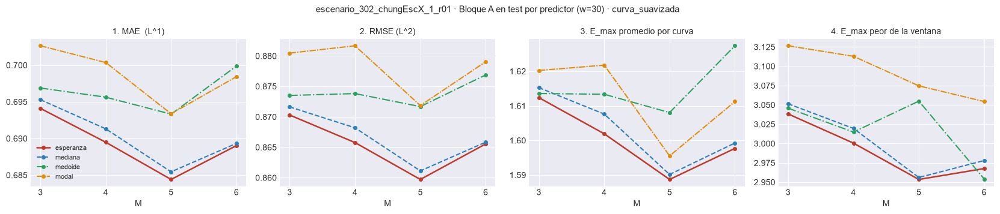

M,3,4,5,6
predictor,,,,
esperanza,0.6084,0.6431,0.6602,0.6750
mediana,0.6094,0.6451,0.6615,0.6750
medoide,0.6122,0.6506,0.6696,0.6873
modal,0.6158,0.6538,0.6688,0.6850


M,3,4,5,6
predictor,,,,
esperanza,0.7614,0.8059,0.8294,0.8500
mediana,0.7629,0.8085,0.8308,0.8503
medoide,0.7651,0.8145,0.8418,0.8615
modal,0.7730,0.8229,0.8419,0.8638


M,3,4,5,6
predictor,,,,
esperanza,1.2045,1.3336,1.4365,1.5173
mediana,1.2110,1.3445,1.4414,1.5193
medoide,1.2079,1.3484,1.4699,1.5480
modal,1.2146,1.3615,1.4538,1.5340


M,3,4,5,6
predictor,,,,
esperanza,2.5221,2.5932,2.7033,2.8420
mediana,2.5282,2.6164,2.7143,2.8617
medoide,2.5280,2.6297,2.8156,2.8441
modal,2.6282,2.7372,2.8316,2.9705


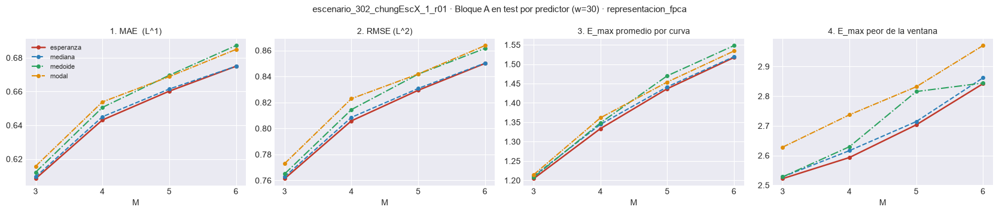

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,3,4,5,6
intervalo,,,,
equicolas,2.9778,3.1619,3.2629,3.3262
simultanea,4.1633,4.5945,4.8001,4.9258
hdr,2.9825,3.1678,3.2693,3.3330


M,3,4,5,6
intervalo,,,,
equicolas,0.9082,0.9311,0.9426,0.9439
simultanea,0.9800,0.9906,0.9932,0.9945
hdr,0.9101,0.9306,0.9420,0.9445


M,3,4,5,6
intervalo,,,,
equicolas,0.4197,0.5315,0.5689,0.5803
simultanea,0.7787,0.9007,0.9229,0.9303
hdr,0.4431,0.5189,0.5577,0.5891


M,3,4,5,6
intervalo,,,,
equicolas,4.3149,4.1501,4.0819,4.1056
simultanea,4.4152,4.7102,4.8880,4.9915
hdr,4.3130,4.1562,4.0938,4.1109


M,3,4,5,6
intervalo,,,,
equicolas,14.3959,12.2071,11.1037,10.7279
simultanea,7.6874,6.4746,6.3348,6.2422
hdr,14.3327,12.2369,11.1376,10.7958


M,3,4,5,6
intervalo,,,,
equicolas,59.8914,54.7411,52.2065,52.2989
simultanea,40.4626,29.9815,25.3799,23.9826
hdr,61.0977,55.5502,53.5644,53.1406


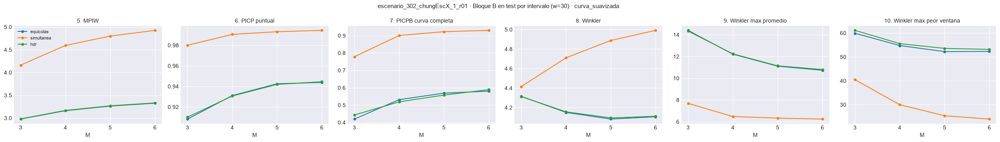

M,3,4,5,6
intervalo,,,,
equicolas,2.9778,3.1619,3.2629,3.3262
simultanea,4.1633,4.5945,4.8001,4.9258
hdr,2.9825,3.1678,3.2693,3.3330


M,3,4,5,6
intervalo,,,,
equicolas,0.9508,0.9481,0.9456,0.9467
simultanea,0.9937,0.9953,0.9967,0.9963
hdr,0.9511,0.9490,0.9460,0.9477


M,3,4,5,6
intervalo,,,,
equicolas,0.7804,0.6781,0.6549,0.6370
simultanea,0.9491,0.9487,0.9664,0.9554
hdr,0.7785,0.6809,0.6509,0.6269


M,3,4,5,6
intervalo,,,,
equicolas,3.5555,3.7926,3.9298,4.0373
simultanea,4.2263,4.6417,4.8471,4.9730
hdr,3.5628,3.7973,3.9371,4.0402


M,3,4,5,6
intervalo,,,,
equicolas,6.6569,7.8881,8.8900,9.6225
simultanea,5.3421,5.5448,5.7628,5.9575
hdr,6.6640,7.8491,8.8612,9.6576


M,3,4,5,6
intervalo,,,,
equicolas,38.1960,39.4770,41.2953,47.2046
simultanea,15.0917,16.0622,16.2478,19.3355
hdr,38.5252,40.4465,42.6176,48.3868


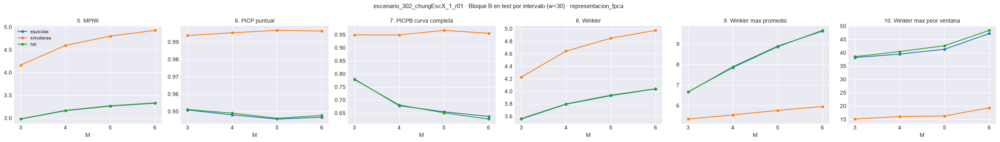

In [22]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)


  1/969 ( 0.1%) t=0.0s eta=1.1s  t=17 [train] rmse=0.4528


  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4274


  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.5724


  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4621


...

  864/969 (89.2%) t=0.1s eta=0.0s  t=880 [test] rmse=0.3177


  912/969 (94.1%) t=0.1s eta=0.0s  t=928 [test] rmse=0.3657


  960/969 (99.1%) t=0.2s eta=0.0s  t=976 [test] rmse=0.3454


  969/969 (100.0%) t=0.2s eta=0.0s  t=985 [test] rmse=0.351


[ventana_movil_scores[FPC 3, w=30]] listo: 969 pasos en 0.2s  29 ventanas cruzan T0


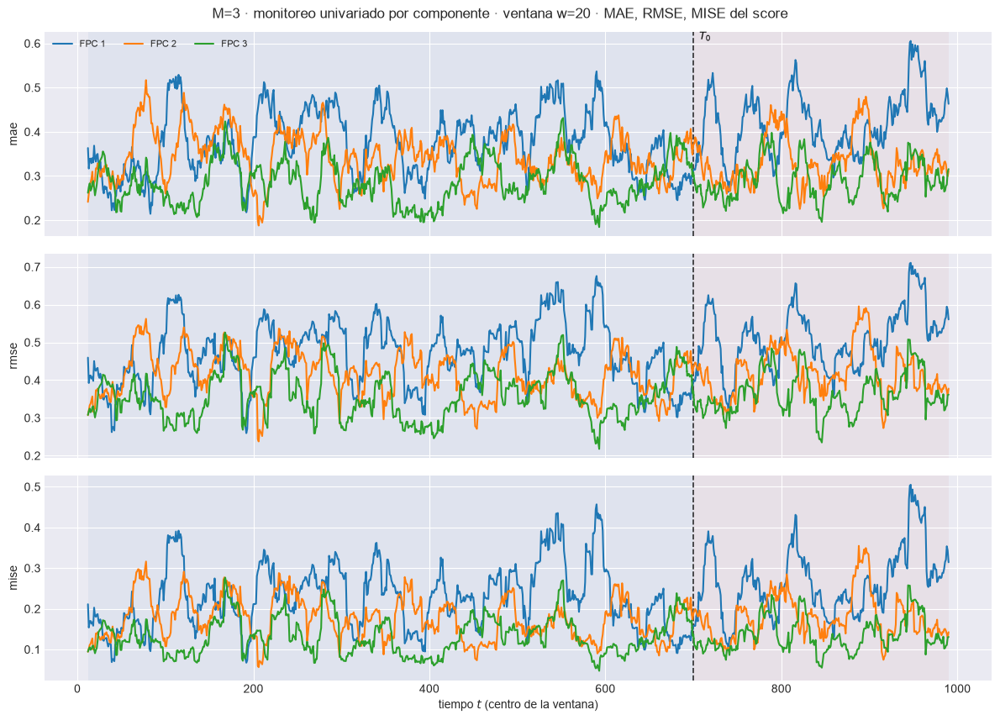

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.33  w=30 test=0.3284


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4154  w=30 test=0.4242


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1725  w=30 test=0.1799


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m03\91_ventana_univariado_w30.png


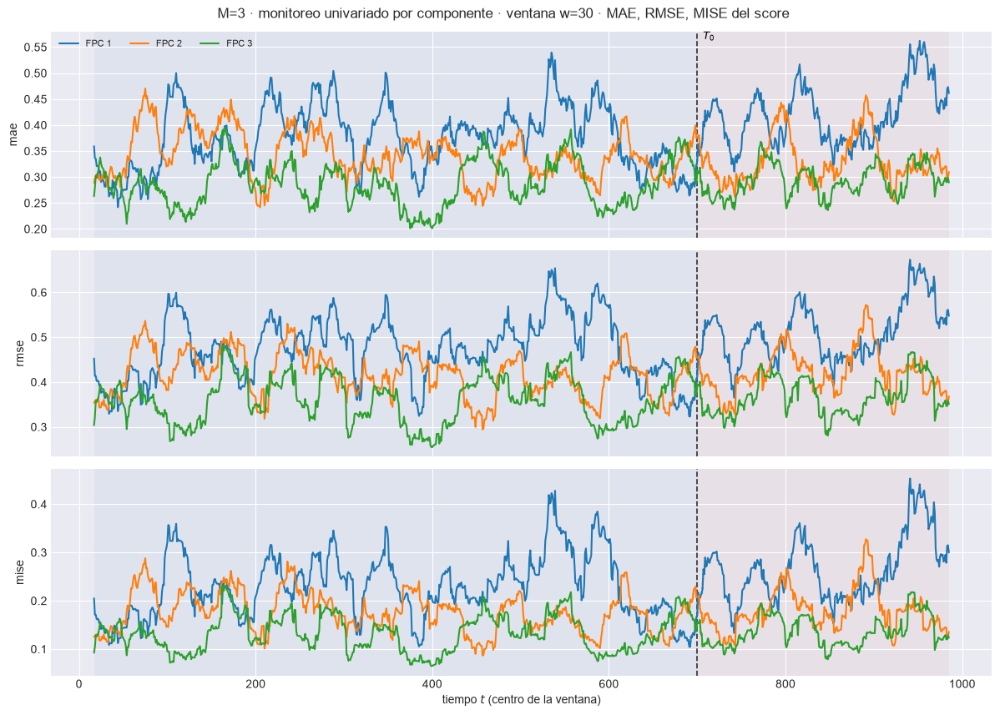

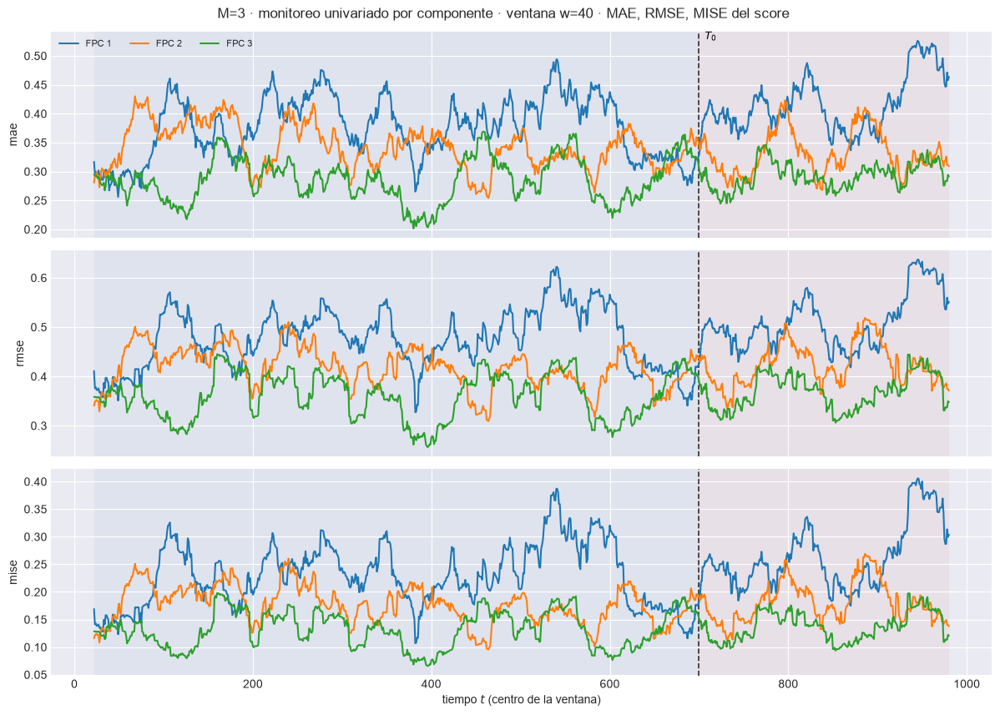

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)


  1/969 ( 0.1%) t=0.0s eta=1.2s  t=17 [train] rmse=0.4462


  48/969 ( 5.0%) t=0.0s eta=0.2s  t=64 [train] rmse=0.4309


  96/969 ( 9.9%) t=0.0s eta=0.2s  t=112 [train] rmse=0.5679


  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.462


...

  864/969 (89.2%) t=0.1s eta=0.0s  t=880 [test] rmse=0.2921


  912/969 (94.1%) t=0.1s eta=0.0s  t=928 [test] rmse=0.2213


  960/969 (99.1%) t=0.1s eta=0.0s  t=976 [test] rmse=0.2301


  969/969 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.2497


[ventana_movil_scores[FPC 4, w=30]] listo: 969 pasos en 0.2s  29 ventanas cruzan T0


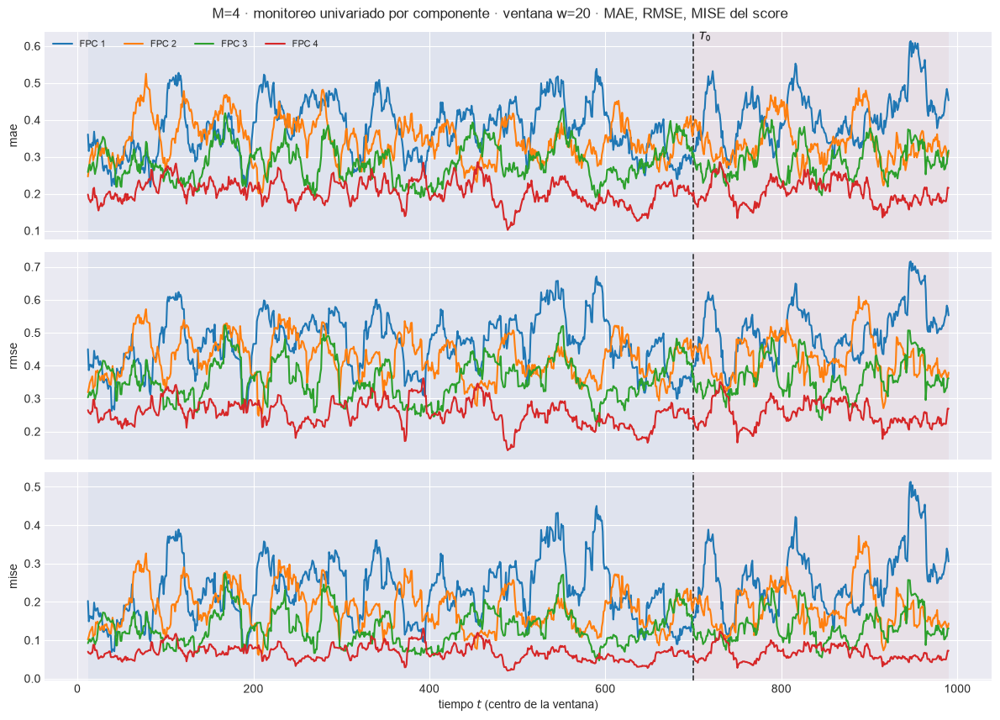

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.3042  w=30 test=0.311


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3836  w=30 test=0.3978


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1472  w=30 test=0.1582


[plot_ventana_movil] listo: 3 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m04\91_ventana_univariado_w30.png


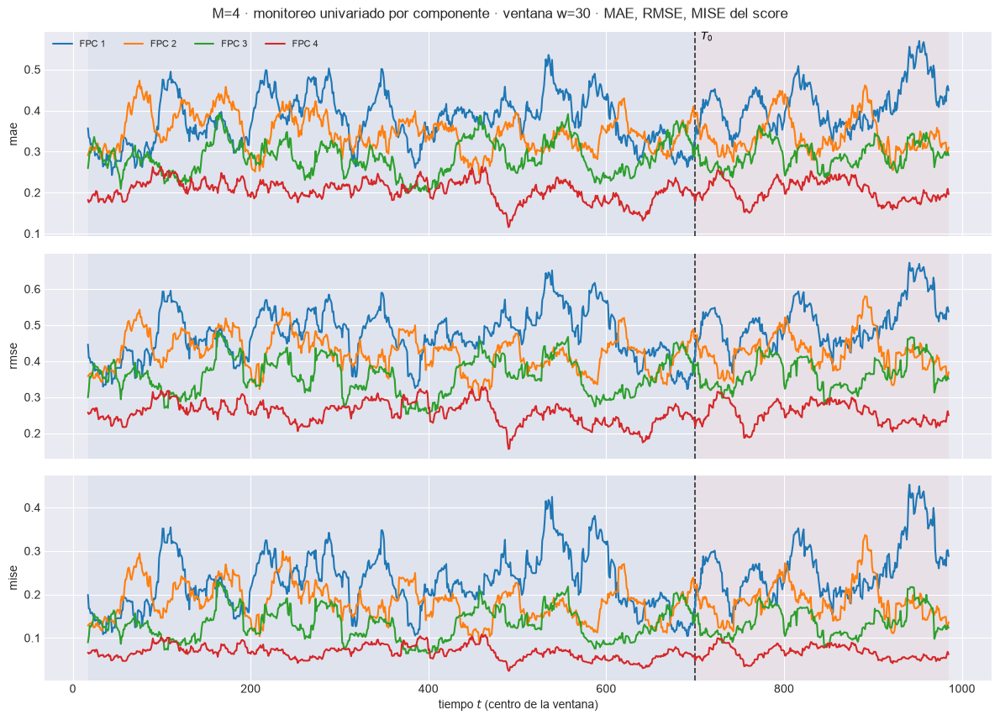

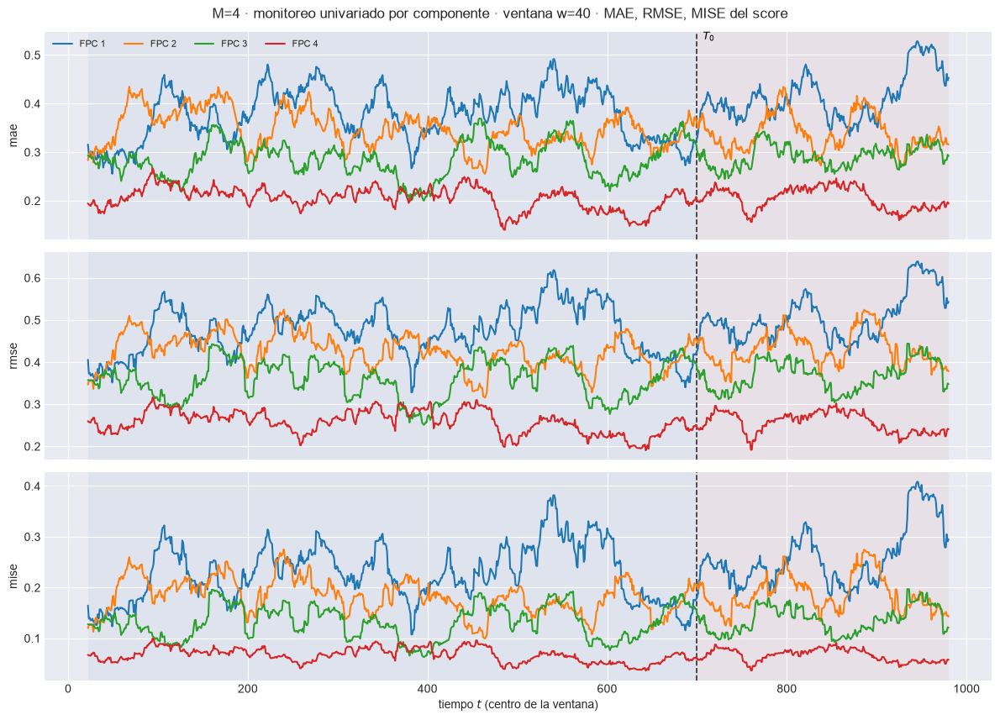

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)


  1/969 ( 0.1%) t=0.0s eta=1.4s  t=17 [train] rmse=0.4462


  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4298


  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.5689


  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4616


...

  864/969 (89.2%) t=0.1s eta=0.0s  t=880 [test] rmse=0.1743


  912/969 (94.1%) t=0.1s eta=0.0s  t=928 [test] rmse=0.1824


  960/969 (99.1%) t=0.1s eta=0.0s  t=976 [test] rmse=0.2061


  969/969 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.1882


[ventana_movil_scores[FPC 5, w=30]] listo: 969 pasos en 0.1s  29 ventanas cruzan T0


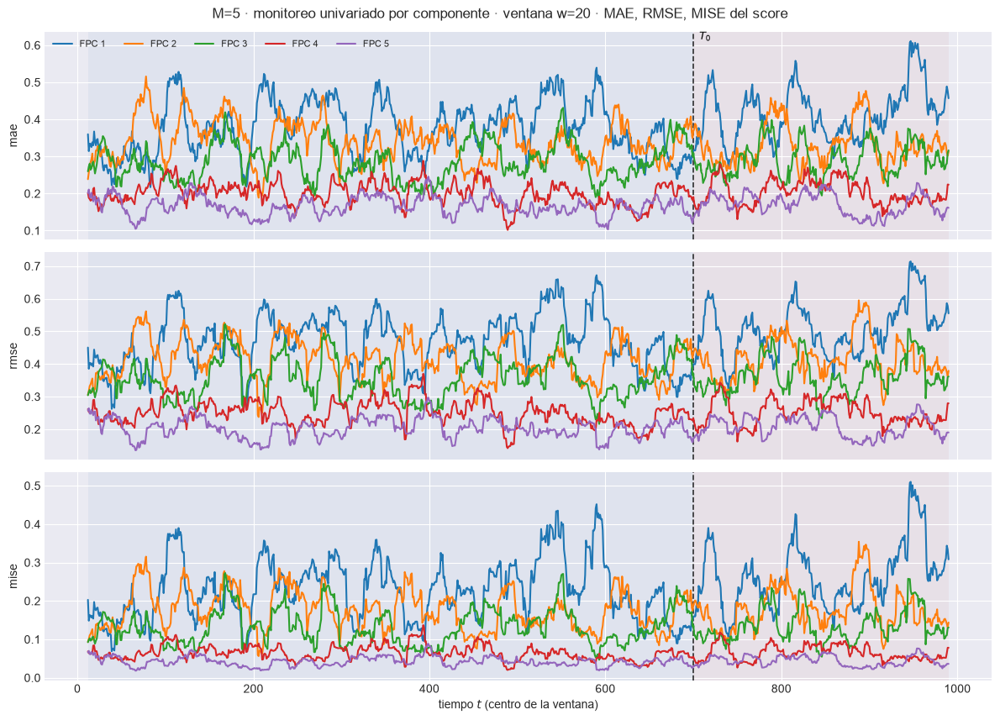

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.273  w=30 test=0.2823


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3441  w=30 test=0.3527


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1184  w=30 test=0.1244


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m05\91_ventana_univariado_w30.png


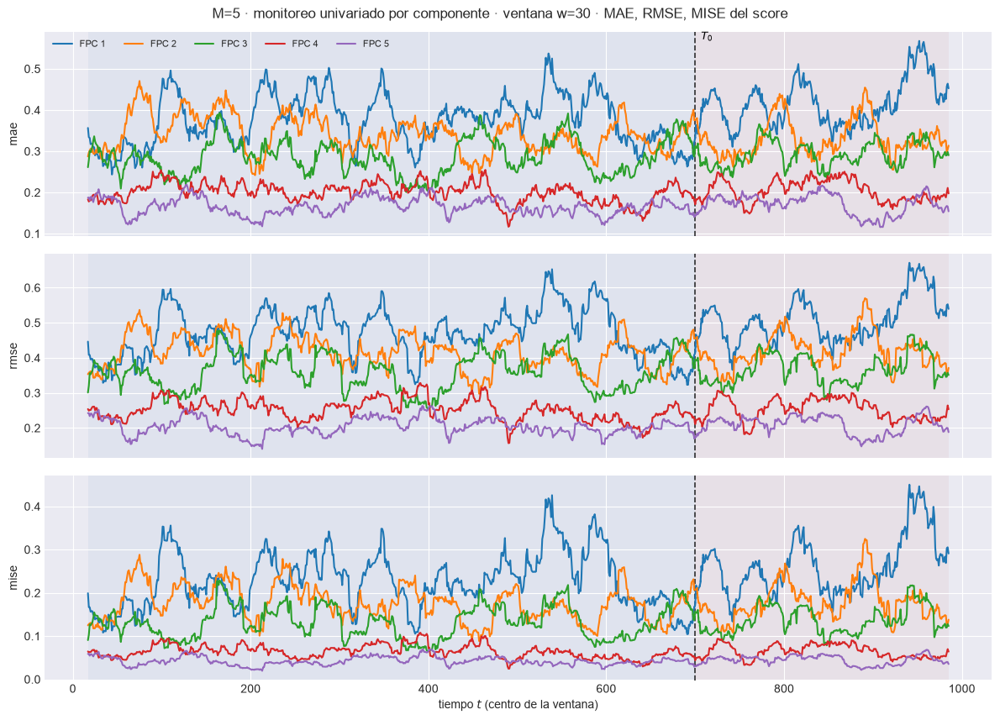

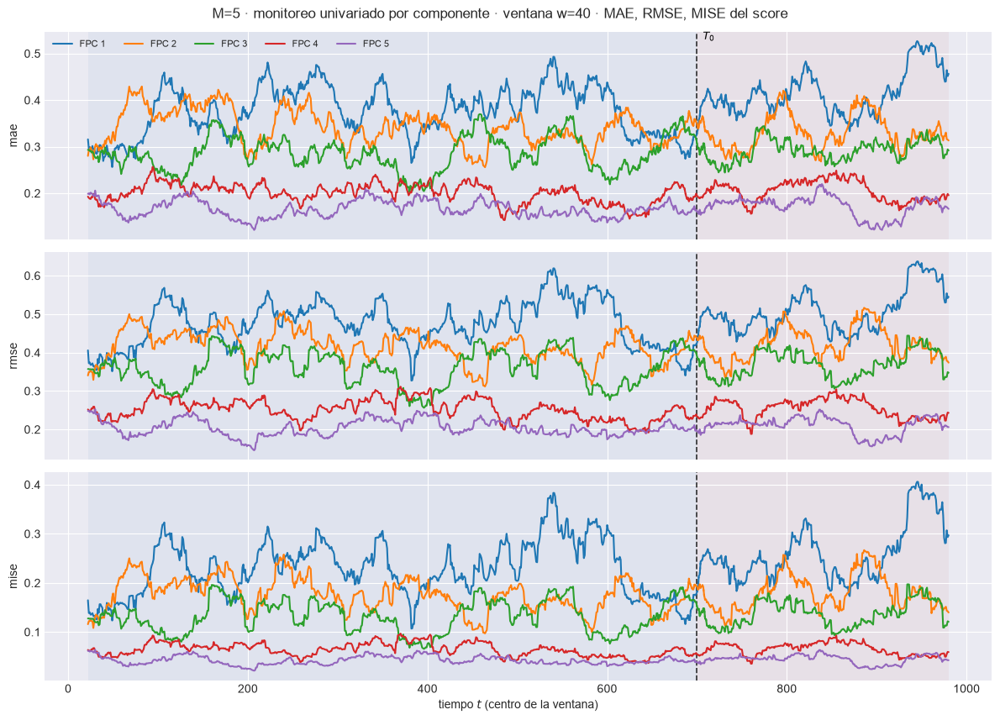

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)


  1/969 ( 0.1%) t=0.0s eta=0.9s  t=17 [train] rmse=0.4494


  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4284


  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.572


  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4613


...

  864/969 (89.2%) t=0.1s eta=0.0s  t=880 [test] rmse=0.1621


  912/969 (94.1%) t=0.1s eta=0.0s  t=928 [test] rmse=0.1415


  960/969 (99.1%) t=0.1s eta=0.0s  t=976 [test] rmse=0.1615


  969/969 (100.0%) t=0.1s eta=0.0s  t=985 [test] rmse=0.1556


[ventana_movil_scores[FPC 6, w=30]] listo: 969 pasos en 0.1s  29 ventanas cruzan T0


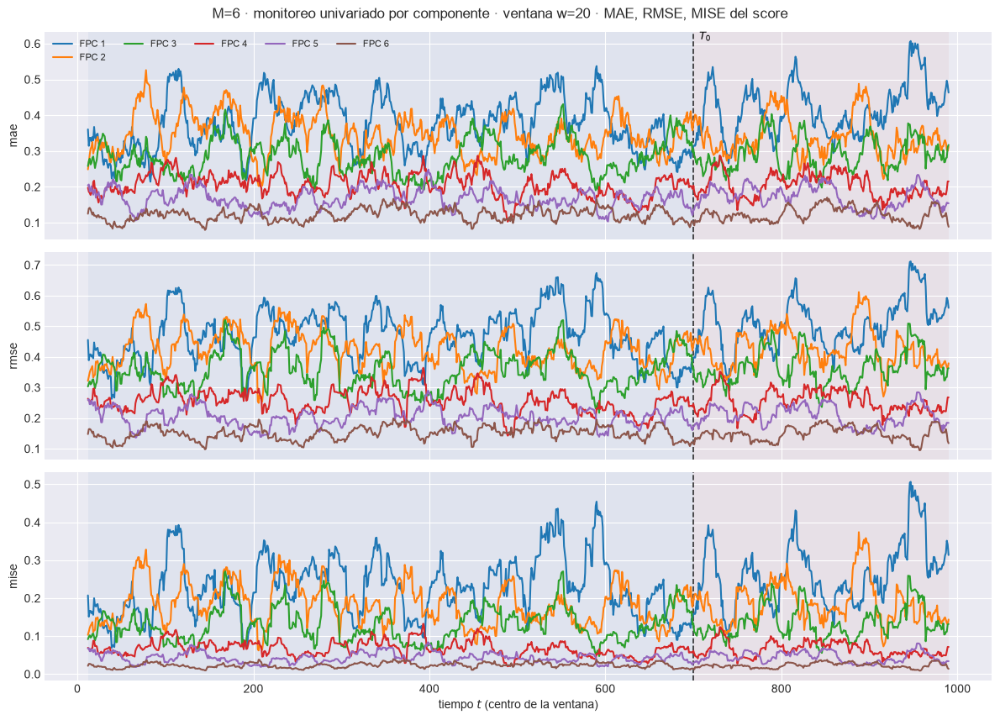

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2339  w=30 test=0.2448


  2/3 (66.7%) t=0.4s eta=0.2s  rmse: w=30 train=0.2953  w=30 test=0.3006


  3/3 (100.0%) t=0.5s eta=0.0s  mise: w=30 train=0.08718  w=30 test=0.09035


[plot_ventana_movil] listo: 3 pasos en 0.8s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m06\91_ventana_univariado_w30.png


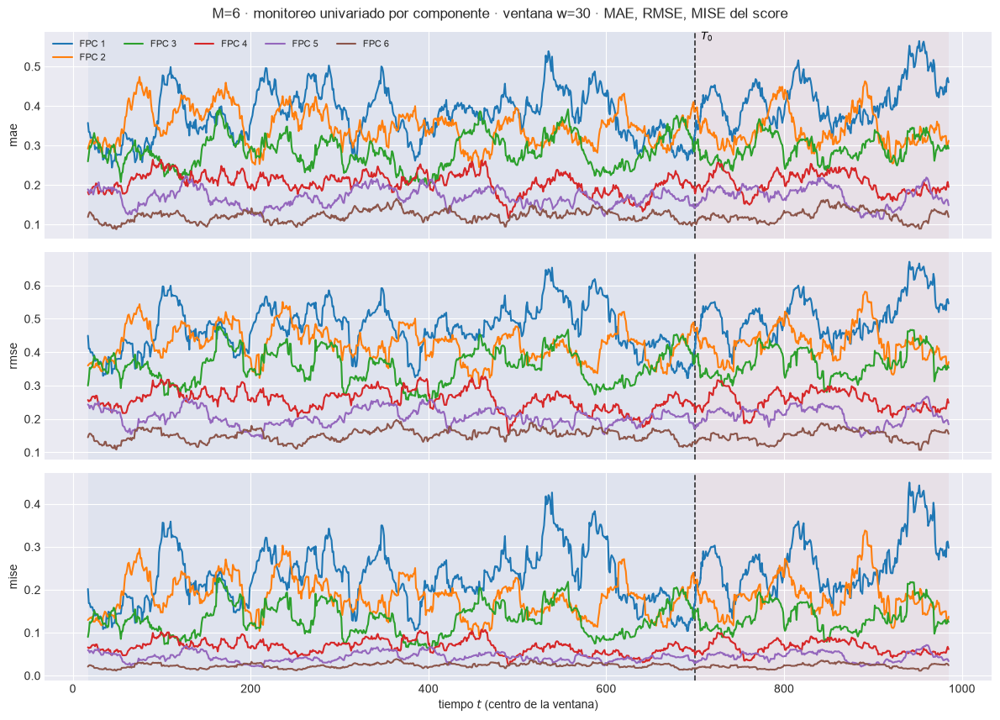

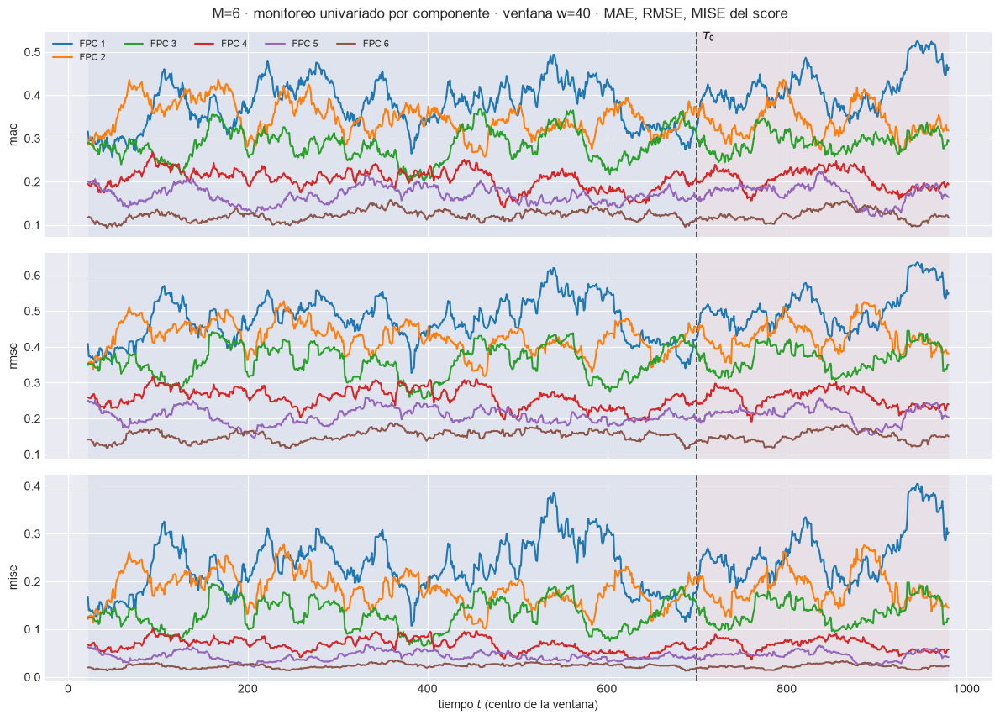

In [23]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

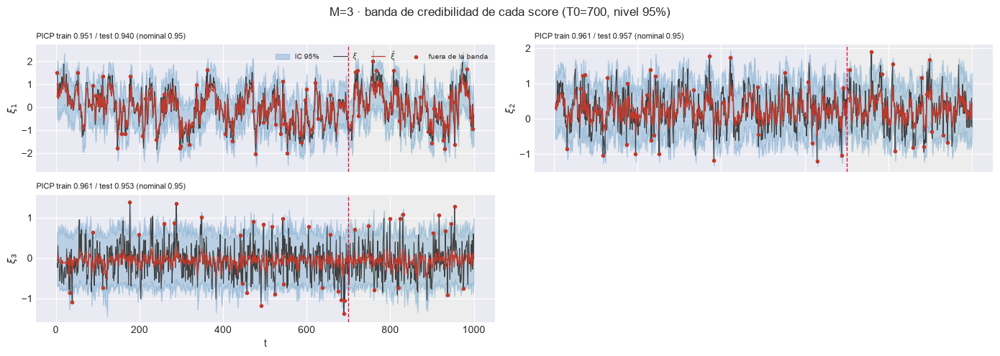

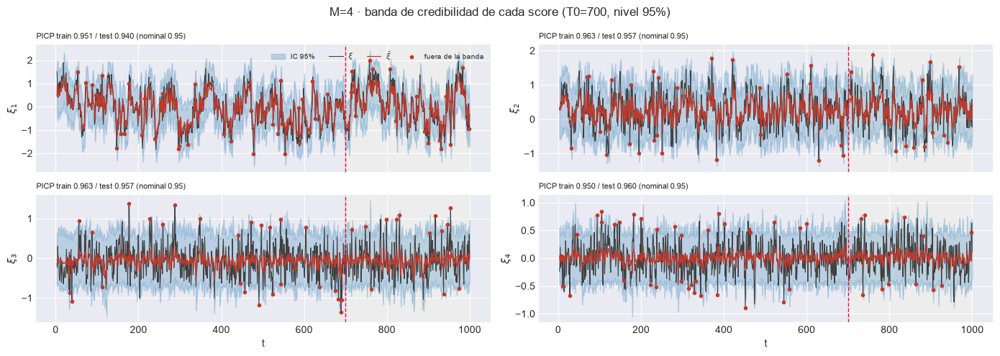

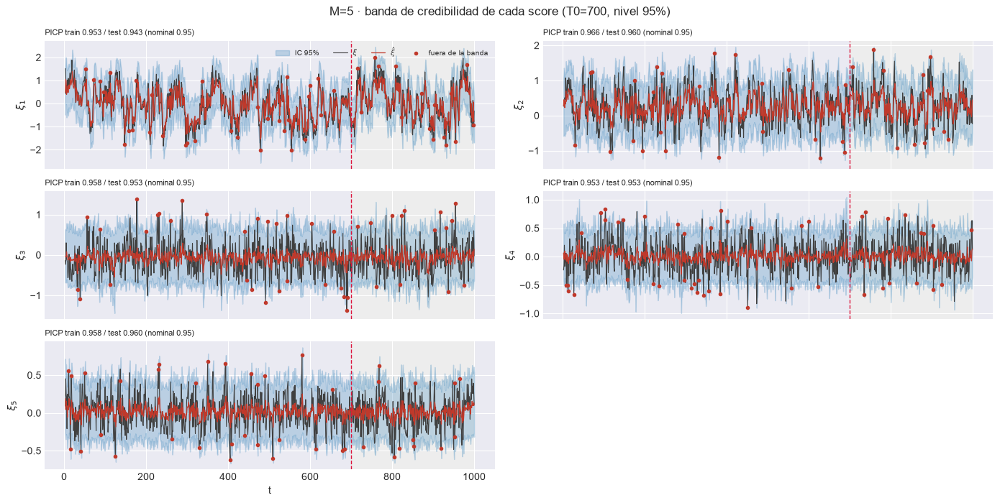

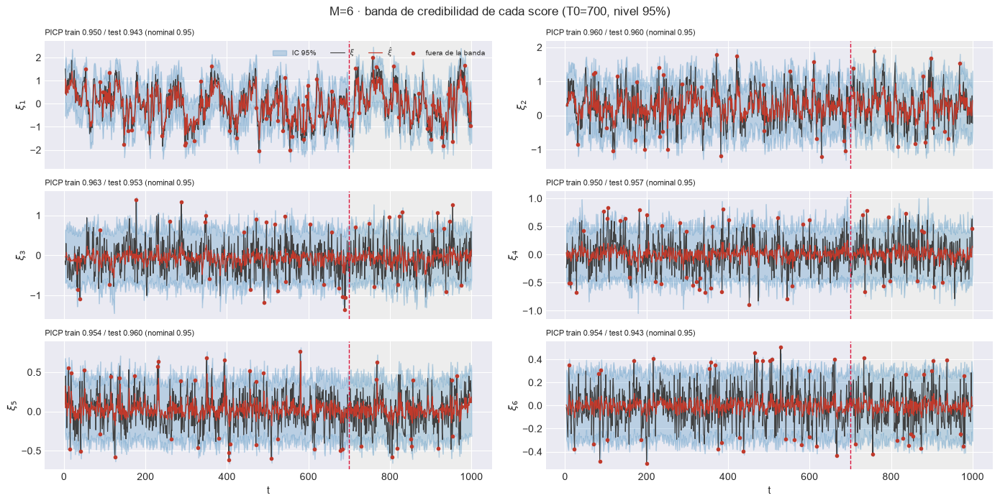

In [24]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


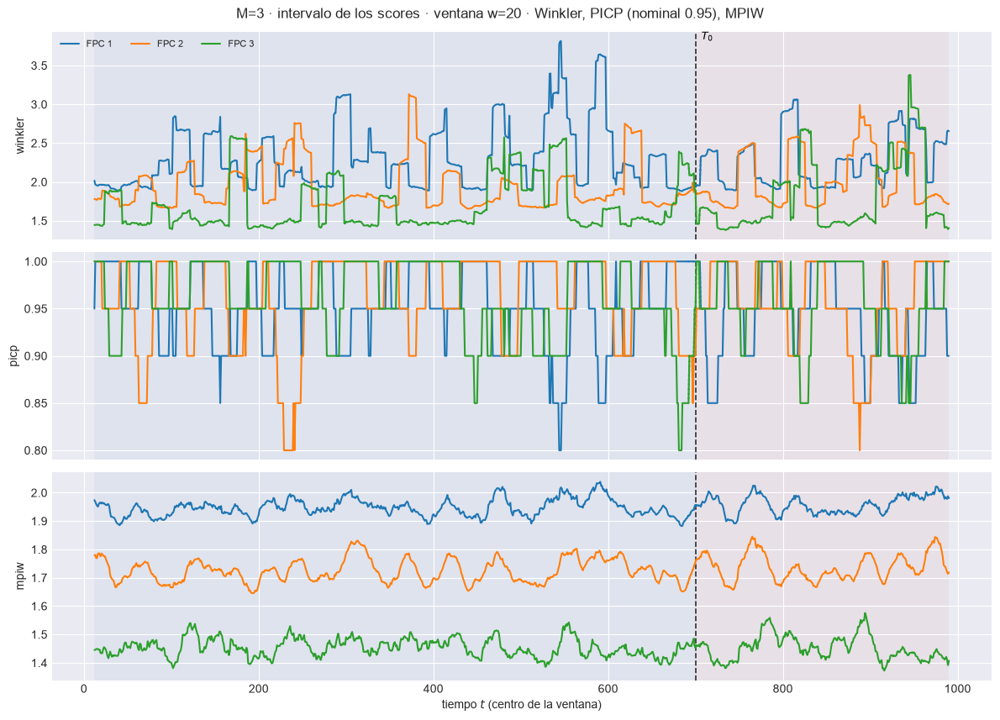

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.939  w=30 test=2.117


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.722  w=30 test=1.726


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m03\93_ventana_scores_intervalo_w30.png


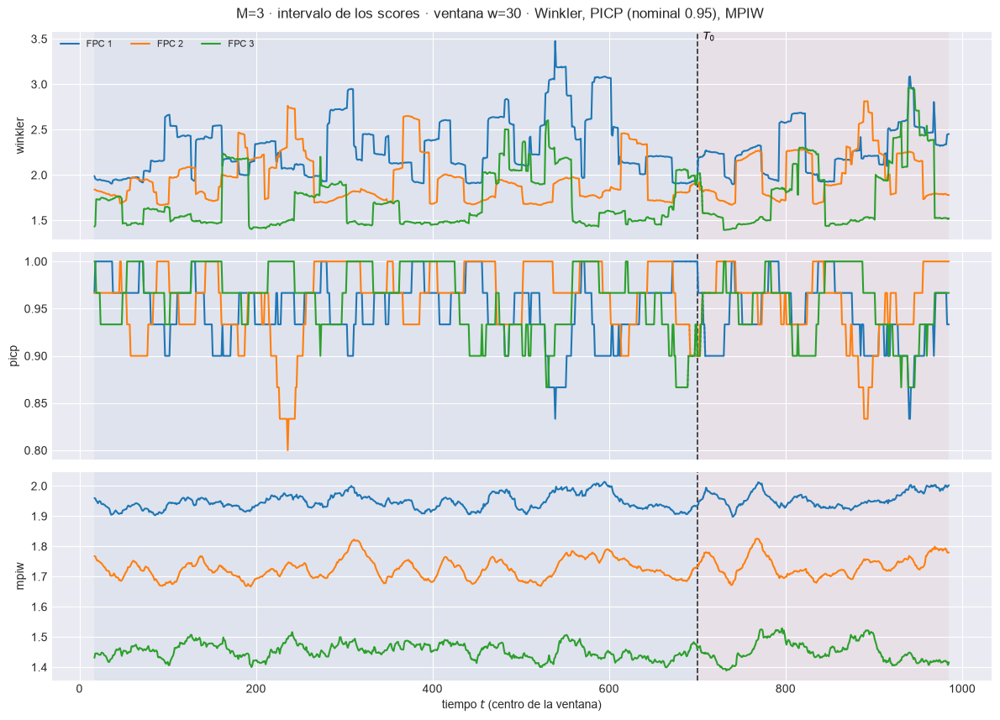

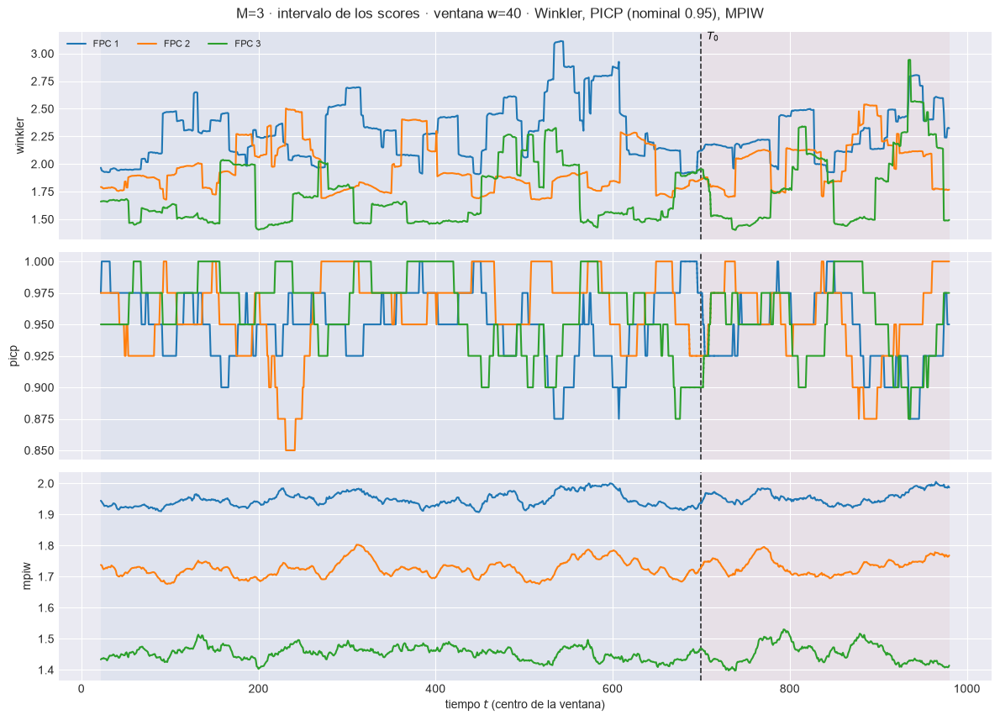

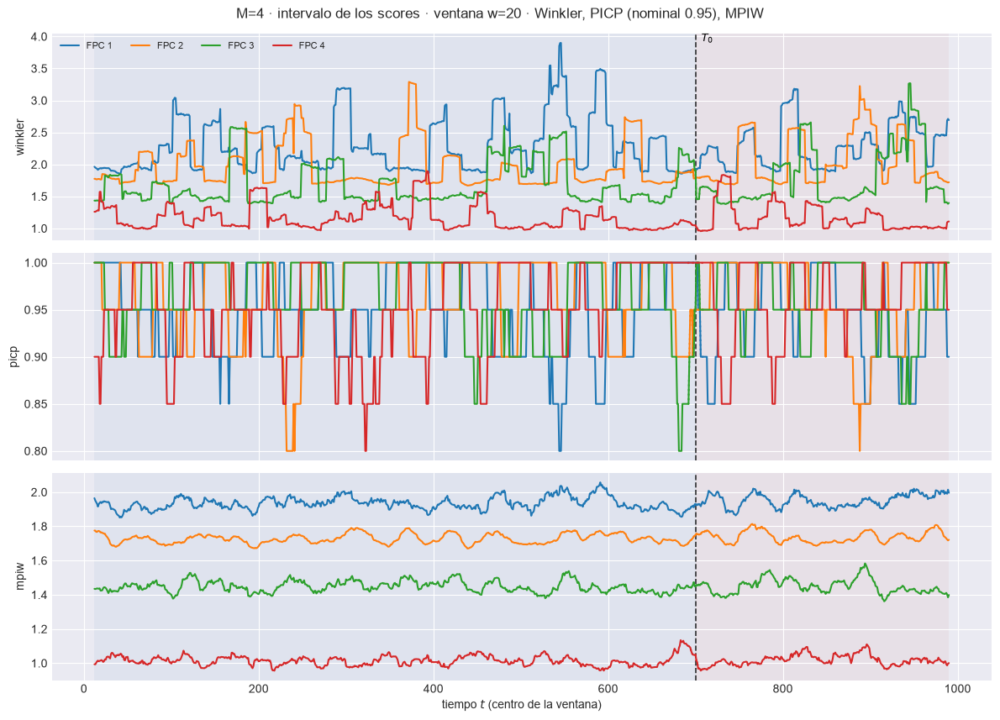

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.746  w=30 test=1.872


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.595  w=30 test=1.611


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m04\93_ventana_scores_intervalo_w30.png


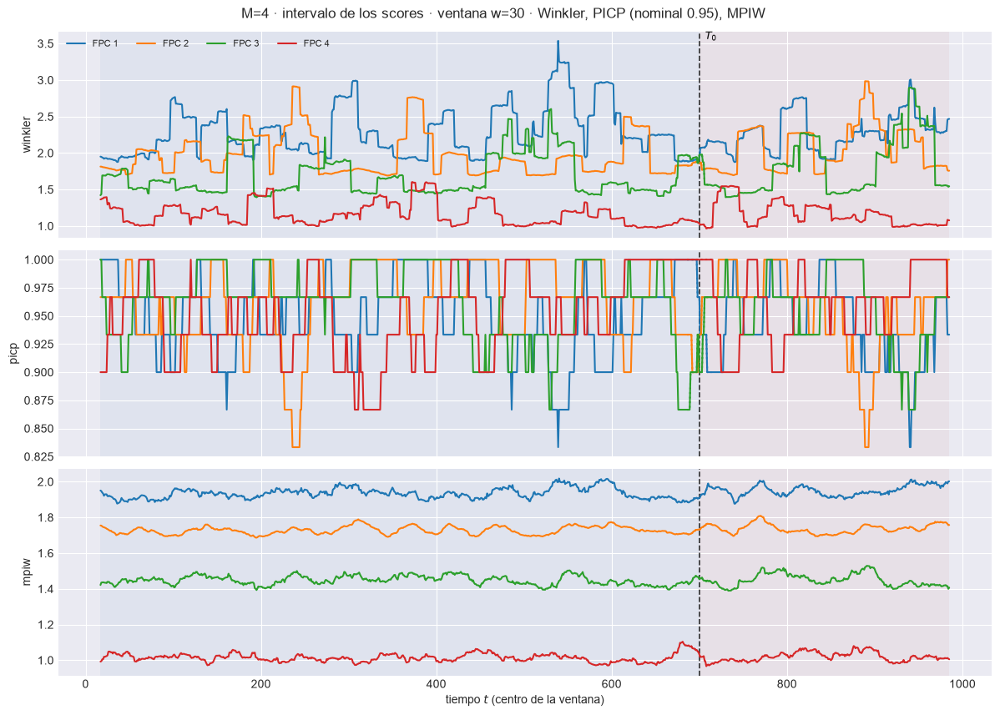

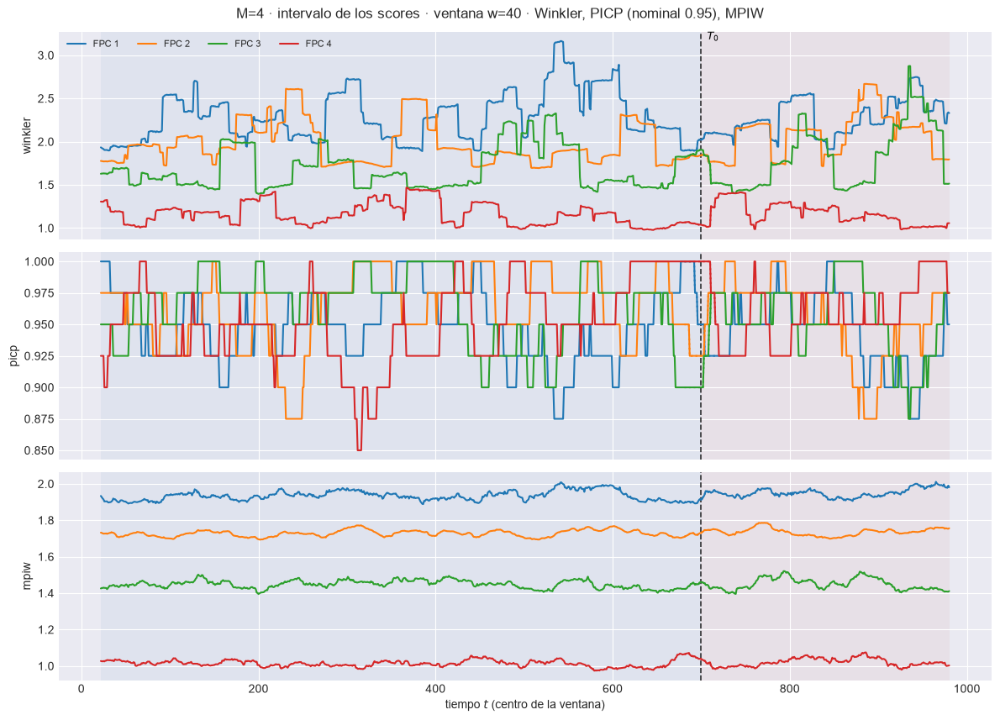

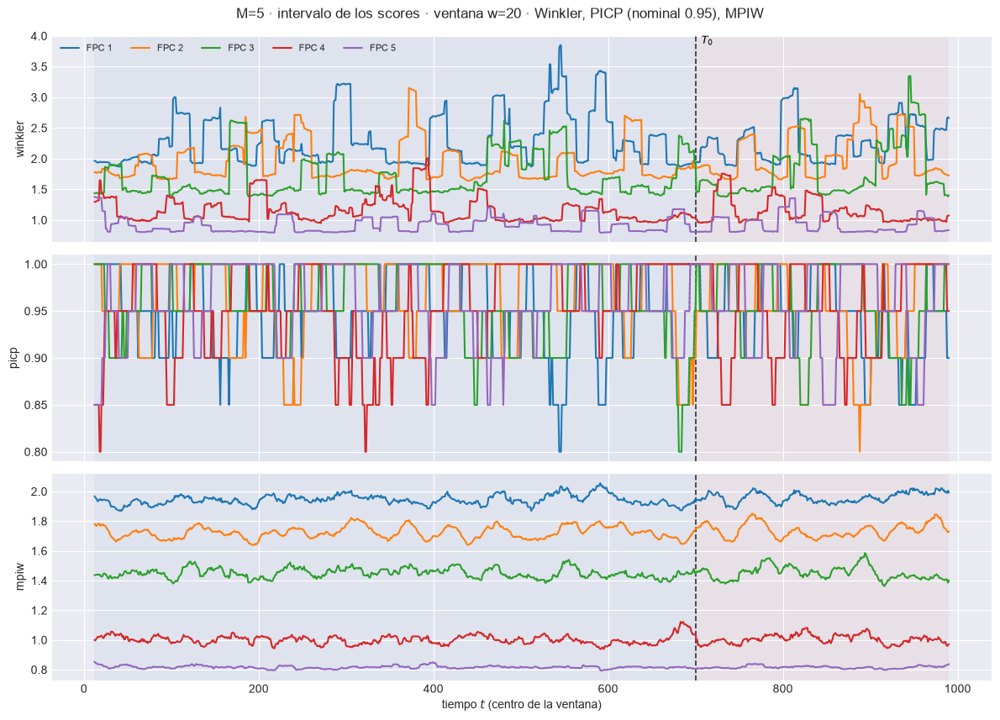

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.593  w=30 test=1.594


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.45  w=30 test=1.444


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m05\93_ventana_scores_intervalo_w30.png


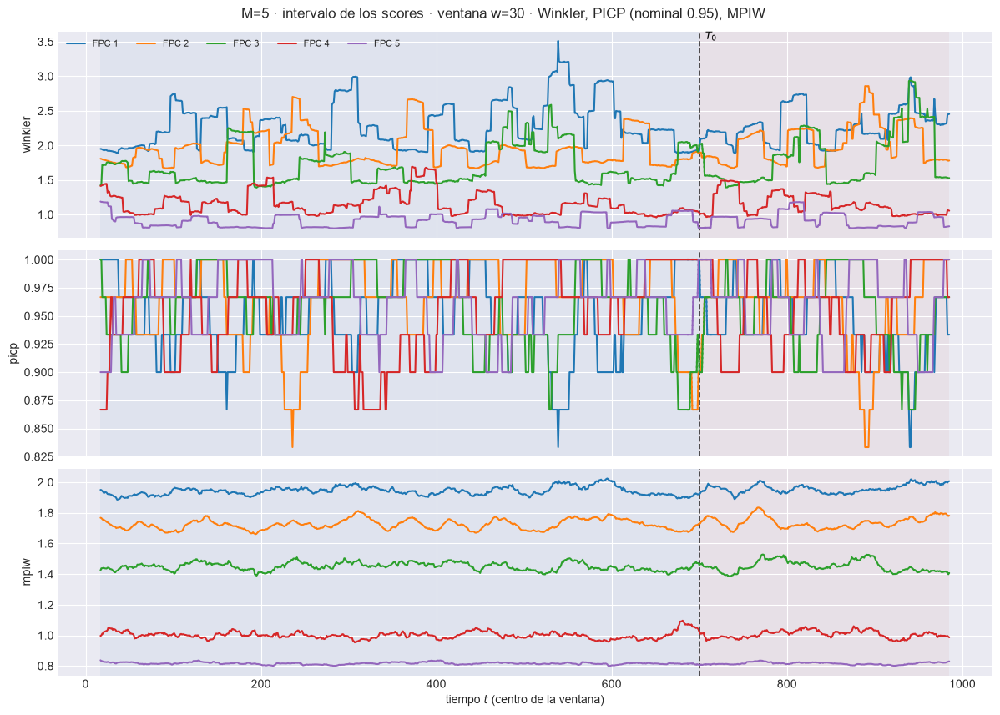

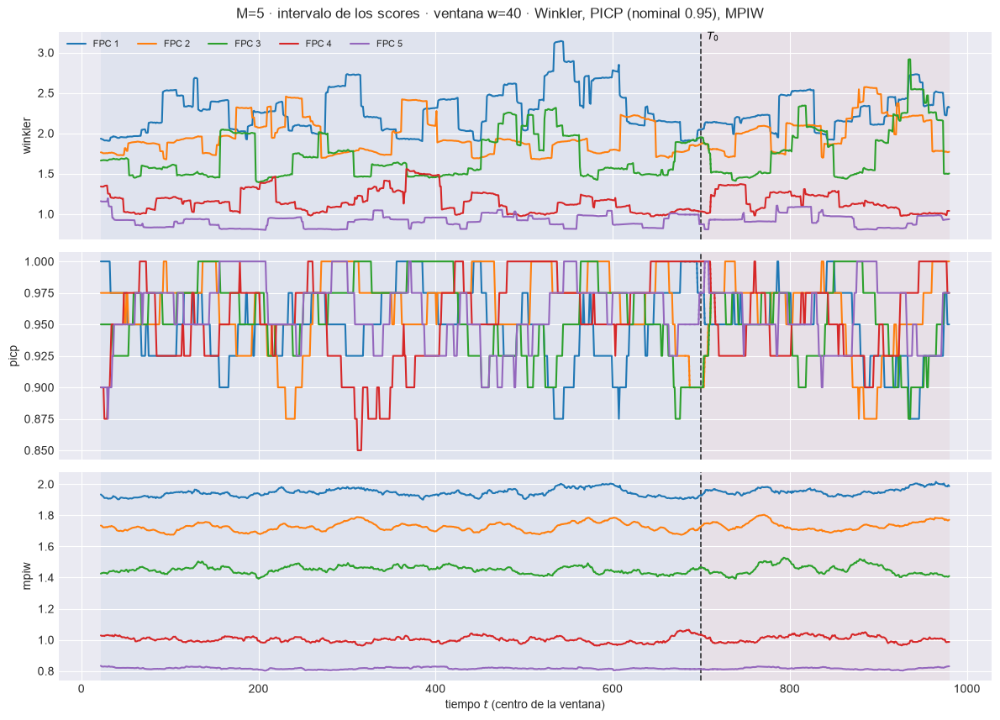

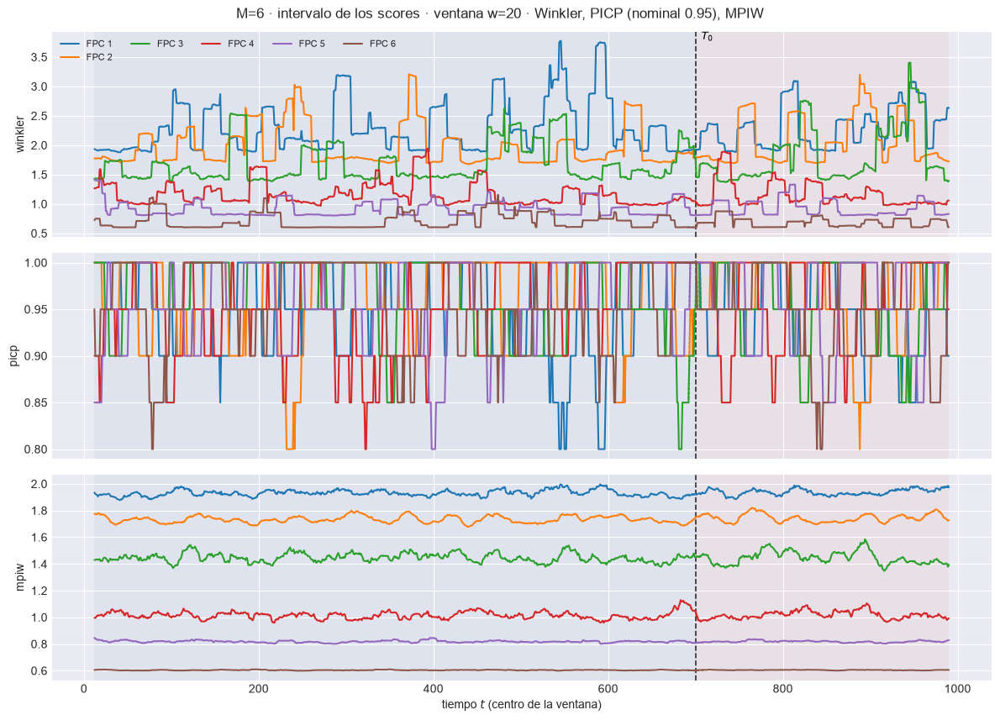

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.436  w=30 test=1.448


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.247  w=30 test=1.225


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_302_chungEscX_1_r01_m06\93_ventana_scores_intervalo_w30.png


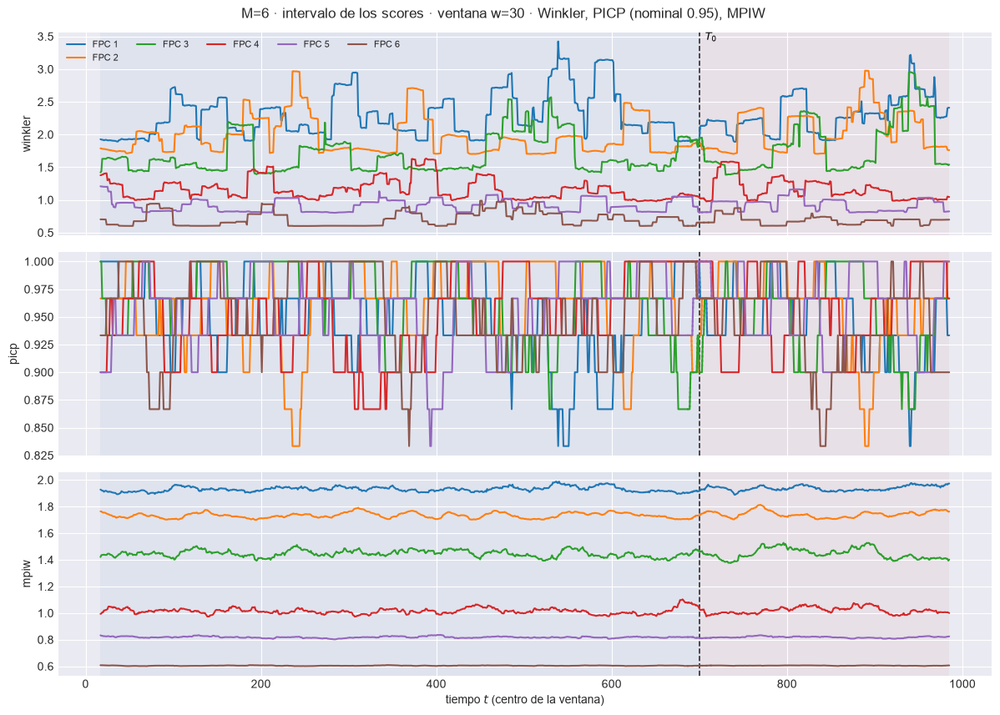

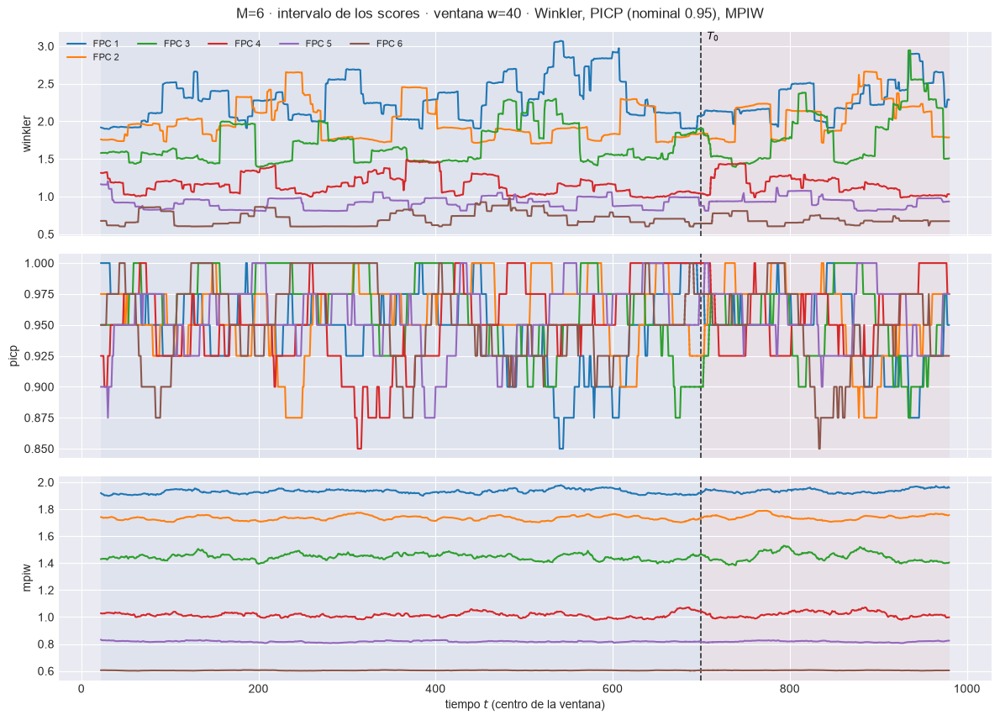

In [25]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

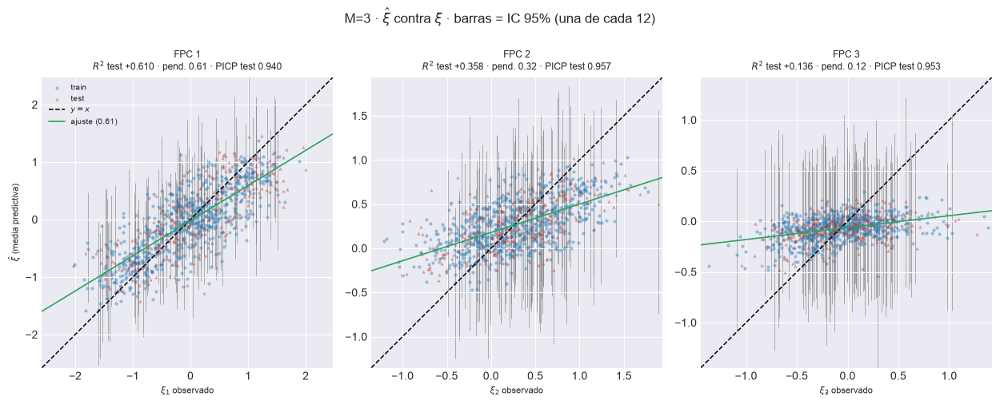

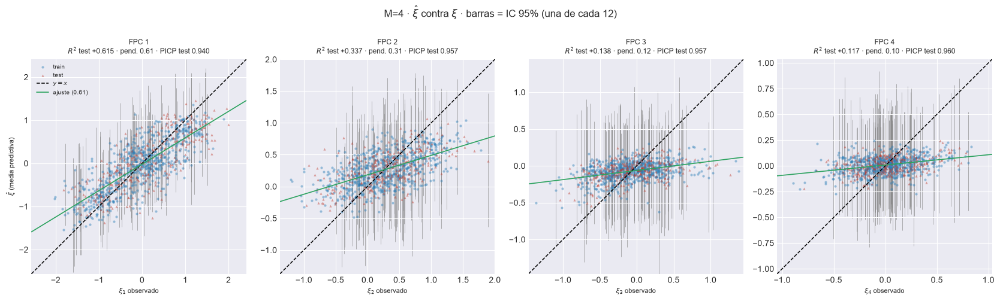

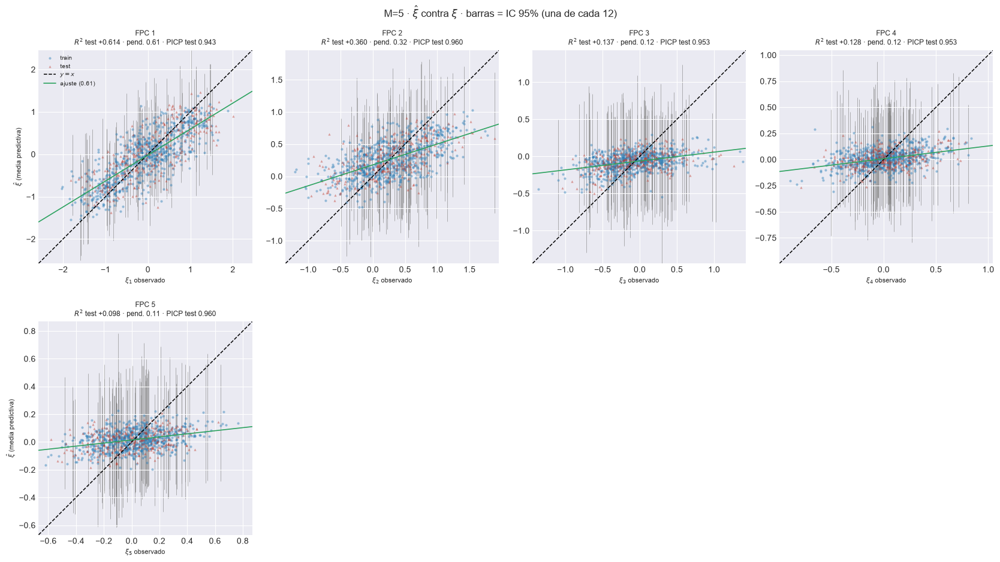

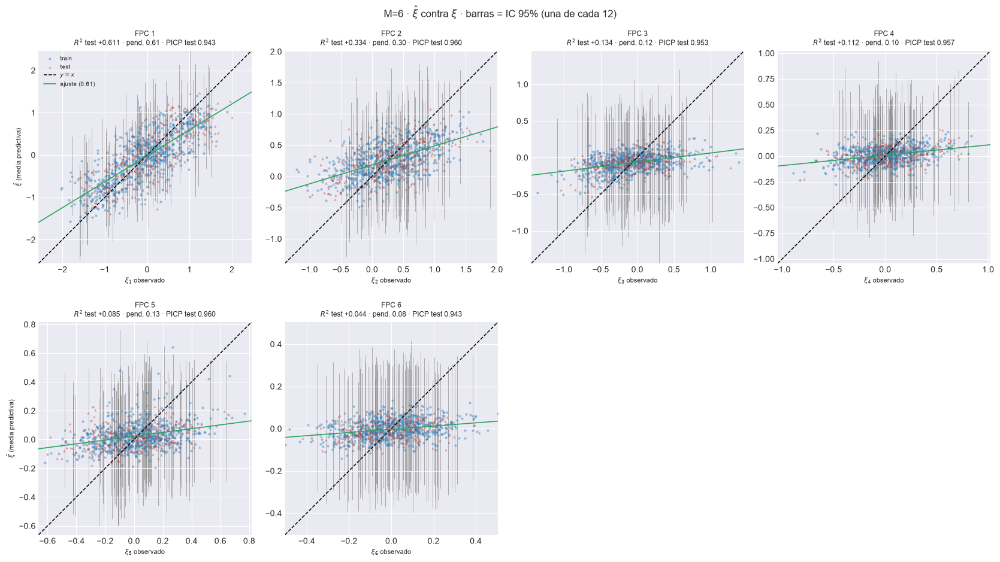

In [26]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas.

In [27]:
# Sobre los N_DETALLE orígenes de la ventana de detalle: cuentas k de N_DETALLE, descriptivas.
wn, MULTI = pesos_normalizados(grilla, PESOS_TAU), {}
for M in M_OK:
    e = EST[M]
    q16, q50, q84 = np.quantile(e["SC_draws"][:, IDX_DET], [0.16, 0.5, 0.84], axis=0)
    sep = np.abs(e["Y_hat"][IDX_DET] - q50) / np.maximum((q84 - q16) / 2.0, 1e-12)   # (N_DETALLE, M)
    por_score = pd.DataFrame({"componente": [f"FPC {c + 1}" for c in e["component_idx"]],
                              "n_origenes": N_DETALLE,
                              f"n_sep_gt_{UMBRAL_SEP}": (sep > UMBRAL_SEP).sum(axis=0),
                              "sep_mediana": np.median(sep, axis=0), "sep_max": sep.max(axis=0)})
    d = distancia_a_muestra_mas_cercana(curvas_draws(e, DIS, IDX_DET), e["X_PRED"]["mediana"][IDX_DET],
                                        grilla, PESOS_TAU, N_REF_NN, SEED_PRED)
    por_origen = pd.DataFrame({"t": T_DET, **d, "l1_esperanza_mediana":
                               np.abs(e["X_pred"][IDX_DET] - e["X_PRED"]["mediana"][IDX_DET]) @ wn,
                               "sep_max_score": sep.max(axis=1)})
    por_score.to_csv(e["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    por_origen.to_csv(e["paths"]["out_report"] / "61_distancia_mediana_muestra.csv", index=False)
    MULTI[M] = (por_score, por_origen)
multi_bar = pd.concat([MULTI[M][0].assign(M=M, t0_detalle=T0_DET) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)

display(multi_bar.pivot(index="componente", columns="M", values=f"n_sep_gt_{UMBRAL_SEP}")
        .reindex([f"FPC {k}" for k in range(1, max(M_OK) + 1)])
        .style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=N_DETALLE, axis=None)
        .set_caption(f"Ventana de detalle (t={T0_DET}..): orígenes, de {N_DETALLE}, con "
                     f"|esperanza − mediana| > {UMBRAL_SEP} sd robusta, por score (descriptivo)"))
display(pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK}).style.format("{:.2f}")
        .set_caption("Ventana de detalle · razón d(mediana, extracción más cercana) / d típica, por origen"))

M,3,4,5,6
componente,,,,
FPC 1,0,0,0,0
FPC 2,0,0,0,0
FPC 3,0,0,0,0
FPC 4,-,0,0,0
FPC 5,-,-,0,0
FPC 6,-,-,-,0


,3,4,5,6
t,,,,
776,0.75,0.18,0.66,0.79
777,0.32,0.77,0.56,0.75
778,0.52,0.39,0.48,0.48
779,0.48,0.93,0.50,0.57
780,0.89,0.53,0.63,0.58
781,1.03,0.86,0.55,0.76
782,0.98,0.53,0.56,0.47
783,0.37,0.44,0.45,0.80
784,0.80,0.84,0.72,0.69


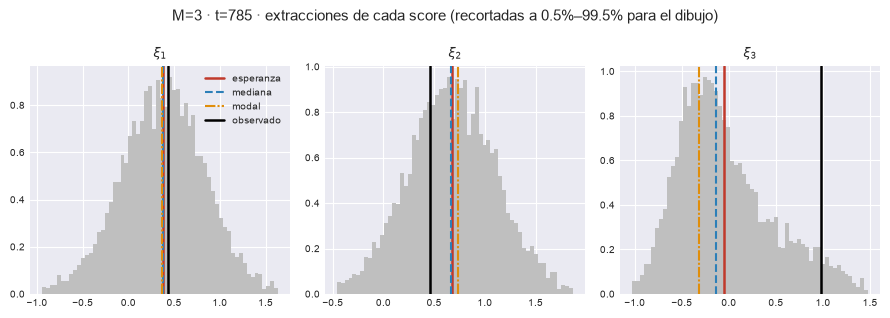

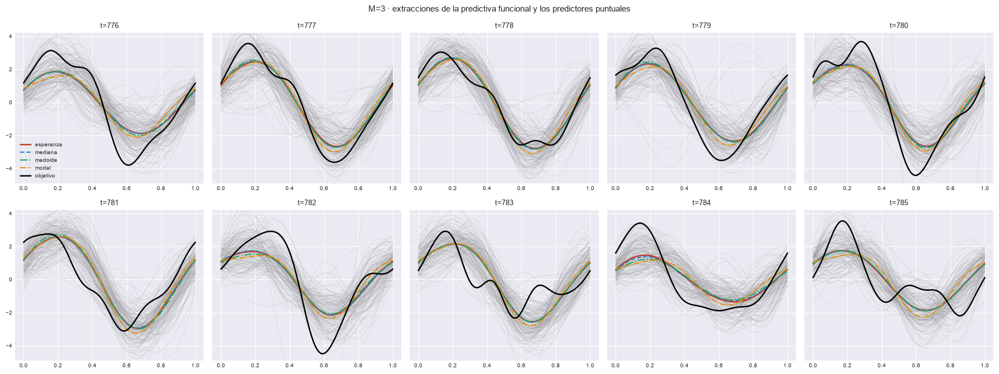

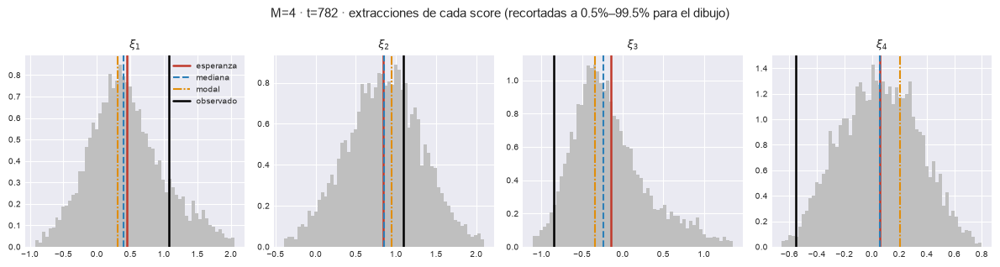

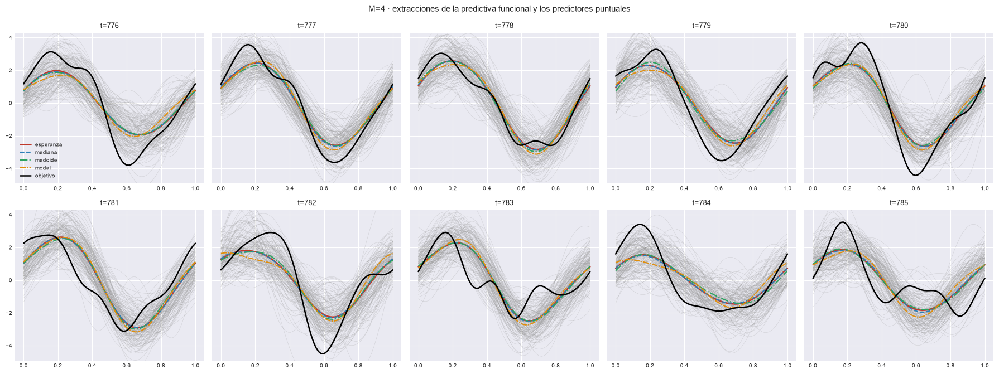

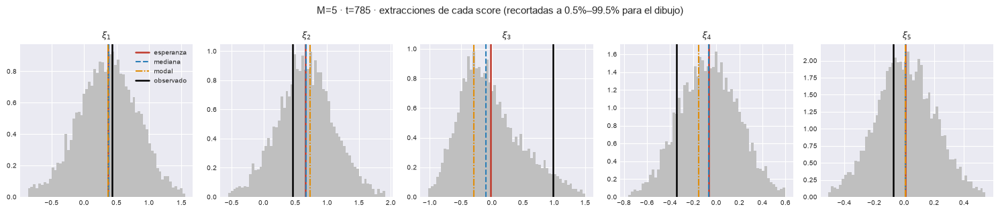

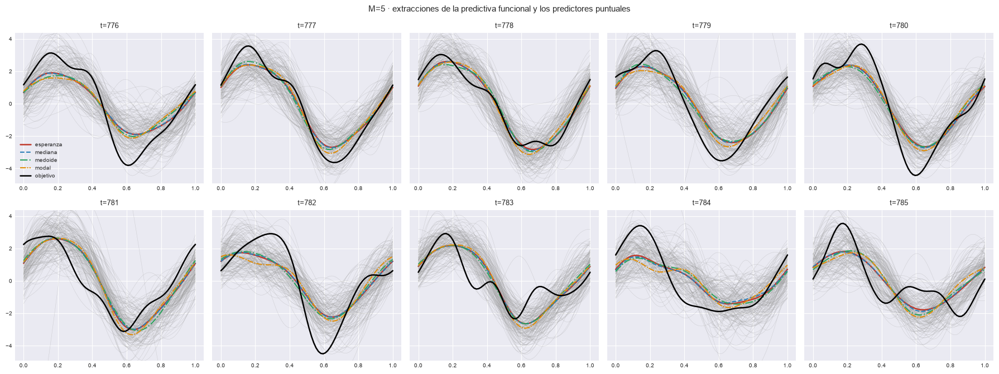

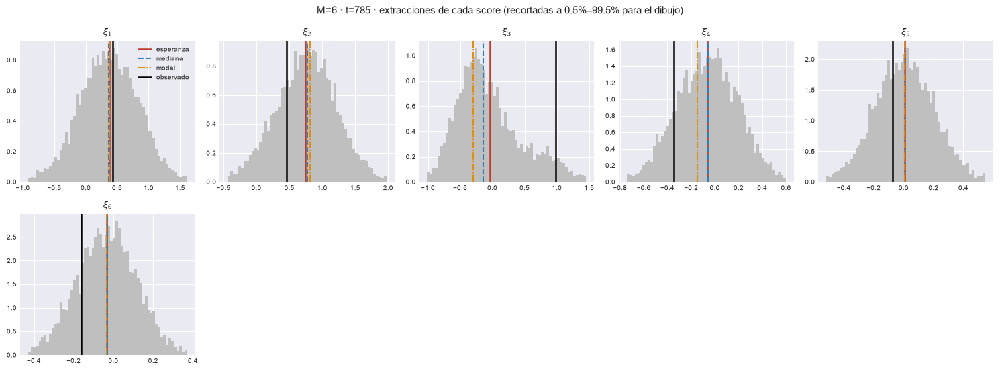

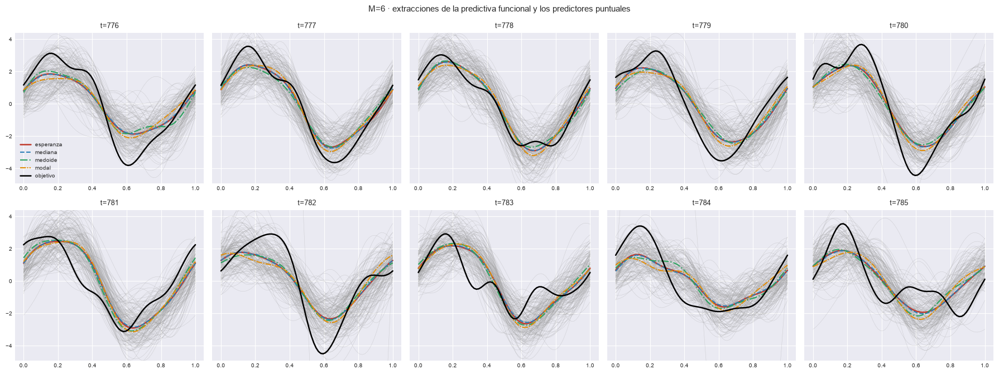

In [28]:
# El origen más multimodal de la ventana: extracciones por score; los N_DETALLE: curvas y predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    i_mm = int(IDX_DET[int(np.argmax(po["sep_max_score"].to_numpy()))])
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_mm, marcas, int(t_orig[i_mm]), M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{int(t_orig[i_mm])}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 sobre toda la serie; §12.2–§12.5 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/998 origenes


    comportamientos: 500/998 origenes


    comportamientos: 750/998 origenes


M= 3: K en test  K=1: 100.0%   (recorte si, 56 s)


    comportamientos: 250/998 origenes


...

    comportamientos: 500/998 origenes


    comportamientos: 750/998 origenes


M= 6: K en test  K=1: 100.0%   (recorte si, 56 s)


M,3,4,5,6
K,,,,
1,100.0%,100.0%,100.0%,100.0%
2,0.0%,0.0%,0.0%,0.0%
3,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%


M,3,4,5,6
K,,,,
1,100.0%,100.0%,100.0%,100.0%
2,0.0%,0.0%,0.0%,0.0%
3,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%


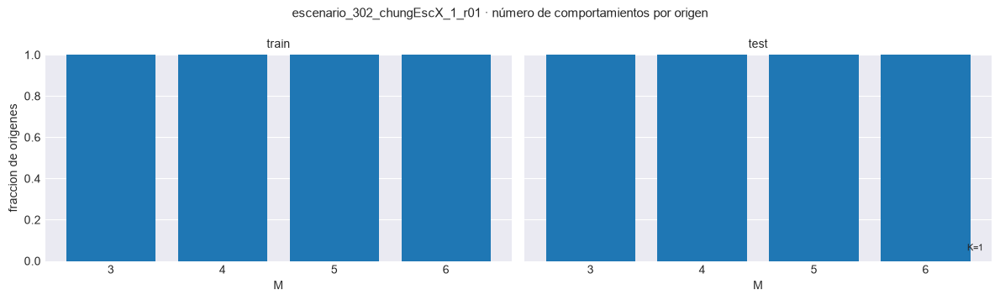

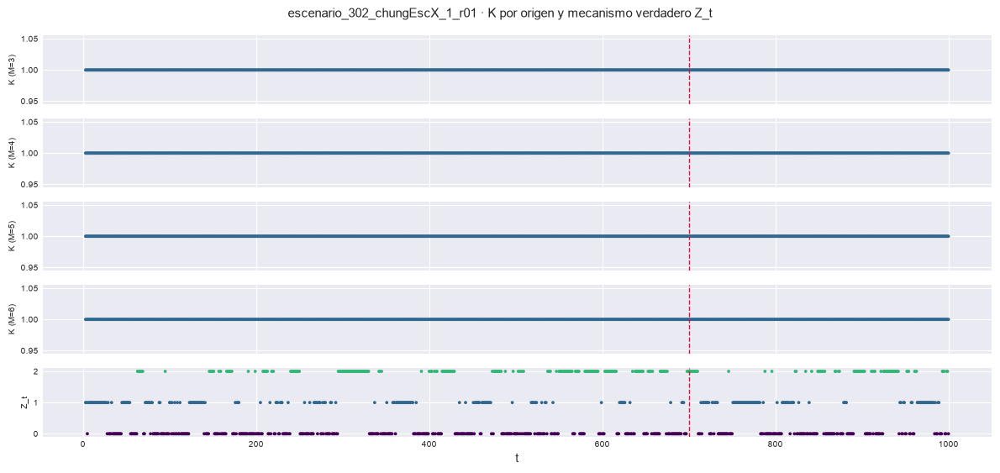

In [29]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

esc   = cargar_escenario(str(EST[M_OK[0]]["paths"]["raw"] / f"escenario_{ESCENARIO_ID}.npz"))
MEC_T = esc["interno_mecanismo"][REPLICA_ID - 1][t_orig - 1]        # Z_t verdadero: 0 centro, 1 alto, 2 bajo
fig = plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0, n_B=MEC_T,
                   titulo=f"{EXPERIMENT_BASE} · K por origen y mecanismo verdadero Z_t")
fig.axes[-1].set_ylabel("Z_t", fontsize=7)                          # la fila extra es Z_t, no "n en B"
fig.savefig(PATH_BARRIDO / "102b_K_serie.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

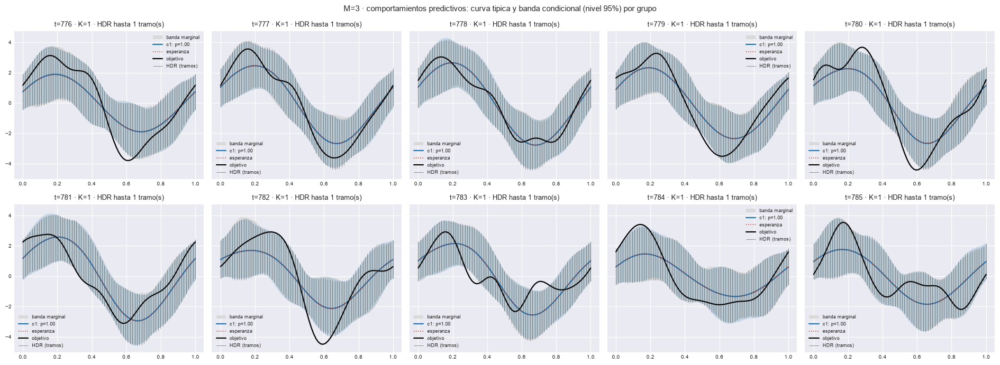

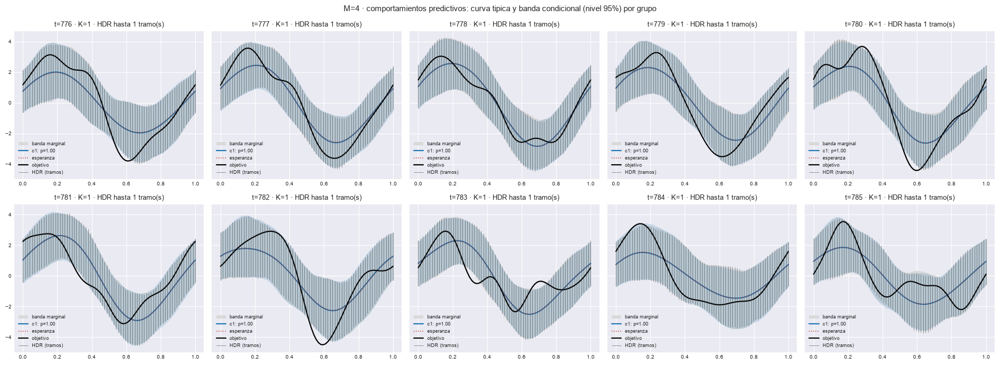

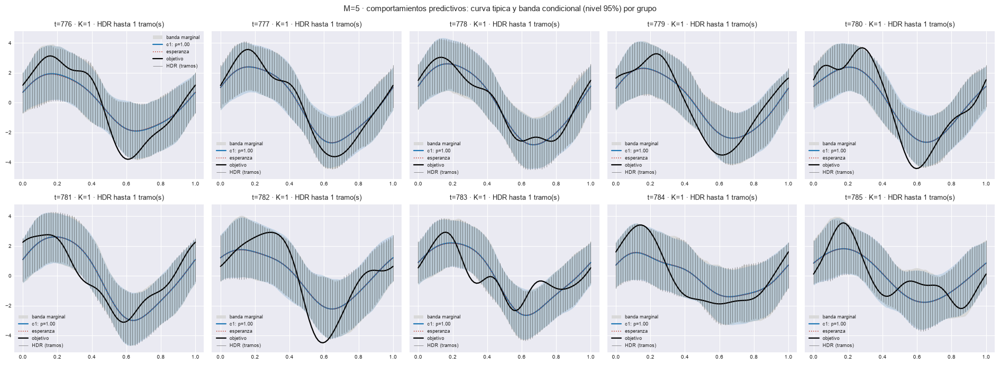

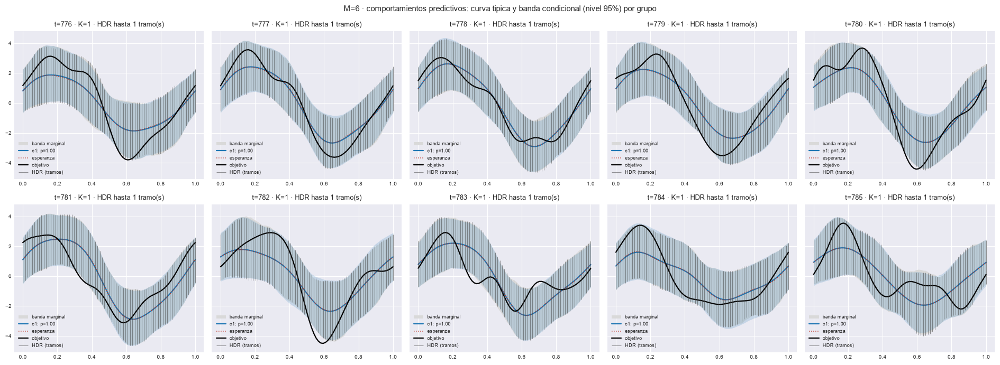

In [30]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M= 3: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 4: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 5: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 6: catalogo global con L=1 comportamiento(s), masas [1.0]


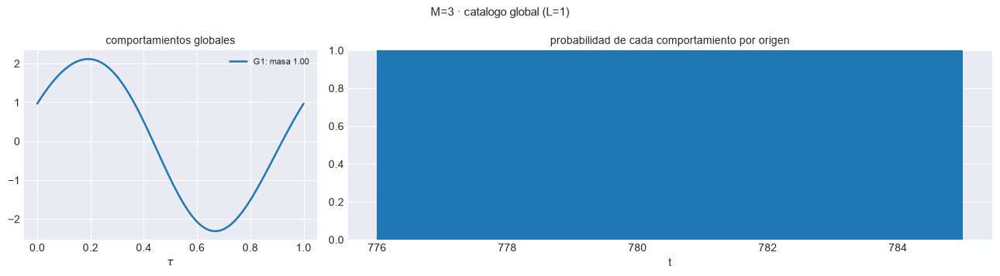

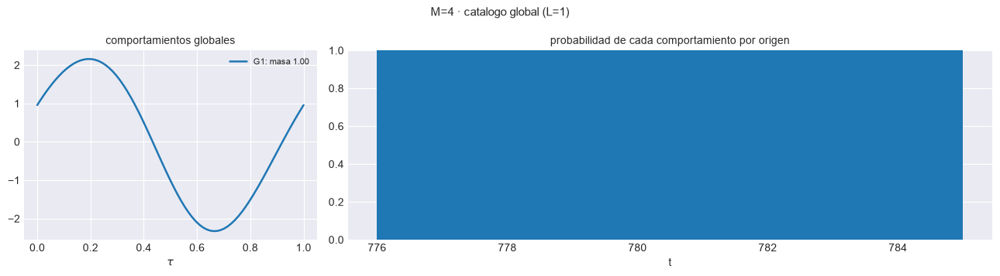

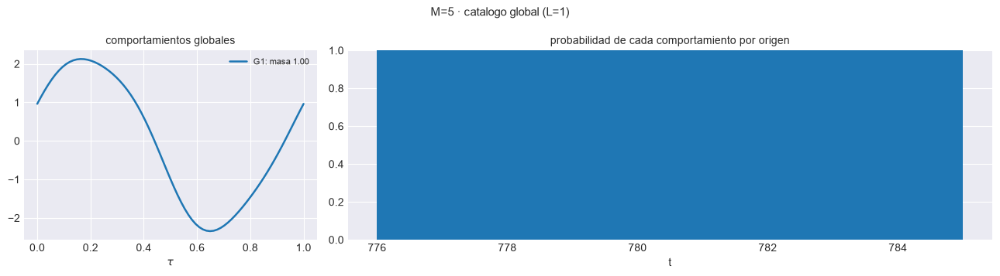

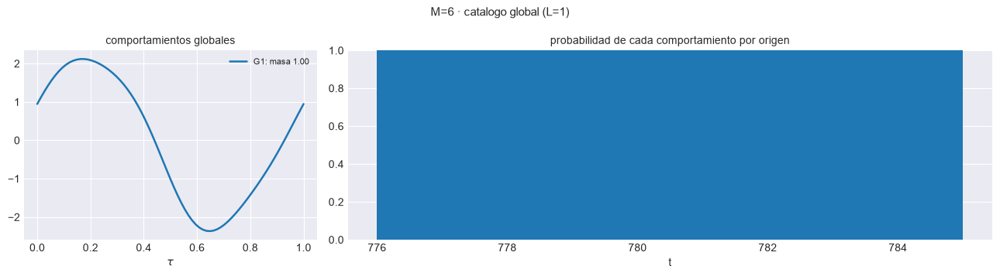

In [31]:
# catalogo_barrido sólo usa es_train para la máscara: la ventana de detalle hace de 'test'.
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 Validación contra el mecanismo verdadero $Z_t$

Ley condicional verdadera por origen (`predictiva_oraculo_C1`): $K$ del oráculo, TV, pureza y acierto de mecanismo; además la HDR y la simultánea contra las mismas construcciones sobre la ley verdadera (tramos, masa cubierta, anchos). Como cuentas.

In [32]:
idx_te = IDX_DET                                                    # ventana de detalle (§3.2)
t_te   = t_orig[idx_te] - 1                                         # índice de curva, base 0
j_te   = np.searchsorted(I_TE, idx_te)                               # las extracciones del criterio (§3.2)
Z_OR, R_OR = Z_OR_TE[:, j_te], R_OR_TE[:, j_te]
R_REAL = esc["interno_mecanismo"][REPLICA_ID - 1][t_te][:, None]    # (n, 1): mecanismo común a los scores
PI_TE  = esc["interno_pi"][REPLICA_ID - 1][t_te]
print(f"ventana de detalle: argmax pi_t acierta Z_t en {int((PI_TE.argmax(axis=1) == R_REAL[:, 0]).sum())} de "
      f"{len(R_REAL)} orígenes · mecanismos (centro, alto, bajo): {np.bincount(R_REAL[:, 0], minlength=3)}")
Y_REAL = esc["interno_scores"][REPLICA_ID - 1][t_te]
VAL_REG = regimen_barrido(EST, M_OK, ORIG, idx_te, Z_OR, R_OR, R_REAL, Y_REAL, PATH_BARRIDO, intervalos=True)

CUENTAS = pd.DataFrame({M: {
    "orígenes": len(d), "K modelo = K oráculo": int((d.K == d.K_oraculo).sum()),
    "K >= 2, modelo": int((d.K >= 2).sum()), "K >= 2, oráculo": int((d.K_oraculo >= 2).sum()),
    "acierto de régimen, modelo": int(np.nansum(d.acierto_modelo)),
    "acierto de régimen, oráculo": int(np.nansum(d.acierto_oraculo))}
    for M, d in ((M, EST[M]["val_regimen"]) for M in M_OK)})
display(CUENTAS.style.set_caption(f"Ventana de detalle (t={T0_DET}..{T0_DET + N_DETALLE - 1}): cuentas sobre "
                                  f"{N_DETALLE} orígenes, descriptivas (104_validacion_regimen_por_M.csv)"))
for M in (m for m in M_DETALLE if m in M_OK):
    display(resumen_regimen(EST[M]["val_regimen"])["confusion"].style
            .set_caption(f"M={M} · K del modelo (filas) contra K del oráculo (columnas), ventana de detalle"))

# Intervalos contra la ley verdadera en la ventana (las mismas columnas de 104, como cuentas).
G_ = len(grilla)
display(pd.DataFrame({M: {
    "(t, tau) con HDR de >1 tramo, modelo": int(round(d.frac_multitramo_modelo.sum() * G_)),
    "(t, tau) con HDR de >1 tramo, oráculo": int(round(d.frac_multitramo_oraculo.sum() * G_)),
    "masa verdadera en la HDR del modelo": float(d.masa_hdr_modelo.mean()),
    "masa verdadera en la simultánea del modelo": float(d.masa_sim_modelo.mean()),
    "ancho HDR modelo / oráculo": float(d.ancho_hdr_modelo.mean() / d.ancho_hdr_oraculo.mean())}
    for M, d in ((M, EST[M]["val_regimen"]) for M in M_OK)}).style.format(precision=3)
    .set_caption(f"Ventana de detalle: intervalos del modelo contra la ley verdadera, sobre "
                 f"{N_DETALLE} x {G_} (t, tau), descriptivo"))


ventana de detalle: argmax pi_t acierta Z_t en 7 de 10 orígenes · mecanismos (centro, alto, bajo): [3 7 0]


M= 3: acuerdo en K 70.0% · TV 0.000 · pureza 0.850 · acierto de regimen modelo 100.0% / oraculo 100.0%
      HDR con mas de un tramo: modelo 0.00% / oraculo 8.13% de las (t, tau) · masa verdadera cubierta: HDR 0.958, simultanea 0.957 (oraculo 0.951 / 0.950)


M= 4: acuerdo en K 70.0% · TV 0.000 · pureza 0.850 · acierto de regimen modelo 100.0% / oraculo 100.0%
      HDR con mas de un tramo: modelo 0.00% / oraculo 5.47% de las (t, tau) · masa verdadera cubierta: HDR 0.957, simultanea 0.954 (oraculo 0.951 / 0.950)


M= 5: acuerdo en K 70.0% · TV 0.000 · pureza 0.850 · acierto de regimen modelo 100.0% / oraculo 100.0%
      HDR con mas de un tramo: modelo 0.00% / oraculo 5.47% de las (t, tau) · masa verdadera cubierta: HDR 0.958, simultanea 0.960 (oraculo 0.951 / 0.950)


M= 6: acuerdo en K 70.0% · TV 0.000 · pureza 0.850 · acierto de regimen modelo 100.0% / oraculo 100.0%
      HDR con mas de un tramo: modelo 0.00% / oraculo 4.27% de las (t, tau) · masa verdadera cubierta: HDR 0.956, simultanea 0.953 (oraculo 0.951 / 0.950)


...

K_oraculo,1,2
K_modelo,,
1,7,3


K_oraculo,1,2
K_modelo,,
1,7,3


K_oraculo,1,2
K_modelo,,
1,7,3


K_oraculo,1,2
K_modelo,,
1,7,3


,3,4,5,6
"(t, tau) con HDR de >1 tramo, modelo",0.000,0.000,0.000,0.000
"(t, tau) con HDR de >1 tramo, oráculo",61.000,41.000,41.000,32.000
masa verdadera en la HDR del modelo,0.958,0.957,0.958,0.956
masa verdadera en la simultánea del modelo,0.957,0.954,0.960,0.953
ancho HDR modelo / oráculo,1.125,1.116,1.107,1.103


### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, verdad del generador y error de cada predictor.

In [33]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
cols_p = sorted([c for c in DETALLE.columns if c.startswith("p_")], key=lambda c: int(c[2:]))
DETALLE = DETALLE[["M", "t", "K"] + cols_p + [c for c in DETALLE.columns if c not in ["M", "t", "K"] + cols_p]]
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,mecanismo_Z,pi_max,K_oraculo_max
t,,,,,,,,,,,,,,,,,,,,
776,1,1.000,1,3.190,0.880,4.522,1.000,3.190,0.880,0.893,1.051,0.904,1.054,0.848,0.994,0.934,1.046,1,0.842,1.000
777,1,1.000,1,3.040,1.000,4.297,1.000,3.037,1.000,0.515,0.624,0.506,0.606,0.485,0.582,0.498,0.579,1,0.935,1.000
778,1,1.000,1,3.125,1.000,4.557,1.000,3.125,1.000,0.367,0.427,0.364,0.427,0.361,0.421,0.441,0.524,1,0.973,1.000
779,1,1.000,1,3.124,0.893,4.252,1.000,3.135,0.907,0.760,0.866,0.752,0.856,0.731,0.845,0.673,0.759,1,0.936,1.000
780,1,1.000,1,3.102,0.787,4.335,1.000,3.109,0.813,0.774,1.004,0.758,0.987,0.763,0.971,0.742,0.920,1,0.944,1.000
781,1,1.000,1,3.092,0.960,4.246,1.000,3.105,0.947,0.886,0.987,0.881,0.983,0.899,1.005,0.857,0.989,1,0.973,1.000
782,1,1.000,1,3.286,0.760,4.627,0.933,3.281,0.787,0.953,1.192,0.960,1.202,0.978,1.221,0.927,1.135,1,0.861,2.000
783,1,1.000,1,2.976,0.800,4.084,0.947,2.981,0.800,0.822,1.035,0.840,1.056,0.818,1.031,0.886,1.118,0,0.885,1.000
784,1,1.000,1,3.170,0.853,4.375,1.000,3.178,0.853,0.899,1.051,0.942,1.094,1.013,1.175,1.004,1.208,0,0.537,2.000


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,mecanismo_Z,pi_max,K_oraculo_max
t,,,,,,,,,,,,,,,,,,,,
776,1,1.000,1,3.374,0.893,4.832,1.000,3.386,0.893,0.843,0.994,0.854,1.000,0.876,1.027,0.936,1.042,1,0.842,1.000
777,1,1.000,1,3.090,1.000,4.453,1.000,3.098,1.000,0.553,0.670,0.533,0.644,0.580,0.711,0.533,0.628,1,0.935,1.000
778,1,1.000,1,3.255,1.000,4.826,1.000,3.270,1.000,0.368,0.432,0.366,0.427,0.354,0.417,0.435,0.504,1,0.973,1.000
779,1,1.000,1,3.232,0.893,4.806,1.000,3.241,0.893,0.775,0.889,0.767,0.874,0.746,0.849,0.735,0.847,1,0.936,1.000
780,1,1.000,1,3.281,0.827,4.821,1.000,3.285,0.880,0.740,0.962,0.737,0.958,0.743,0.953,0.707,0.871,1,0.944,1.000
781,1,1.000,1,3.151,0.933,4.508,1.000,3.152,0.907,0.912,1.017,0.918,1.023,0.899,1.015,0.923,1.049,1,0.973,1.000
782,1,1.000,1,3.612,0.853,5.332,1.000,3.623,0.867,0.966,1.191,0.963,1.181,0.905,1.112,1.042,1.243,1,0.861,2.000
783,1,1.000,1,3.166,0.827,4.592,1.000,3.175,0.827,0.773,1.007,0.779,1.010,0.793,1.025,0.826,1.091,0,0.885,1.000
784,1,1.000,1,3.471,0.920,5.032,1.000,3.483,0.907,0.836,0.993,0.853,1.009,0.899,1.053,0.897,1.111,0,0.537,2.000


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,mecanismo_Z,pi_max,K_oraculo_max
t,,,,,,,,,,,,,,,,,,,,
776,1,1.000,1,3.444,0.893,5.138,1.000,3.451,0.907,0.865,1.003,0.865,1.004,0.894,1.006,0.910,1.013,1,0.842,1.000
777,1,1.000,1,3.201,1.000,4.757,1.000,3.207,1.000,0.487,0.605,0.476,0.594,0.456,0.559,0.434,0.533,1,0.935,1.000
778,1,1.000,1,3.423,1.000,5.181,1.000,3.426,1.000,0.329,0.382,0.331,0.388,0.377,0.426,0.424,0.497,1,0.973,1.000
779,1,1.000,1,3.364,0.933,4.969,1.000,3.366,0.933,0.785,0.902,0.766,0.884,0.743,0.865,0.704,0.808,1,0.936,1.000
780,1,1.000,1,3.261,0.840,4.822,1.000,3.260,0.867,0.747,0.969,0.728,0.943,0.779,0.999,0.713,0.885,1,0.944,1.000
781,1,1.000,1,3.366,0.933,5.024,1.000,3.362,0.933,0.845,0.971,0.849,0.974,0.879,0.993,0.830,0.987,1,0.973,1.000
782,1,1.000,1,3.670,0.880,5.390,1.000,3.675,0.880,0.986,1.213,0.973,1.198,0.943,1.157,1.047,1.262,1,0.861,2.000
783,1,1.000,1,3.200,0.827,4.643,1.000,3.206,0.827,0.738,0.980,0.742,0.987,0.743,0.967,0.796,1.063,0,0.885,1.000
784,1,1.000,1,3.622,0.987,5.470,1.000,3.634,0.960,0.907,1.066,0.950,1.103,0.997,1.184,0.983,1.234,0,0.537,2.000


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,mecanismo_Z,pi_max,K_oraculo_max
t,,,,,,,,,,,,,,,,,,,,
776,1,1.000,1,3.567,0.920,5.192,1.000,3.567,0.960,0.853,0.996,0.858,1.002,0.843,0.977,0.892,1.002,1,0.842,1.000
777,1,1.000,1,3.287,1.000,4.881,1.000,3.297,1.000,0.504,0.614,0.484,0.591,0.572,0.679,0.488,0.595,1,0.935,1.000
778,1,1.000,1,3.351,1.000,5.159,1.000,3.365,1.000,0.370,0.417,0.375,0.421,0.355,0.410,0.445,0.495,1,0.973,1.000
779,1,1.000,1,3.339,0.933,5.096,1.000,3.347,0.947,0.797,0.911,0.788,0.901,0.852,0.964,0.751,0.858,1,0.936,1.000
780,1,1.000,1,3.412,0.907,4.985,1.000,3.412,0.880,0.745,0.962,0.726,0.937,0.768,1.007,0.706,0.868,1,0.944,1.000
781,1,1.000,1,3.422,0.933,5.013,1.000,3.437,0.933,0.892,1.022,0.888,1.012,0.776,0.925,0.909,1.053,1,0.973,1.000
782,1,1.000,1,3.676,0.893,5.441,1.000,3.687,0.880,0.946,1.162,0.932,1.148,0.881,1.095,1.007,1.208,1,0.861,2.000
783,1,1.000,1,3.374,0.853,4.953,1.000,3.378,0.840,0.731,0.980,0.733,0.978,0.775,1.028,0.788,1.064,0,0.885,1.000
784,1,1.000,1,3.534,1.000,5.236,1.000,3.534,1.000,0.877,1.027,0.898,1.046,0.869,1.081,0.917,1.146,0,0.537,2.000
